# Polarized Thomson transport in a slab: paper companion

This portable notebook accompanies the manuscript on the Stokes scattering-order
recursion framework and its high-order eigenmodes. It is a curated copy of the
research notebook, not a replacement for that notebook.

## 0. Scope and execution

Run cells from top to bottom. NumPy, SciPy, Matplotlib and pandas are sufficient;
no XSPEC, remote server, MCRT executable or private compPSc source is required.
The default workflow reads bundled high-resolution transport caches and derived
benchmark/observational exports. Modest finite-order calculations are performed
locally. Expensive eigensolver cache misses require explicit opt-in below.
No cell launches MCRT, spectral fitting, shell commands or network requests.

Optical depth is the **full vertical slab depth**. The sign of Stokes Q follows
the manuscript's local meridian basis. Energy-spectrum figures explicitly state
their photon/energy-density conversion. Observational Q/U are in the sky basis.

**Scientific release caveat:** the colored D/P curves below are single-depth-mode
2-by-2 projected channels, while the gray curves are eigenvalues of the complete
Stokes matrix. Their fit errors refer to the projected channels, not a certified
full-operator branch-tracking calculation. Avoided-crossing claims require a
separate validation before final publication. This notebook does not silently
replace that distinction with an assertion of exact mode tracking.

Only derived compPSc spectra are distributed. Requests for access to the modified
compPSc source may be directed to the corresponding author. The spectral examples
and observational plots reproduce exported results, not a new transport run or fit.


In [1]:
from pathlib import Path
import sys
import hashlib
import json

PUBLIC_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "public_manifest.json").is_file()), None)
if PUBLIC_ROOT is None:
    raise FileNotFoundError("Open this notebook from the paper-notebook folder")
sys.path.insert(0, str(PUBLIC_ROOT))
FIGURE_DIR = PUBLIC_ROOT / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
ALLOW_EXPENSIVE_RECOMPUTE = False
TRANSPORT_REVISION = "795448cd263a8635f34ee2eeba810d8be18f4db89850e8badbf460ac8aa9449b"
from helpers.transport_cache import make_cache
cached_transport = make_cache(PUBLIC_ROOT / "data/transport", TRANSPORT_REVISION,
                              lambda: ALLOW_EXPENSIVE_RECOMPUTE)
for relative, expected in json.loads((PUBLIC_ROOT / "public_manifest.json").read_text())["files_sha256"].items():
    if hashlib.sha256((PUBLIC_ROOT / relative).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Bundled input checksum mismatch: {relative}")
from plot_style import apply_mnras_style, get_double_column_size, get_three_column_size
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
apply_mnras_style()
print("Verified bundled data. No simulations or fits will be launched.")


Verified bundled data. No simulations or fits will be launched.


## 1. Imports and numerical conventions

The core implementation requires only NumPy. If SciPy is available, $\mathrm{scipy.special.expn}$ is used; otherwise a cached Gauss--Legendre quadrature provides a self-contained fallback. All figures use the shared MNRAS configuration in `plot_style.py`.


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from functools import lru_cache
from typing import Literal, Optional

import numpy as np

try:
    from scipy.special import expn as _scipy_expn
except ImportError:
    _scipy_expn = None

np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)
print("E_m backend:", "SciPy expn" if _scipy_expn else "NumPy Gauss-Legendre fallback")


NumPy version: 2.4.1
E_m backend: SciPy expn


## 2. Depth grid and generalized exponential integrals

We use

$$
E_m(x)=\int_0^1u^{m-2}\exp(-x/u)\,{\rm d}u.
$$

For a cell-centred grid with $h=\tau/N$, the exact cell-integrated Toeplitz weights are

$$
I_m(0)=2\left[\frac1m-E_{m+1}(h/2)\right],
$$

$$
I_m(k)=E_{m+1}[(k-1/2)h]-E_{m+1}[(k+1/2)h],\qquad k\ge1.
$$

These weights analytically integrate the logarithmic $E_1$ singularity in the diagonal cell.


In [3]:
@dataclass(frozen=True)
class SlabGrid:
    tau: float
    n_cells: int

    def __post_init__(self) -> None:
        if self.tau <= 0:
            raise ValueError("tau must be positive")
        if self.n_cells < 2:
            raise ValueError("n_cells must be at least 2")

    @property
    def h(self) -> float:
        return self.tau / self.n_cells

    @property
    def centers(self) -> np.ndarray:
        return (np.arange(self.n_cells) + 0.5) * self.h

    @property
    def edges(self) -> np.ndarray:
        return np.arange(self.n_cells + 1) * self.h


@lru_cache(maxsize=None)
def legendre_rule(order: int = 256) -> tuple[np.ndarray, np.ndarray]:
    x, w = np.polynomial.legendre.leggauss(order)
    return 0.5 * (x + 1.0), 0.5 * w


def generalized_expn(m: int, x, quadrature_order: int = 256):
    """Evaluate E_m(x) for scalars or arrays."""
    if m < 1:
        raise ValueError("m must be a positive integer")
    values = np.asarray(x, dtype=float)
    if np.any(values < 0):
        raise ValueError("x must be non-negative")
    scalar_input = values.ndim == 0

    if _scipy_expn is not None:
        result = np.asarray(_scipy_expn(m, values), dtype=float)
        return float(result) if scalar_input else result

    flat = values.reshape(-1)
    result = np.empty_like(flat)
    zero = flat == 0.0
    result[zero] = np.inf if m == 1 else 1.0 / (m - 1)

    if np.any(~zero):
        u, w = legendre_rule(quadrature_order)
        weighted_power = w * u ** (m - 2)
        positive_x = flat[~zero]
        result[~zero] = np.exp(-positive_x[:, None] / u[None, :]) @ weighted_power

    result = result.reshape(values.shape)
    return float(result) if scalar_input else result


def cell_integrated_kernel(grid: SlabGrid, m: int) -> np.ndarray:
    """Return I_m(k), k=0,...,N-1, for a symmetric depth kernel."""
    h = grid.h
    k = np.arange(grid.n_cells)
    weights = np.empty(grid.n_cells)
    weights[0] = 2.0 * (1.0 / m - generalized_expn(m + 1, 0.5 * h))
    if grid.n_cells > 1:
        left = (k[1:] - 0.5) * h
        right = (k[1:] + 0.5) * h
        weights[1:] = generalized_expn(m + 1, left) - generalized_expn(m + 1, right)
    return weights


test_grid = SlabGrid(tau=1.0, n_cells=128)
print(f"Grid: tau={test_grid.tau}, N={test_grid.n_cells}, h={test_grid.h:.6g}")
print("First five I_1 weights:", cell_integrated_kernel(test_grid, 1)[:5])


Grid: tau=1.0, N=128, h=0.0078125
First five I_1 weights: [0.04664  0.033811 0.028186 0.025033 0.022829]


## 3. High-performance two-component recursion

Both models evolve $\boldsymbol y_n=(a_n,b_n)^{\rm T}$. The scalar operator is

$$
\mathbb K_{\rm sc}=\frac{3}{16}
\begin{pmatrix}
3\mathcal K_1-\mathcal K_3 & 3\mathcal K_3-\mathcal K_5\\
-\mathcal K_1+3\mathcal K_3 & -\mathcal K_3+3\mathcal K_5
\end{pmatrix},
$$

whereas the polarized operator is

$$
\mathbb K_{\rm pol}=\frac{3}{16}
\begin{pmatrix}
3\mathcal K_1-\mathcal K_3 & -\mathcal K_1+5\mathcal K_3-2\mathcal K_5\\
-\mathcal K_1+3\mathcal K_3 & 3\mathcal K_1-7\mathcal K_3+6\mathcal K_5
\end{pmatrix}.
$$

For the polarized state,

$$
\Psi_{I,n}=a_n+b_n\mu^2,\qquad
\Psi_{Q,n}=b_n(1-\mu^2).
$$

The depth matrices are symmetric Toeplitz matrices. Each is embedded in a length-$2N$ circulant array and transformed once. One recursion step then requires two forward FFTs, a $2\times2$ multiplication at every Fourier mode, and two inverse FFTs.


In [4]:
def symmetric_toeplitz_fft(first_column: np.ndarray) -> np.ndarray:
    first_column = np.asarray(first_column, dtype=float)
    embedding = np.concatenate([first_column, [0.0], first_column[:0:-1]])
    return np.fft.rfft(embedding)


@dataclass
class FFTTwoComponentOperator:
    grid: SlabGrid
    kind: Literal["scalar", "polarized"]
    kernel_fft: np.ndarray

    @classmethod
    def build(cls, grid: SlabGrid, kind: Literal["scalar", "polarized"]):
        i1 = cell_integrated_kernel(grid, 1)
        i3 = cell_integrated_kernel(grid, 3)
        i5 = cell_integrated_kernel(grid, 5)

        if kind == "scalar":
            columns = np.array([
                [3.0 * i1 - i3, 3.0 * i3 - i5],
                [-i1 + 3.0 * i3, -i3 + 3.0 * i5],
            ]) * (3.0 / 16.0)
        elif kind == "polarized":
            columns = np.array([
                [3.0 * i1 - i3, -i1 + 5.0 * i3 - 2.0 * i5],
                [-i1 + 3.0 * i3, 3.0 * i1 - 7.0 * i3 + 6.0 * i5],
            ]) * (3.0 / 16.0)
        else:
            raise ValueError("kind must be 'scalar' or 'polarized'")

        kernel_fft = np.empty((2, 2, grid.n_cells + 1), dtype=complex)
        for row in range(2):
            for col in range(2):
                kernel_fft[row, col] = symmetric_toeplitz_fft(columns[row, col])
        return cls(grid=grid, kind=kind, kernel_fft=kernel_fft)

    def step(self, a: np.ndarray, b: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Advance (a_n,b_n) by one scattering in O(N log N)."""
        state = np.stack([np.asarray(a, dtype=float), np.asarray(b, dtype=float)])
        if state.shape != (2, self.grid.n_cells):
            raise ValueError(f"expected two arrays of length {self.grid.n_cells}")

        padded = np.zeros((2, 2 * self.grid.n_cells))
        padded[:, : self.grid.n_cells] = state
        state_fft = np.fft.rfft(padded, axis=1)
        next_fft = np.einsum("ijf,jf->if", self.kernel_fft, state_fft, optimize=True)
        next_state = np.fft.irfft(next_fft, n=2 * self.grid.n_cells, axis=1)
        return next_state[0, : self.grid.n_cells], next_state[1, : self.grid.n_cells]


scalar_operator = FFTTwoComponentOperator.build(test_grid, "scalar")
polarized_operator = FFTTwoComponentOperator.build(test_grid, "polarized")
print("Built both FFT operators; spectral tensor shape:", scalar_operator.kernel_fft.shape)


Built both FFT operators; spectral tensor shape: (2, 2, 129)


## 4. Three principal seed-photon sources

All initializers return the post-first-scattering coefficients $(a_1,b_1)$ in the polarization-manuscript normalization, together with exact unscattered probabilities. The same initial state can be passed to either recursion.

### 4.1. Normally incident unpolarized beam

$$
a_1=b_1=\frac38e^{-t},\qquad P_0^+=e^{-\tau},\quad P_0^-=0.
$$

### 4.2. Unpolarized Lambert injection from the lower boundary

For $p_I(\mu)=2\mu$,

$$
a_1=\frac38[3E_2(t)-E_4(t)],\qquad
b_1=\frac38[3E_4(t)-E_2(t)],
$$

and $P_0^+=2E_3(\tau)$.

### 4.3. Uniform isotropic internal source

For $q(t)=1/\tau$, $p_I=1/2$, define

$$
J_m(t)=\frac2m-E_{m+1}(t)-E_{m+1}(\tau-t).
$$

Then

$$
a_1=\frac{3}{32\tau}(3J_1-J_3),\qquad
b_1=\frac{3}{32\tau}(3J_3-J_1).
$$


In [5]:
SourceKind = Literal["normal_beam", "lambert", "uniform_internal"]
Boundary = Literal["+", "-"]


@dataclass
class SourceInitialization:
    grid: SlabGrid
    kind: SourceKind
    name: str
    a1: np.ndarray
    b1: np.ndarray
    p0_plus: float
    p0_minus: float

    def zero_order_intensity(self, mu, boundary: Boundary) -> Optional[np.ndarray]:
        """Return dP_0^boundary/dmu when it is a regular function.

        The normal beam is a delta function at mu=1, so None is returned.
        """
        mu = np.asarray(mu, dtype=float)
        if np.any((mu <= 0) | (mu > 1)):
            raise ValueError("mu must lie in (0,1]")
        tau = self.grid.tau

        if self.kind == "normal_beam":
            return None
        if self.kind == "lambert":
            return 2.0 * mu * np.exp(-tau / mu) if boundary == "+" else np.zeros_like(mu)
        if self.kind == "uniform_internal":
            return mu * (-np.expm1(-tau / mu)) / (2.0 * tau)
        raise RuntimeError("unknown source kind")


def source_normal_beam(grid: SlabGrid) -> SourceInitialization:
    t = grid.centers
    a1 = (3.0 / 8.0) * np.exp(-t)
    b1 = a1.copy()
    return SourceInitialization(
        grid, "normal_beam", "normal beam", a1, b1, np.exp(-grid.tau), 0.0
    )


def source_lambert(grid: SlabGrid) -> SourceInitialization:
    t = grid.centers
    e2 = generalized_expn(2, t)
    e4 = generalized_expn(4, t)
    a1 = (3.0 / 8.0) * (3.0 * e2 - e4)
    b1 = (3.0 / 8.0) * (3.0 * e4 - e2)
    return SourceInitialization(
        grid, "lambert", "Lambert lower boundary", a1, b1,
        2.0 * generalized_expn(3, grid.tau), 0.0
    )


def source_uniform_isotropic_internal(grid: SlabGrid) -> SourceInitialization:
    t = grid.centers
    j1 = 2.0 - generalized_expn(2, t) - generalized_expn(2, grid.tau - t)
    j3 = 2.0 / 3.0 - generalized_expn(4, t) - generalized_expn(4, grid.tau - t)
    a1 = (3.0 / (32.0 * grid.tau)) * (3.0 * j1 - j3)
    b1 = (3.0 / (32.0 * grid.tau)) * (3.0 * j3 - j1)
    p0_each = (0.5 - generalized_expn(3, grid.tau)) / (2.0 * grid.tau)
    return SourceInitialization(
        grid, "uniform_internal", "uniform isotropic internal", a1, b1,
        p0_each, p0_each
    )


sources = {
    "beam": source_normal_beam(test_grid),
    "lambert": source_lambert(test_grid),
    "internal": source_uniform_isotropic_internal(test_grid),
}
for key, source in sources.items():
    print(f"{key:8s}: P0+={source.p0_plus:.8f}, P0-={source.p0_minus:.8f}")


beam    : P0+=0.36787944, P0-=0.00000000
lambert : P0+=0.21938393, P0-=0.00000000
internal: P0+=0.19515402, P0-=0.19515402


## 5. Escape projections and observables

For piecewise-constant $a_n,b_n$, the angular projection is integrated exactly over every depth cell. At the lower boundary,

$$
R_j^-(\mu)=\mu\left[e^{-jh/\mu}-e^{-(j+1)h/\mu}\right],
$$

and $R_j^+(\mu)=R_{N-1-j}^-(\mu)$.

For the polarized recursion,

$$
I_n^\pm(\mu)=\sum_j(a_{n,j}+b_{n,j}\mu^2)R_j^\pm(\mu),
$$

$$
Q_n^\pm(\mu)=(1-\mu^2)\sum_jb_{n,j}R_j^\pm(\mu).
$$

The output contains the normalized angular distribution $\Phi=I/P$, signed polarization fraction $\Pi=Q/I$, and non-negative polarization degree ${\rm PD}=|Q|/I$. Here $Q>0$ means the electric vector is preferentially parallel to the slab surface.


In [6]:
def escape_cell_weights(grid: SlabGrid, mu: np.ndarray, boundary: Boundary) -> np.ndarray:
    mu = np.asarray(mu, dtype=float)
    if np.any((mu <= 0) | (mu > 1)):
        raise ValueError("mu must lie in (0,1]")
    attenuation = np.exp(-grid.edges[:, None] / mu[None, :])
    lower = mu[None, :] * (attenuation[:-1] - attenuation[1:])
    return lower if boundary == "-" else lower[::-1]


def escape_stokes(a, b, grid: SlabGrid, mu, boundary: Boundary, polarized: bool = True):
    """Return I_n and Q_n per unit mu at one free surface."""
    mu = np.atleast_1d(np.asarray(mu, dtype=float))
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    weights = escape_cell_weights(grid, mu, boundary)
    intensity = np.sum((a[:, None] + b[:, None] * mu[None, :] ** 2) * weights, axis=0)
    if polarized:
        q_stokes = (1.0 - mu**2) * np.sum(b[:, None] * weights, axis=0)
    else:
        q_stokes = np.zeros_like(intensity)
    return intensity, q_stokes


@lru_cache(maxsize=None)
def probability_cell_weights(tau: float, n_cells: int):
    grid = SlabGrid(tau, n_cells)
    edges = grid.edges
    s2_minus = generalized_expn(3, edges[:-1]) - generalized_expn(3, edges[1:])
    s4_minus = generalized_expn(5, edges[:-1]) - generalized_expn(5, edges[1:])
    return s2_minus, s4_minus, s2_minus[::-1], s4_minus[::-1]


def escape_probabilities(a, b, grid: SlabGrid) -> tuple[float, float, float]:
    """Return (P_n^+, P_n^-, P_n) with no extra 2*pi factor."""
    s2m, s4m, s2p, s4p = probability_cell_weights(grid.tau, grid.n_cells)
    p_minus = float(np.dot(a, s2m) + np.dot(b, s4m))
    p_plus = float(np.dot(a, s2p) + np.dot(b, s4p))
    return p_plus, p_minus, p_plus + p_minus


def survival_probability(a, b, grid: SlabGrid) -> float:
    """M_n: probability that a photon has undergone at least n scatterings."""
    return float(2.0 * grid.h * np.sum(np.asarray(a) + np.asarray(b) / 3.0))


def angular_diagnostics(a, b, grid: SlabGrid, mu, boundary: Boundary, polarized: bool = True):
    """Return I, Q, Phi=I/P, signed Pi=Q/I, and PD=|Q|/I."""
    mu = np.atleast_1d(np.asarray(mu, dtype=float))
    intensity, q_stokes = escape_stokes(a, b, grid, mu, boundary, polarized)
    p_plus, p_minus, _ = escape_probabilities(a, b, grid)
    probability = p_plus if boundary == "+" else p_minus
    phi = intensity / probability if probability > 0 else np.full_like(intensity, np.nan)
    pi_signed = np.divide(q_stokes, intensity, out=np.zeros_like(q_stokes), where=intensity > 0)
    return {
        "mu": mu,
        "I": intensity,
        "Q": q_stokes,
        "P": probability,
        "Phi": phi,
        "Pi_signed": pi_signed,
        "PD": np.abs(pi_signed),
    }


sample = sources["lambert"]
print("Lambert first-scattering (P1+, P1-, P1):",
      escape_probabilities(sample.a1, sample.b1, sample.grid))
print("Lambert M1:", survival_probability(sample.a1, sample.b1, sample.grid))


Lambert first-scattering (P1+, P1-, P1): (0.11903523881322481, 0.1995505808630277, 0.31858581967625255)
Lambert M1: 0.7805837813667664


## 6. Scattering-order driver and probability tracking

The driver stores $(a_n,b_n)$ for $n=1,\ldots,n_{\max}$. The order-distribution function prepends the exact unscattered probabilities and returns $P_n^+$, $P_n^-$, and $P_n$.

The conservation identity used below is

$$
M_n=P_n+M_{n+1},
$$

where $M_n$ is the integrated post-$n$-th-scattering state.


In [7]:
@dataclass
class RecursionRun:
    operator: FFTTwoComponentOperator
    source: SourceInitialization
    a: np.ndarray  # row 0 is n=1
    b: np.ndarray

    @property
    def max_order(self) -> int:
        return self.a.shape[0]

    def state(self, order: int) -> tuple[np.ndarray, np.ndarray]:
        if not 1 <= order <= self.max_order:
            raise ValueError(f"order must lie in [1,{self.max_order}]")
        return self.a[order - 1], self.b[order - 1]


def run_recursion(
    operator: FFTTwoComponentOperator,
    source: SourceInitialization,
    max_order: int,
) -> RecursionRun:
    if operator.grid != source.grid:
        raise ValueError("operator and source must use the same grid")
    if max_order < 1:
        raise ValueError("max_order must be at least 1")

    a_history = np.empty((max_order, operator.grid.n_cells))
    b_history = np.empty_like(a_history)
    a_history[0] = source.a1
    b_history[0] = source.b1
    for index in range(1, max_order):
        a_history[index], b_history[index] = operator.step(
            a_history[index - 1], b_history[index - 1]
        )
    return RecursionRun(operator, source, a_history, b_history)


def scattering_order_distribution(run: RecursionRun):
    orders = np.arange(run.max_order + 1)
    p_plus = np.empty(run.max_order + 1)
    p_minus = np.empty_like(p_plus)
    p_plus[0] = run.source.p0_plus
    p_minus[0] = run.source.p0_minus
    for order in range(1, run.max_order + 1):
        p_plus[order], p_minus[order], _ = escape_probabilities(
            *run.state(order), run.operator.grid
        )
    return {"n": orders, "P_plus": p_plus, "P_minus": p_minus, "P": p_plus + p_minus}


def conservation_report(run: RecursionRun):
    distribution = scattering_order_distribution(run)
    survival = np.array([
        survival_probability(*run.state(n), run.operator.grid)
        for n in range(1, run.max_order + 1)
    ])
    initial_residual = 1.0 - distribution["P"][0] - survival[0]
    step_residuals = survival[:-1] - distribution["P"][1:-1] - survival[1:]
    closure = distribution["P"][:run.max_order].sum() + survival[-1]
    return {
        "initial_residual": initial_residual,
        "max_step_residual": np.max(np.abs(step_residuals)) if step_residuals.size else np.nan,
        "P0_to_Pnminus1_plus_Mn": closure,
    }


## 7. Finite scattering orders: angular distributions and polarization


### 7.1. Angular distributions: optical-depth and seed-source grids

The following two plotting cells compare scattering orders $n=1,3,6,10$ across three optical depths (rows) and the three seed-photon sources (columns). The displayed orders are controlled by `ANGULAR_ORDERS`; the first cell computes the shared recursion results and plots the normalized angular distributions, and the second plots the surface polarization.

- Both figures show only the Stokes-vector recursion; each scattering order has its own colour.
- Solid and dashed curves denote the upper ($+$) and lower ($-$) surfaces, respectively. The normalized-angular-distribution vertical axis is logarithmic with lower limit $0.1$; both figures omit grid lines and place their legends inside the panel array.
- The surface-polarization figure plots the signed fraction $100Q/I$; positive values correspond to the electric vector preferentially parallel to the slab surface.
- The uniform internal source is symmetric about the mid-plane, so only its upper-surface curve is drawn.
- All panels share the same $\mu$ axis. Within each optical-depth row, the normalized-angular-distribution panels share one logarithmic vertical axis; different rows retain independent automatic upper limits. The surface-polarization panels retain independent automatic vertical ranges.


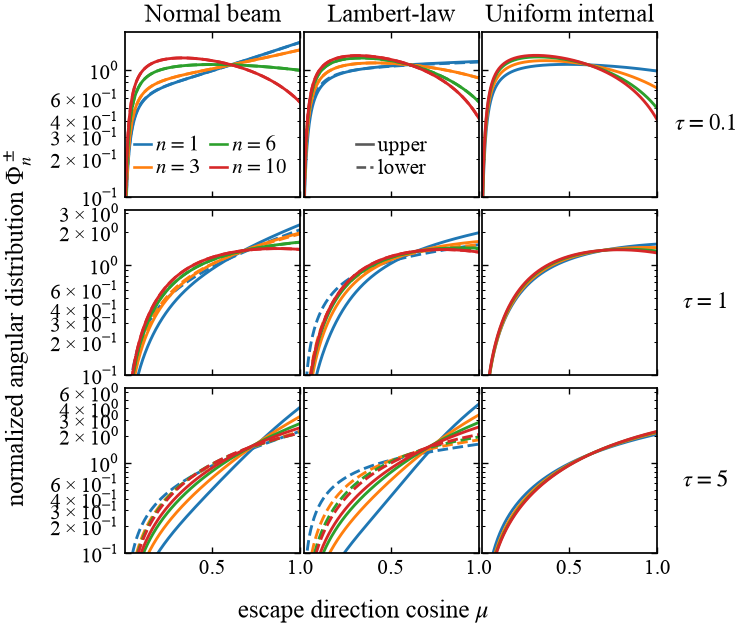

In [8]:
from pathlib import Path

FIGURE_DIR = PUBLIC_ROOT / "figure"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

try:
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from plot_style import (
        apply_mnras_style, get_double_column_size, get_three_column_size
    )
    apply_mnras_style()
except ImportError:
    plt = None
    Line2D = None

ANGULAR_TAUS = (0.1, 1.0, 5.0)
ANGULAR_ORDERS = (1, 3, 6, 10)
PLOT_N_CELLS = 384
MU_PLOT = np.linspace(0.005, 1.0, 320)
SOURCE_FACTORIES = (
    ("beam", "Normal beam", source_normal_beam),
    ("lambert", "Lambert boundary", source_lambert),
    ("internal", "Uniform internal", source_uniform_isotropic_internal),
)

ORDER_COLORS = {
    1: "C0",
    3: "C1",
    6: "C2",
    10: "C3",
}

angular_comparison_runs = {}
for tau in ANGULAR_TAUS:
    comparison_grid = SlabGrid(tau=tau, n_cells=PLOT_N_CELLS)
    comparison_operator = FFTTwoComponentOperator.build(comparison_grid, "polarized")
    for source_key, _, source_factory in SOURCE_FACTORIES:
        comparison_source = source_factory(comparison_grid)
        angular_comparison_runs[(tau, source_key)] = run_recursion(
            comparison_operator, comparison_source, max_order=max(ANGULAR_ORDERS)
        )

if plt is None:
    print("Matplotlib is not installed; angular comparison data were computed without plotting.")
else:
    fig, axes = plt.subplots(
        len(ANGULAR_TAUS), len(SOURCE_FACTORIES),
        figsize=get_three_column_size(row_height_scale=2.55),
        sharex=True, sharey="row"
    )
    for row, tau in enumerate(ANGULAR_TAUS):
        for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
            ax = axes[row, col]
            boundaries = (("+", "upper"),) if source_key == "internal" else (
                ("+", "upper"),
                ("-", "lower"),
            )
            run = angular_comparison_runs[(tau, source_key)]
            for order in ANGULAR_ORDERS:
                a_n, b_n = run.state(order)
                for boundary, surface_label in boundaries:
                    line_style = "-" if boundary == "+" else "--"
                    diagnostic = angular_diagnostics(
                        a_n, b_n, run.operator.grid, MU_PLOT, boundary, polarized=True
                    )
                    ax.plot(
                        MU_PLOT, diagnostic["Phi"],
                        linestyle=line_style, color=ORDER_COLORS[order], linewidth=1.65,
                    )
            if row == 0:
                display_title = "Lambert-law" if source_key == "lambert" else source_title
                ax.set_title(display_title)
            ax.set_yscale("log")
            ax.set_xlim(MU_PLOT[0], 1.0)
    for row in range(len(ANGULAR_TAUS)):
        axes[row, 0].set_ylim(bottom=0.1)
        axes[row, -1].set_ylabel(
            rf"$\tau={ANGULAR_TAUS[row]:g}$", rotation=0, labelpad=28
        )
        axes[row, -1].yaxis.set_label_position("right")
    fig.supxlabel(r"escape direction cosine $\mu$", y=0.11)
    fig.supylabel(r"normalized angular distribution $\Phi_n^\pm$", x=0.10)
    order_handles = [
        Line2D(
            [0], [0], color=ORDER_COLORS[order],
            linestyle="-", label=rf"$n={order}$",
        )
        for order in ANGULAR_ORDERS
    ]
    axes[0, 0].legend(
        handles=order_handles, loc="lower right", bbox_to_anchor=(0.98, 0.05),
        ncol=2, fontsize=12, handlelength=0.8, handletextpad=0.25,
        labelspacing=0.15, columnspacing=0.5, borderaxespad=0.1, frameon=False,
    )
    surface_handles = [
        Line2D([0], [0], color="0.35", linestyle="-", label="upper"),
        Line2D([0], [0], color="0.35", linestyle="--", label="lower"),
    ]
    axes[0, 1].legend(
        handles=surface_handles, loc="lower center", bbox_to_anchor=(0.5, 0.05),
        fontsize=12, handlelength=0.8, handletextpad=0.25,
        labelspacing=0.15, borderaxespad=0.1, frameon=False,
    )
    fig.tight_layout(rect=(0.07, 0.08, 0.94, 0.95))
    fig.subplots_adjust(wspace=0.02, hspace=0.08)
    fig.savefig(FIGURE_DIR / "surface_angular_distribution_grid.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 7.2. MCRT validation of exact-order angular distributions

This supporting validation is retained in addition to the final paper figures.
The bundled cold-electron Thomson MCRT exports use the same three seed sources,
$\tau=0.1,1,5$ and $n=1,3,6,10$ as the recursion plots. Each surface is displayed
separately. Lines are deterministic Stokes recursion; open symbols are MCRT
angular-bin estimates of $\Phi_n^\pm=(dP_n^\pm/d\mu)/P_n^\pm$.
The denominator is the escaped population at that **same order and surface**.
There are 36 uniform bins in $\mu$; only bins with at least 30 packets are shown.
Omitted rare-order bins are not evidence of agreement.

The caches contain 5, 3 and 1 million histories per source at the three depths.
They stop histories at 32 scatterings; at $\tau=5$ this leaves a substantial
terminated population. This does not alter photons that already escaped at
$n\leq10$, but these exports must not be used to claim convergence of the full
scattering tail or the mean scattering number. Counts are audited on loading.
These are cold monoenergetic seeds with $E/(m_ec^2)=10^{-6}$, not the thermal
diskbb benchmarks used for the neutron-star best-fit parameters.

This cell only reads bundled CSVs; missing/inconsistent data raise an error.
No binary is built, no simulation is launched, and validation plots are shown
without saving to the paper figure directory. Finite-bin MCRT estimates are
plotted at bin centers against continuous theoretical curves.


MCRT cache: tau=0.1, beam, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=0.1, lambert, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=0.1, internal, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=0.3, beam, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=0.3, lambert, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=0.3, internal, histories=5,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=1, beam, histories=3,000,000, terminated at n=32: 0; only n<=10 is used here.
MCRT cache: tau=1, lambert, histories=3,000,000, terminated at n=32: 2; only n<=10 is used here.
MCRT cache: tau=1, internal, histories=3,000,000, terminated at n=32: 1; only n<=10 is used here.
MCRT cache: tau=3, beam, histories=1,000,000, terminated at n=32: 8,170; only n<=10 is used here.
MCRT cache: tau=3, lamb

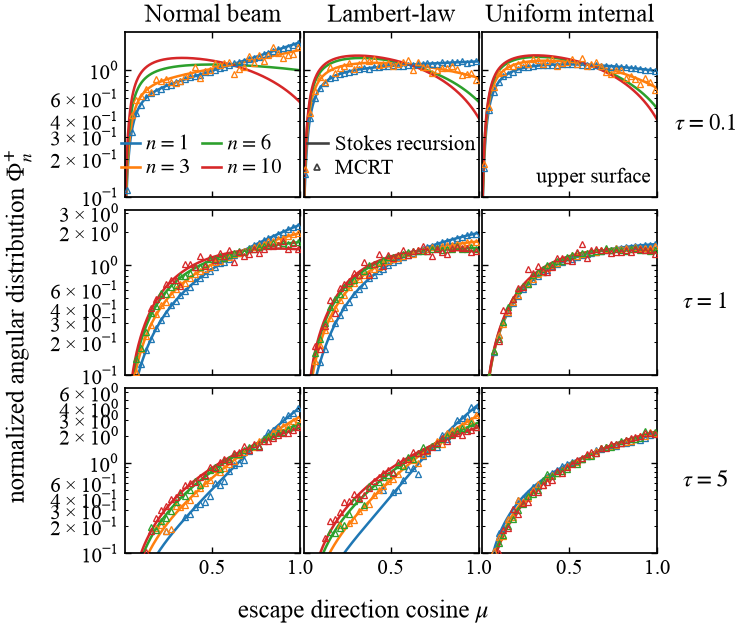

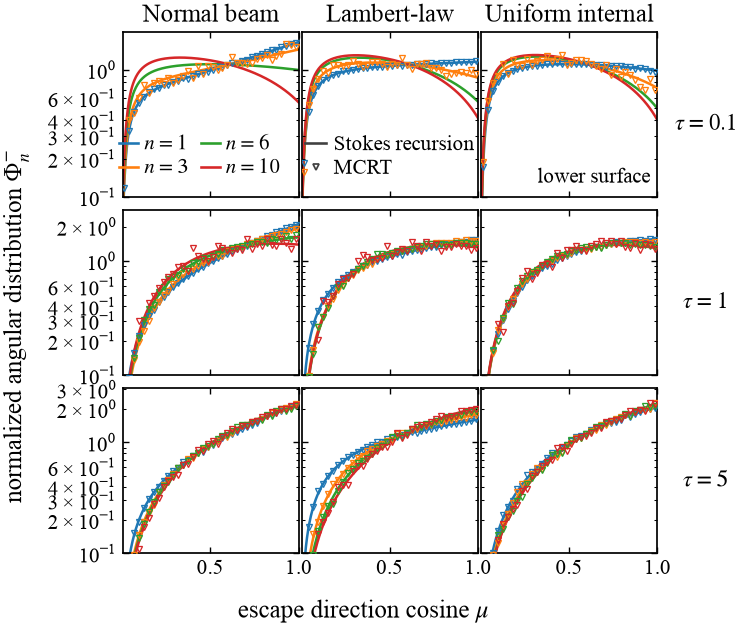

In [9]:
from helpers.order_validation import (
    load_order_cases, _mcrt_phi_points, _mcrt_polarization_points,
    MCRT_MIN_ANGULAR_BIN_COUNT, MCRT_MIN_POLARIZATION_BIN_COUNT,
)
mcrt_stokes_cases = load_order_cases()

if plt is None:
    print("Matplotlib is not installed; MCRT angular caches loaded without plotting.")
else:
    for boundary, surface_name, mcrt_marker in (
        ("+", "upper", "^"),
        ("-", "lower", "v"),
    ):
        fig, axes = plt.subplots(
            len(ANGULAR_TAUS), len(SOURCE_FACTORIES),
            figsize=get_three_column_size(row_height_scale=2.55),
            sharex=True, sharey="row",
        )
        for row, tau in enumerate(ANGULAR_TAUS):
            for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
                ax = axes[row, col]
                run = angular_comparison_runs[(tau, source_key)]
                case = mcrt_stokes_cases[(tau, source_key)]
                for order in ANGULAR_ORDERS:
                    a_n, b_n = run.state(order)
                    diagnostic = angular_diagnostics(
                        a_n, b_n, run.operator.grid, MU_PLOT, boundary, polarized=True,
                    )
                    ax.plot(
                        MU_PLOT, diagnostic["Phi"], color=ORDER_COLORS[order],
                        linestyle="-", marker=None, linewidth=1.45, zorder=1,
                    )
                    mu, phi, usable = _mcrt_phi_points(case, boundary, order)
                    ax.plot(
                        mu[usable], phi[usable], linestyle="none",
                        marker=mcrt_marker, markersize=3.4,
                        markerfacecolor="none", markeredgewidth=0.75,
                        color=ORDER_COLORS[order], zorder=3,
                    )
                if row == 0:
                    ax.set_title("Lambert-law" if source_key == "lambert" else source_title)
                ax.set_yscale("log")
                ax.set_xlim(MU_PLOT[0], 1.0)
        for row, tau in enumerate(ANGULAR_TAUS):
            axes[row, 0].set_ylim(bottom=0.1)
            axes[row, -1].set_ylabel(rf"$\tau={tau:g}$", rotation=0, labelpad=28)
            axes[row, -1].yaxis.set_label_position("right")
        fig.supxlabel(r"escape direction cosine $\mu$", y=0.11)
        fig.supylabel(rf"normalized angular distribution $\Phi_n^{{{boundary}}}$", x=0.10)
        order_handles = [
            Line2D([0], [0], color=ORDER_COLORS[order], lw=1.5, label=rf"$n={order}$")
            for order in ANGULAR_ORDERS
        ]
        method_handles = [
            Line2D([0], [0], color="0.25", lw=1.5, label="Stokes recursion"),
            Line2D([0], [0], color="0.25", lw=0, marker=mcrt_marker,
                   markerfacecolor="none", markersize=4.0, label="MCRT"),
        ]
        axes[0, 0].legend(
            handles=order_handles, loc="lower right", ncol=2, frameon=False,
            handlelength=0.9, handletextpad=0.3, columnspacing=0.6, labelspacing=0.2,
        )
        axes[0, 1].legend(
            handles=method_handles, loc="lower center", frameon=False,
            handlelength=1.0, handletextpad=0.35, labelspacing=0.2,
        )
        axes[0, 2].text(
            0.96, 0.06, f"{surface_name} surface", transform=axes[0, 2].transAxes,
            ha="right", va="bottom",
        )
        fig.tight_layout(rect=(0.07, 0.08, 0.94, 0.95))
        fig.subplots_adjust(wspace=0.02, hspace=0.08)
        plt.show()


### 7.3. Surface polarization by scattering order

We use the same optical-depth, seed-source and scattering-order grids as in Section 7.1.


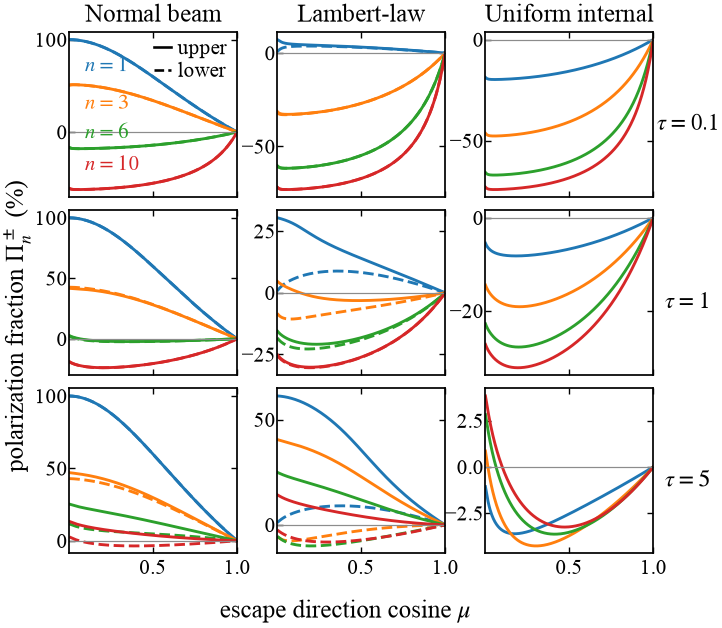

In [10]:
if plt is None:
    print("Matplotlib is not installed; surface-polarization data were computed without plotting.")
else:
    fig, axes = plt.subplots(
        len(ANGULAR_TAUS), len(SOURCE_FACTORIES),
        figsize=get_three_column_size(row_height_scale=2.55),
        sharex=True, sharey=False
    )
    for row, tau in enumerate(ANGULAR_TAUS):
        for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
            ax = axes[row, col]
            ax.tick_params(axis="y", pad=1)
            run = angular_comparison_runs[(tau, source_key)]
            boundaries = (("+", "upper"),) if source_key == "internal" else (
                ("+", "upper"),
                ("-", "lower"),
            )
            for order in ANGULAR_ORDERS:
                a_n, b_n = run.state(order)
                for boundary, surface_label in boundaries:
                    color = ORDER_COLORS[order]
                    line_style = "-" if boundary == "+" else "--"
                    diagnostic = angular_diagnostics(
                        a_n, b_n, run.operator.grid, MU_PLOT, boundary, polarized=True
                    )
                    ax.plot(
                        MU_PLOT, 100.0 * diagnostic["Pi_signed"],
                        color=color, linestyle=line_style, linewidth=1.65,
                    )
                    if row == 0 and col == 0 and boundary == "+":
                        label_mu = 0.14
                        label_index = int(np.argmin(np.abs(MU_PLOT - label_mu)))
                        label_offset = {1: (-4, -8), 3: (-4, -5), 6: (-4, 3), 10: (-4, 8)}[order]
                        label_va = "top" if order in (1, 3) else "bottom"
                        ax.annotate(
                            rf"$n={order}$",
                            xy=(MU_PLOT[label_index], 100.0 * diagnostic["Pi_signed"][label_index]),
                            xytext=label_offset, textcoords="offset points",
                            color=color, fontsize=12, ha="left", va=label_va, clip_on=True,
                        )
            ax.axhline(0.0, color="0.55", linewidth=0.7)
            if row == 0:
                display_title = "Lambert-law" if source_key == "lambert" else source_title
                ax.set_title(display_title)
            ax.set_xlim(MU_PLOT[0], 1.0)
    for row in range(len(ANGULAR_TAUS)):
        axes[row, -1].set_ylabel(
            rf"$\tau={ANGULAR_TAUS[row]:g}$", rotation=0, labelpad=20
        )
        axes[row, -1].yaxis.set_label_position("right")
    fig.supxlabel(r"escape direction cosine $\mu$", y=0.11)
    fig.supylabel(r"polarization fraction $\Pi_n^\pm$ (%)", x=0.12)
    surface_style_handles = [
        Line2D([0], [0], color="black", linestyle="-", label="upper"),
        Line2D([0], [0], color="black", linestyle="--", label="lower"),
    ]
    axes[0, 0].legend(
        handles=surface_style_handles, loc="upper right", bbox_to_anchor=(1.0, 1.02),
        handlelength=0.85, handletextpad=0.3, labelspacing=0.15,
        borderaxespad=0.1, frameon=False,
    )
    fig.tight_layout(rect=(0.07, 0.08, 0.94, 0.95))
    fig.subplots_adjust(wspace=0.24, hspace=0.08)
    fig.savefig(FIGURE_DIR / "surface_polarization_grid.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 7.4. MCRT validation of exact-order polarization fractions

The upper and lower surfaces are shown separately, using the cached cases above.
Continuous curves are Stokes recursion; open symbols and vertical error bars
are MCRT Stokes ratios in 5-degree angular bins and their Monte Carlo standard
errors. Bins with fewer than 100 packets are omitted. The conversion
$\Pi=-Q_{\rm MCRT}/I_{\rm MCRT}$ is applied exactly once to the archived raw
Stokes convention. These are supporting, display-only figures, not additional
PDF exports. The finite-bin interpretation and scattering-cap limitation stated
above apply here as well.


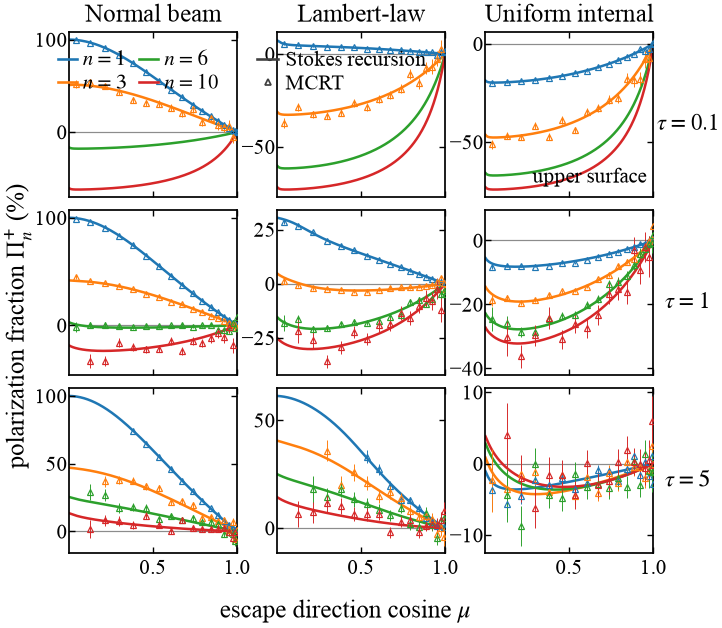

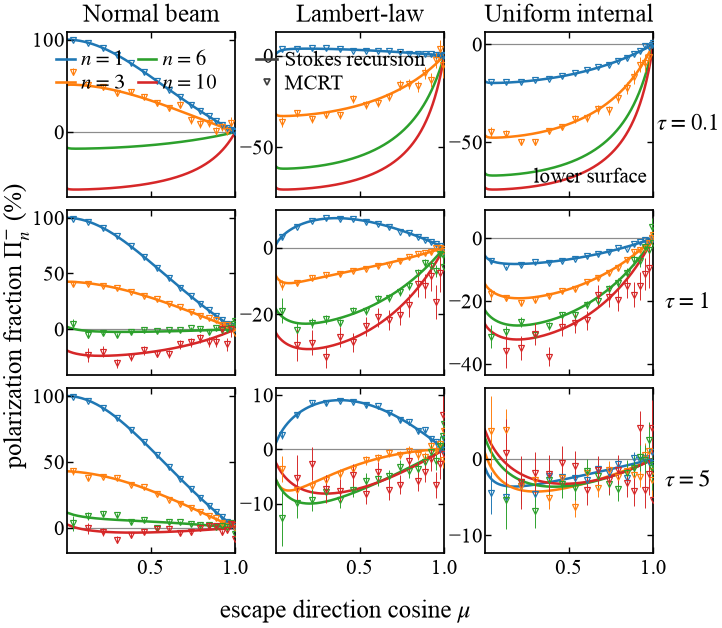

In [11]:
if plt is None:
    print("Matplotlib is not installed; MCRT polarization data were computed without plotting.")
else:
    for boundary, surface_name, mcrt_marker in (
        ("+", "upper", "^"),
        ("-", "lower", "v"),
    ):
        fig, axes = plt.subplots(
            len(ANGULAR_TAUS), len(SOURCE_FACTORIES),
            figsize=get_three_column_size(row_height_scale=2.55),
            sharex=True, sharey=False,
        )
        for row, tau in enumerate(ANGULAR_TAUS):
            for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
                ax = axes[row, col]
                ax.tick_params(axis="y", pad=1)
                run = angular_comparison_runs[(tau, source_key)]
                case = mcrt_stokes_cases[(tau, source_key)]
                for order in ANGULAR_ORDERS:
                    a_n, b_n = run.state(order)
                    diagnostic = angular_diagnostics(
                        a_n, b_n, run.operator.grid, MU_PLOT, boundary, polarized=True,
                    )
                    ax.plot(
                        MU_PLOT, 100.0 * diagnostic["Pi_signed"],
                        color=ORDER_COLORS[order], linestyle="-",
                        marker=None, linewidth=1.45, zorder=1,
                    )
                    mu, pi, error, usable = _mcrt_polarization_points(case, boundary, order)
                    ax.errorbar(
                        mu[usable], 100.0 * pi[usable], yerr=100.0 * error[usable],
                        fmt=mcrt_marker, linestyle="none",
                        markersize=3.2, markerfacecolor="none", markeredgewidth=0.7,
                        color=ORDER_COLORS[order], elinewidth=0.55, capsize=0, zorder=3,
                    )
                ax.axhline(0.0, color="0.55", linewidth=0.7, zorder=0)
                if row == 0:
                    ax.set_title("Lambert-law" if source_key == "lambert" else source_title)
                ax.set_xlim(MU_PLOT[0], 1.0)
        for row, tau in enumerate(ANGULAR_TAUS):
            axes[row, -1].set_ylabel(rf"$\tau={tau:g}$", rotation=0, labelpad=20)
            axes[row, -1].yaxis.set_label_position("right")
        fig.supxlabel(r"escape direction cosine $\mu$", y=0.11)
        fig.supylabel(rf"polarization fraction $\Pi_n^{{{boundary}}}$ (%)", x=0.12)
        order_handles = [
            Line2D([0], [0], color=ORDER_COLORS[order], lw=1.5, label=rf"$n={order}$")
            for order in ANGULAR_ORDERS
        ]
        method_handles = [
            Line2D([0], [0], color="0.25", lw=1.5, label="Stokes recursion"),
            Line2D([0], [0], color="0.25", lw=0, marker=mcrt_marker,
                   markerfacecolor="none", markersize=4.0, label="MCRT"),
        ]
        axes[0, 0].legend(
            handles=order_handles, loc="upper right", ncol=2, frameon=False,
            handlelength=0.9, handletextpad=0.3, columnspacing=0.6, labelspacing=0.2,
        )
        axes[0, 1].legend(
            handles=method_handles, loc="upper right", frameon=False,
            handlelength=1.0, handletextpad=0.35, labelspacing=0.2,
        )
        axes[0, 2].text(
            0.96, 0.06, f"{surface_name} surface", transform=axes[0, 2].transAxes,
            ha="right", va="bottom",
        )
        fig.tight_layout(rect=(0.07, 0.08, 0.94, 0.95))
        fig.subplots_adjust(wspace=0.24, hspace=0.08)
        plt.show()

## 8. Escape, survival and mean scattering number


### 8.1. Escape probabilities by scattering order

These two figures use optical depths $\tau=0.3,1,3$ as rows and the three seed sources as columns. Points and connecting lines are shown together. Scalar and Stokes use Matplotlib cycle colors `C0` and `C1`, respectively. In the $P_n^\pm$ figure, upper and lower surfaces use solid/up-triangle and dashed/down-triangle encodings for both recursion frameworks. In the $M_n$ figure, scalar and Stokes retain open circles and open squares on solid lines.

The first plotting cell resolves the probability of escaping after exactly $n$ scatterings into the upper and lower surfaces, $P_n^+$ and $P_n^-$. The second plotting cell shows $M_n$, the probability that a photon has undergone at least $n$ scatterings; consequently its horizontal axis begins at $n=1$. Both figures omit grid lines, keep their legends inside the figure, and show each optical-depth label horizontally on the right. Each figure has one centered shared $x$ label and one centered shared $y$ label; the three seed-source panels within each optical-depth row share one automatic vertical range. Values below `ORDER_PLOT_FLOOR` are omitted to avoid displaying floating-point round-off after the physical tail has vanished.


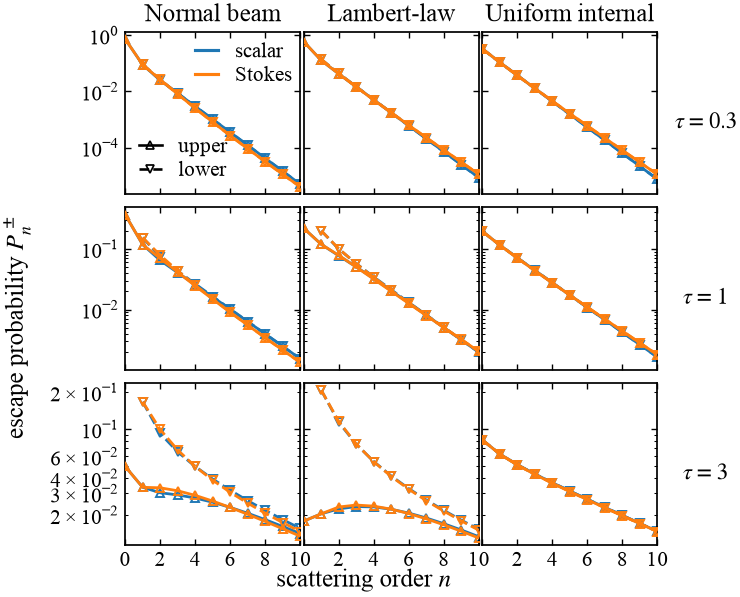

In [12]:
try:
    import matplotlib.pyplot as plt
    from plot_style import (
        apply_mnras_style, get_double_column_size, get_three_column_size
    )
    apply_mnras_style()
except ImportError:
    plt = None

ORDER_TAUS = (0.3, 1.0, 3.0)
ORDER_MAX = 10
ORDER_N_CELLS = 384
ORDER_PLOT_FLOOR = 1.0e-15
MODEL_LINE_MARKER_STYLES = {
    "scalar": dict(
        color="C0", linestyle="--", marker="o",
        markerfacecolor="none", markeredgecolor="C0",
        label="scalar", zorder=2,
    ),
    "polarized": dict(
        color="C1", linestyle="-", marker="s",
        markerfacecolor="none", markeredgecolor="C1",
        label="Stokes", zorder=3,
    ),
}
def positive_plot_segment(x, y, floor=ORDER_PLOT_FLOOR):
    x = np.asarray(x)
    y = np.asarray(y)
    mask = np.isfinite(y) & (y > floor)
    return x[mask], y[mask]


def survival_order_distribution(run: RecursionRun):
    orders = np.arange(1, run.max_order + 1)
    values = np.array([
        survival_probability(*run.state(order), run.operator.grid)
        for order in orders
    ])
    return {"n": orders, "M": values}


order_comparison_runs = {}
for tau in ORDER_TAUS:
    order_grid = SlabGrid(tau=tau, n_cells=ORDER_N_CELLS)
    order_operators = {
        kind: FFTTwoComponentOperator.build(order_grid, kind)
        for kind in ("scalar", "polarized")
    }
    for source_key, _, source_factory in SOURCE_FACTORIES:
        order_source = source_factory(order_grid)
        for kind, operator in order_operators.items():
            order_comparison_runs[(tau, source_key, kind)] = run_recursion(
                operator, order_source, max_order=ORDER_MAX
            )

if plt is None:
    print("Matplotlib is not installed; order-distribution data were computed without plotting.")
else:
    fig, axes = plt.subplots(
        len(ORDER_TAUS), len(SOURCE_FACTORIES),
        figsize=get_three_column_size(row_height_scale=2.55),
        sharex=True, sharey="row"
    )
    for row, tau in enumerate(ORDER_TAUS):
        for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
            ax = axes[row, col]
            for kind in ("scalar", "polarized"):
                run = order_comparison_runs[(tau, source_key, kind)]
                distribution = scattering_order_distribution(run)
                for boundary, probability_key, surface_label in (
                    ("+", "P_plus", "upper"),
                    ("-", "P_minus", "lower"),
                ):
                    n_plot, p_plot = positive_plot_segment(
                        distribution["n"], distribution[probability_key]
                    )
                    style = MODEL_LINE_MARKER_STYLES[kind].copy()
                    style["linestyle"] = "-" if boundary == "+" else "--"
                    style["marker"] = "^" if boundary == "+" else "v"
                    style["label"] = f"{surface_label}, {style['label']}"
                    ax.plot(
                        n_plot, p_plot, linewidth=1.6, markersize=5.0, markeredgewidth=1.1,
                        **style,
                    )
            ax.set_yscale("log")
            if row == 0:
                display_title = "Lambert-law" if source_key == "lambert" else source_title
                ax.set_title(display_title)
            ax.set_xlim(0, ORDER_MAX)
            ax.set_xticks(np.arange(0, ORDER_MAX + 1, 2))
    for col in (1, 2):
        axes[-1, col].xaxis.get_major_ticks()[0].label1.set_visible(False)
    for row in range(len(ORDER_TAUS)):
        axes[row, -1].set_ylabel(
            rf"$\tau={ORDER_TAUS[row]:g}$", rotation=0, labelpad=28
        )
        axes[row, -1].yaxis.set_label_position("right")
    from matplotlib.lines import Line2D
    fig.supxlabel(r"scattering order $n$", y=0.15)
    fig.supylabel(r"escape probability $P_n^\pm$", x=0.10)
    color_legend = axes[0, 0].legend(
        handles=[
            Line2D([0], [0], color="C0", lw=1.8, label="scalar"),
            Line2D([0], [0], color="C1", lw=1.8, label="Stokes"),
        ],
        loc="upper right", bbox_to_anchor=(1.06, 1.05), ncol=1,
        handlelength=1.1, labelspacing=0.2, frameon=False,
    )
    axes[0, 0].add_artist(color_legend)
    axes[0, 0].legend(
        handles=[
            Line2D([0], [0], color="black", lw=1.5, ls="-", marker="^",
                   markerfacecolor="none", markersize=5.0, label="upper"),
            Line2D([0], [0], color="black", lw=1.5, ls="--", marker="v",
                   markerfacecolor="none", markersize=5.0, label="lower"),
        ],
        loc="lower left", bbox_to_anchor=(-0.03, -0.03), ncol=1,
        handlelength=1.1, labelspacing=0.2, frameon=False,
    )
    fig.tight_layout(rect=(0.07, 0.09, 0.94, 0.95))
    fig.subplots_adjust(wspace=0.02, hspace=0.08)
    fig.savefig(FIGURE_DIR / "escape_probability_grid.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 8.2. MCRT validation of escape probabilities

At $\tau=0.3,1,3$ and for all three seed sources, curves show scalar and Stokes
recursion while open upward/downward triangles show upper/lower surface
**Stokes MCRT** estimates with binomial standard errors. The curves have no
markers. Orders $n=0,\ldots,10$ are displayed when the escaped count is at least 10.
We compute $\widehat P_n^\pm=N_n^\pm/N_{\rm injected}$ from integer counts, not
from the rounded probability columns, and never renormalize by escaped counts.
Each source has 5, 3 and 1 million histories at $\tau=0.3,1,3$, respectively.
The same cached histories are shared with the survival check below; these are
not independent measurements of P and M. No simulation is launched and no
additional figure file is exported.


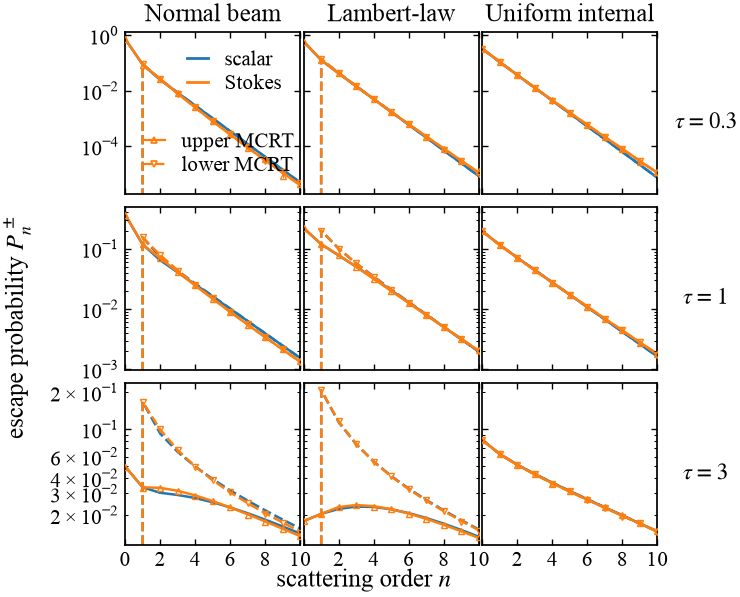

In [13]:
from helpers.order_validation import mcrt_escape_series, mcrt_survival_series

if plt is None:
    print("Matplotlib is not installed; MCRT escape-probability caches loaded without plotting.")
else:
    fig, axes = plt.subplots(
        len(ORDER_TAUS), len(SOURCE_FACTORIES),
        figsize=get_three_column_size(row_height_scale=2.55),
        sharex=True, sharey="row",
    )
    for row, tau in enumerate(ORDER_TAUS):
        for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
            ax = axes[row, col]
            stokes_case = mcrt_stokes_cases[(tau, source_key)]
            for kind, color in (("scalar", "C0"), ("polarized", "C1")):
                run = order_comparison_runs[(tau, source_key, kind)]
                distribution = scattering_order_distribution(run)
                for boundary, key in (("+", "P_plus"), ("-", "P_minus")):
                    linestyle = "-" if boundary == "+" else "--"
                    ax.plot(
                        distribution["n"], distribution[key], color=color,
                        linestyle=linestyle, marker=None, linewidth=1.45, zorder=1,
                    )
                    if kind != "polarized":
                        continue
                    n, probability, error, usable = mcrt_escape_series(
                        stokes_case, boundary, ORDER_MAX,
                    )
                    ax.errorbar(
                        n[usable], probability[usable], yerr=error[usable],
                        fmt="^" if boundary == "+" else "v", linestyle="none",
                        markersize=3.8, markerfacecolor="none", markeredgewidth=0.8,
                        color=color, elinewidth=0.55, capsize=0, zorder=3,
                    )
            ax.set_yscale("log")
            ax.set_xlim(0, ORDER_MAX)
            ax.set_xticks(np.arange(0, ORDER_MAX + 1, 2))
            if row == 0:
                ax.set_title("Lambert-law" if source_key == "lambert" else source_title)
    for col in (1, 2):
        axes[-1, col].xaxis.get_major_ticks()[0].label1.set_visible(False)
    for row, tau in enumerate(ORDER_TAUS):
        axes[row, -1].set_ylabel(rf"$\tau={tau:g}$", rotation=0, labelpad=28)
        axes[row, -1].yaxis.set_label_position("right")
    fig.supxlabel(r"scattering order $n$", y=0.15)
    fig.supylabel(r"escape probability $P_n^\pm$", x=0.10)
    framework_handles = [
        Line2D([0], [0], color="C0", lw=1.6, label="scalar"),
        Line2D([0], [0], color="C1", lw=1.6, label="Stokes"),
    ]
    surface_handles = [
        Line2D([0], [0], color="C1", lw=1.3, ls="-", marker="^",
               markerfacecolor="none", markersize=4.0, label="upper MCRT"),
        Line2D([0], [0], color="C1", lw=1.3, ls="--", marker="v",
               markerfacecolor="none", markersize=4.0, label="lower MCRT"),
    ]
    first_legend = axes[0, 0].legend(
        handles=framework_handles, loc="upper right", frameon=False,
        handlelength=1.0, labelspacing=0.2,
    )
    axes[0, 0].add_artist(first_legend)
    axes[0, 0].legend(
        handles=surface_handles, loc="lower left", frameon=False,
        handlelength=1.0, labelspacing=0.2,
    )
    fig.tight_layout(rect=(0.07, 0.09, 0.94, 0.95))
    fig.subplots_adjust(wspace=0.02, hspace=0.08)
    plt.show()

### 8.3. Survival probabilities by scattering order

We plot the probability of reaching at least $n$ scatterings for the same sources and optical depths.


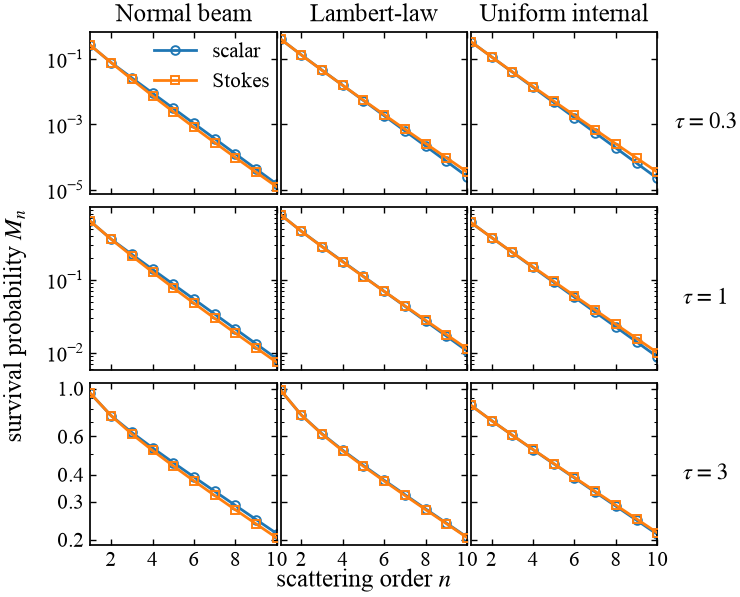

In [14]:
if plt is None:
    print("Matplotlib is not installed; survival-probability data were computed without plotting.")
else:
    from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullFormatter
    fig, axes = plt.subplots(
        len(ORDER_TAUS), len(SOURCE_FACTORIES),
        figsize=get_three_column_size(row_height_scale=2.55),
        sharex=True, sharey="row"
    )
    for row, tau in enumerate(ORDER_TAUS):
        for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
            ax = axes[row, col]
            for kind in ("scalar", "polarized"):
                run = order_comparison_runs[(tau, source_key, kind)]
                survival = survival_order_distribution(run)
                n_plot, m_plot = positive_plot_segment(survival["n"], survival["M"])
                style = MODEL_LINE_MARKER_STYLES[kind].copy()
                style["linestyle"] = "-"
                ax.plot(
                    n_plot, m_plot, linewidth=1.6, markersize=5.0, markeredgewidth=1.1,
                    **style,
                )
            ax.set_yscale("log")
            if row == len(ORDER_TAUS) - 1:
                ax.yaxis.set_major_locator(FixedLocator([0.2, 0.3, 0.4, 0.6, 1.0]))
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
                ax.yaxis.set_minor_formatter(NullFormatter())
            if row == 0:
                display_title = "Lambert-law" if source_key == "lambert" else source_title
                ax.set_title(display_title)
            ax.set_xlim(1, ORDER_MAX)
            ax.set_xticks(np.arange(2, ORDER_MAX + 1, 2))
    for row in range(len(ORDER_TAUS)):
        axes[row, -1].set_ylabel(
            rf"$\tau={ORDER_TAUS[row]:g}$", rotation=0, labelpad=28
        )
        axes[row, -1].yaxis.set_label_position("right")
    fig.supxlabel(r"scattering order $n$", y=0.15)
    fig.supylabel(r"survival probability $M_n$", x=0.10)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    axes[0, 0].legend(
        handles, labels, loc="upper right", bbox_to_anchor=(1.06, 1.05),
        frameon=False,
    )
    fig.tight_layout(rect=(0.07, 0.09, 0.94, 0.95))
    fig.subplots_adjust(wspace=0.02, hspace=0.08)
    fig.savefig(FIGURE_DIR / "survival_probability_grid.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 8.4. MCRT validation of survival probabilities

The convention is $M_n=\Pr(N_{\rm sc}\geq n)$, hence

$$
\widehat M_n=1-\sum_{j=0}^{n-1}(\widehat P_j^++\widehat P_j^-),\qquad n=1,\ldots,10.
$$

The estimator uses the full number of injected histories and integer escaped
counts. Histories terminated at the 32-scattering cap are still survivors at
the displayed orders and must **not** be dropped or treated as escaped.
This construction therefore remains valid for these low-order probabilities,
without claiming that the complete tail or mean scattering number is converged.
Vertical bars are marginal binomial standard errors
$[\widehat M_n(1-\widehat M_n)/N_{\rm injected}]^{1/2}$; different orders are
correlated and these bars are not a joint covariance model. Only points with
at least 10 surviving histories are shown. Curves are scalar/Stokes theory;
open circles are the Stokes MCRT results. The plot is display-only.


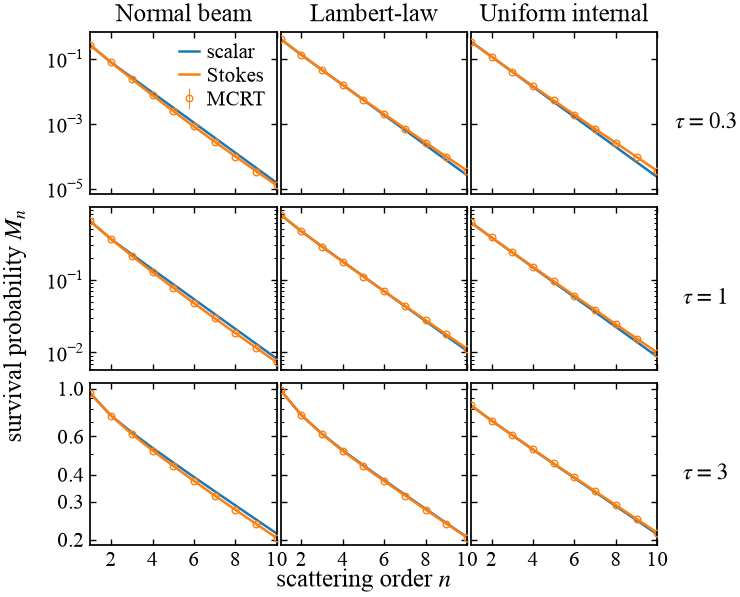

In [15]:
# Validate M_n directly from the full injected population, including capped histories.
from helpers.order_validation import mcrt_survival_series
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullFormatter

fig, axes = plt.subplots(
    len(ORDER_TAUS), len(SOURCE_FACTORIES),
    figsize=get_three_column_size(row_height_scale=2.55), sharex=True, sharey="row",
)
for row, tau in enumerate(ORDER_TAUS):
    for col, (source_key, source_title, _) in enumerate(SOURCE_FACTORIES):
        ax = axes[row, col]
        for kind, color, label in (("scalar", "C0", "scalar"), ("polarized", "C1", "Stokes")):
            run = order_comparison_runs[tau, source_key, kind]
            theory = survival_order_distribution(run)
            ax.plot(theory["n"], theory["M"], color=color, ls="-", lw=1.45, label=label)
        case = mcrt_stokes_cases[tau, source_key]
        n, survival, error, usable = mcrt_survival_series(case, ORDER_MAX)
        ax.errorbar(
            n[usable], survival[usable], yerr=error[usable], fmt="o", ls="none",
            mfc="none", ms=3.8, mew=0.8, color="C1", elinewidth=0.55,
            capsize=0, zorder=3, label="MCRT",
        )
        ax.set_yscale("log")
        ax.set_xlim(1, ORDER_MAX)
        ax.set_xticks(np.arange(2, ORDER_MAX + 1, 2))
        if row == len(ORDER_TAUS)-1:
            ax.yaxis.set_major_locator(FixedLocator([0.2, 0.3, 0.4, 0.6, 1.0]))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
            ax.yaxis.set_minor_formatter(NullFormatter())
        if row == 0:
            ax.set_title("Lambert-law" if source_key == "lambert" else source_title)
    axes[row, -1].set_ylabel(rf"$\tau={tau:g}$", rotation=0, labelpad=28)
    axes[row, -1].yaxis.set_label_position("right")
axes[0, 0].legend(loc="upper right", frameon=False, handlelength=1.0,
                  handletextpad=0.35, labelspacing=0.2, borderaxespad=0.15)
fig.supxlabel(r"scattering order $n$", y=0.15)
fig.supylabel(r"survival probability $M_n$", x=0.10)
fig.tight_layout(rect=(0.07, 0.09, 0.94, 0.95))
fig.subplots_adjust(wspace=0.02, hspace=0.08)
plt.show()


### 8.5. Mean scattering number from the adjoint resolvent

We compute the mean without truncating the scattering-order sum, using one adjoint linear solve per optical depth and recursion framework.


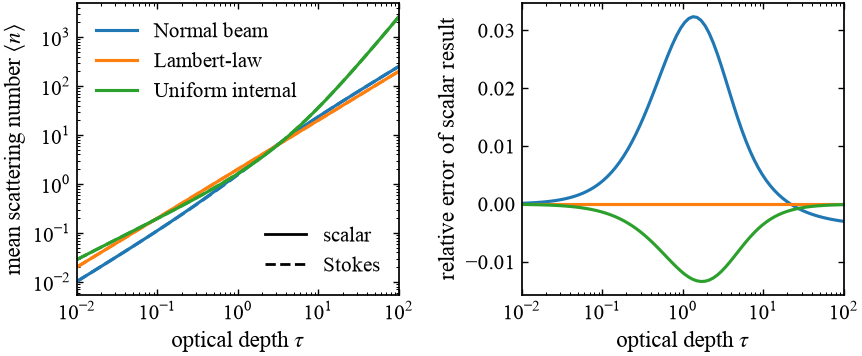

In [16]:
# Mean scattering number for the three seed sources in the scalar and Stokes frameworks.
# Since <n> = sum_{n>=1} M_n, solve the resolvent through one adjoint
# linear system per (tau, framework), shared by all three source vectors.
# This is equivalent to Appendix Eq. (A36), e^T(I-K)^(-2)U1, because
# probability conservation gives e^T = ell^T(I-K).
from scipy.sparse.linalg import LinearOperator, gmres
from plot_style import get_double_column_size, get_single_column_size

MEAN_SCATTER_TAUS = np.geomspace(0.01, 100.0, 80)
MEAN_SCATTER_MIN_CELLS = 384
MEAN_SCATTER_MAX_CELL_WIDTH = 0.08
MEAN_SCATTER_RTOL = 1.0e-10
MEAN_FRAMEWORK_STYLES = {"scalar": "-", "polarized": "--"}
MEAN_SOURCE_LABELS = {
    "beam": "Normal beam",
    "lambert": "Lambert-law",
    "internal": "Uniform internal",
}


def mean_scattering_grid(tau: float) -> SlabGrid:
    """Use a fixed minimum resolution and limit the thick-slab cell width."""
    n_cells = max(
        MEAN_SCATTER_MIN_CELLS,
        int(np.ceil(float(tau) / MEAN_SCATTER_MAX_CELL_WIDTH)),
    )
    n_cells += n_cells % 2
    return SlabGrid(tau=float(tau), n_cells=n_cells)


def adjoint_recursion_step(
    operator: FFTTwoComponentOperator, a: np.ndarray, b: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Apply K^T; the depth Toeplitz blocks are individually symmetric."""
    n_cells = operator.grid.n_cells
    state = np.stack([np.asarray(a, dtype=float), np.asarray(b, dtype=float)])
    padded = np.zeros((2, 2 * n_cells))
    padded[:, :n_cells] = state
    state_fft = np.fft.rfft(padded, axis=1)
    next_fft = np.einsum(
        "jif,jf->if", operator.kernel_fft, state_fft, optimize=True
    )
    next_state = np.fft.irfft(next_fft, n=2 * n_cells, axis=1)
    return next_state[0, :n_cells], next_state[1, :n_cells]


def mean_scattering_adjoint_weights(operator: FFTTwoComponentOperator) -> np.ndarray:
    """Solve (I-K^T) y = ell, where ell evaluates M_n."""
    grid = operator.grid
    n_cells = grid.n_cells
    survival_functional = np.concatenate([
        np.full(n_cells, 2.0 * grid.h),
        np.full(n_cells, 2.0 * grid.h / 3.0),
    ])

    def matvec(state: np.ndarray) -> np.ndarray:
        ka, kb = adjoint_recursion_step(
            operator, state[:n_cells], state[n_cells:]
        )
        return state - np.concatenate([ka, kb])

    linear_system = LinearOperator(
        (2 * n_cells, 2 * n_cells), matvec=matvec, dtype=float
    )
    weights, info = gmres(
        linear_system, survival_functional,
        rtol=MEAN_SCATTER_RTOL, atol=0.0, restart=80, maxiter=500,
    )
    if info != 0:
        raise RuntimeError(
            f"mean-scattering GMRES failed for tau={grid.tau:g}, "
            f"kind={operator.kind}, info={info}"
        )
    relative_residual = np.linalg.norm(matvec(weights) - survival_functional) / (
        np.linalg.norm(survival_functional)
    )
    if relative_residual > 10.0 * MEAN_SCATTER_RTOL:
        raise RuntimeError(f"mean-scattering residual too large: {relative_residual:.3e}")
    return weights


mean_scattering_results = {
    source_key: {kind: np.empty_like(MEAN_SCATTER_TAUS) for kind in MEAN_FRAMEWORK_STYLES}
    for source_key, _, _ in SOURCE_FACTORIES
}
mean_scattering_grid_sizes = np.empty(MEAN_SCATTER_TAUS.size, dtype=int)

for tau_index, tau in enumerate(MEAN_SCATTER_TAUS):
    grid = mean_scattering_grid(tau)
    mean_scattering_grid_sizes[tau_index] = grid.n_cells
    sources_at_tau = {
        source_key: source_factory(grid)
        for source_key, _, source_factory in SOURCE_FACTORIES
    }
    for kind in MEAN_FRAMEWORK_STYLES:
        operator = FFTTwoComponentOperator.build(grid, kind)
        weights = mean_scattering_adjoint_weights(operator)
        for source_key, _, _ in SOURCE_FACTORIES:
            source = sources_at_tau[source_key]
            source_state = np.concatenate([source.a1, source.b1])
            mean_value = float(np.dot(weights, source_state))
            if not np.isfinite(mean_value) or mean_value <= 0.0:
                raise RuntimeError(
                    f"invalid mean scattering number for tau={tau:g}, "
                    f"source={source_key}, kind={kind}: {mean_value}"
                )
            mean_scattering_results[source_key][kind][tau_index] = mean_value

if plt is None:
    print("Matplotlib is not installed; mean-scattering data were computed without plotting.")
else:
    fig, axes = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.05), sharex=True
    )
    ax_mean, ax_error = axes
    for source_index, (source_key, _, _) in enumerate(SOURCE_FACTORIES):
        for kind, line_style in MEAN_FRAMEWORK_STYLES.items():
            ax_mean.plot(
                MEAN_SCATTER_TAUS, mean_scattering_results[source_key][kind],
                color=f"C{source_index}", linestyle=line_style, linewidth=1.8,
            )
        stokes_mean = mean_scattering_results[source_key]["polarized"]
        relative_error = (
            mean_scattering_results[source_key]["scalar"] - stokes_mean
        ) / stokes_mean
        ax_error.plot(
            MEAN_SCATTER_TAUS, relative_error,
            color=f"C{source_index}", linewidth=1.8,
        )

    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlim(MEAN_SCATTER_TAUS[0], MEAN_SCATTER_TAUS[-1])
        ax.set_xlabel(r"optical depth $\tau$")
    ax_mean.set_yscale("log")
    ax_mean.set_ylabel(r"mean scattering number $\langle n\rangle$")
    ax_error.axhline(0.0, color="0.45", linewidth=0.8, zorder=0)
    ax_error.set_ylabel("relative error of scalar result")

    source_handles = [
        Line2D([0], [0], color=f"C{source_index}", lw=1.8,
               label=MEAN_SOURCE_LABELS[source_key])
        for source_index, (source_key, _, _) in enumerate(SOURCE_FACTORIES)
    ]
    framework_handles = [
        Line2D([0], [0], color="black", lw=1.6, ls="-", label="scalar"),
        Line2D([0], [0], color="black", lw=1.6, ls="--", label="Stokes"),
    ]
    source_legend = ax_mean.legend(
        handles=source_handles, loc="upper left", frameon=False
    )
    ax_mean.add_artist(source_legend)
    ax_mean.legend(handles=framework_handles, loc="lower right", frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "mean_scattering_vs_depth.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 8.6. MCRT validation of the mean scattering number

These are three **seed-source configurations in the same slab geometry**:
normal-beam injection, Lambert-law injection, and a uniform internal source.
Fourteen cached optical depths span $0.01\leq\tau\leq100$. The left panel
compares scalar/Stokes recursion with Stokes MCRT points; the right panel shows
$(\langle n\rangle_{\rm MC}-\langle n\rangle_{\rm Stokes})/\langle n\rangle_{\rm Stokes}$.
Only the Stokes model was simulated. The recursion mean uses the adjoint
resolvent calculation in the preceding cell, not a truncated order sum.

From the integer all-history histogram $H_n$ we calculate

$$\bar n=\frac{\sum_n nH_n}{N},\qquad
{\rm SE}(\bar n)=\left[\frac{\sum_n H_n(n-\bar n)^2}{N(N-1)}\right]^{1/2}.$$

Each case has 5,000--200,000 injected histories, as printed below. Its
scattering cap is $\max(512,\lceil5\tau^2+100\rceil)$, substantially larger
than the cap used in the order-resolved checks. Histories reaching this cap
are included at their recorded count; they are **not discarded**.
Where termination occurs, this is a censored mean and can underestimate the
uncapped mean. The printed termination fraction documents that limitation;
the error bars describe sampling uncertainty only, not truncation bias.
No tail correction is applied and a small termination fraction alone is not
a rigorous bound on the missing mean. Histogram totals and accumulated
scattering counts are checked against the simulation summary.

Only bundled CSV files are read. Missing or inconsistent caches stop with an
error, never launch a simulation. This supporting figure is displayed only.


tau=0.01 beam    : N=200000, mean=0.01 +/- 0.000227, capped=0 (0.00e+00)
tau=0.01 lambert : N=200000, mean=0.020385 +/- 0.000325, capped=0 (0.00e+00)
tau=0.01 internal: N=200000, mean=0.027945 +/- 0.000379, capped=0 (0.00e+00)
tau=0.0201279 beam    : N=200000, mean=0.02063 +/- 0.00033, capped=0 (0.00e+00)
tau=0.0201279 lambert : N=200000, mean=0.0399 +/- 0.000461, capped=0 (0.00e+00)
tau=0.0201279 internal: N=200000, mean=0.0514 +/- 0.000522, capped=0 (0.00e+00)
tau=0.040513 beam    : N=200000, mean=0.04258 +/- 0.000488, capped=0 (0.00e+00)
tau=0.040513 lambert : N=200000, mean=0.08255 +/- 0.000675, capped=0 (0.00e+00)
tau=0.040513 internal: N=200000, mean=0.0915 +/- 0.00071, capped=0 (0.00e+00)
tau=0.0815441 beam    : N=200000, mean=0.090175 +/- 0.000735, capped=0 (0.00e+00)
tau=0.0815441 lambert : N=200000, mean=0.165045 +/- 0.000978, capped=0 (0.00e+00)
tau=0.0815441 internal: N=200000, mean=0.16505 +/- 0.00099, capped=0 (0.00e+00)
tau=0.164131 beam    : N=200000, mean=0.18965 +/- 0

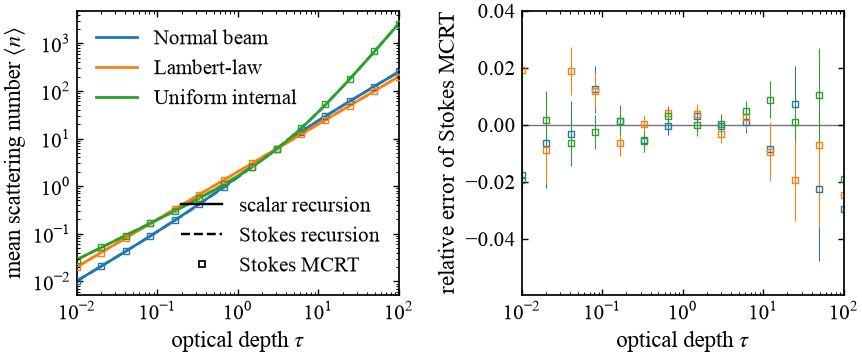

In [17]:
MEAN_MCRT_INDICES = np.unique(
    np.rint(np.linspace(0, MEAN_SCATTER_TAUS.size - 1, 14)).astype(int)
)
MEAN_MCRT_TAUS = MEAN_SCATTER_TAUS[MEAN_MCRT_INDICES]


def _mean_mcrt_event_count(tau: float, source_key: str) -> int:
    if tau < 1.0:
        return 200_000
    if tau < 10.0:
        return 100_000
    if tau < 30.0:
        return 30_000
    if tau < 70.0:
        return 15_000 if source_key != "internal" else 5_000
    return 30_000 if source_key != "internal" else 5_000


def _mean_mcrt_max_scatters(tau: float) -> int:
    return max(512, int(np.ceil(5.0 * tau * tau + 100.0)))


from helpers.mean_validation import load_mean_case
from pathlib import Path
from matplotlib.lines import Line2D

mcrt_mean_results = {}
for tau_index, tau in enumerate(MEAN_MCRT_TAUS):
    tag = f"{tau:.12g}".replace(".", "p").replace("-", "m").replace("+", "")
    for source_index, (source_key, _, _) in enumerate(SOURCE_FACTORIES):
        name = {"beam": "beam", "lambert": "lambert", "internal": "internal_iso"}[source_key]
        directory = Path("data/mean_validation") / name / f"tau_{tag}"
        result = load_mean_case(
            directory, tau, name, _mean_mcrt_event_count(tau, source_key),
            2026084700 + 100*tau_index + 10*source_index + 1,
            _mean_mcrt_max_scatters(tau),
        )
        mcrt_mean_results[tau, source_key] = result
        print(f"tau={tau:.6g} {source_key:8s}: N={result['events']}, "
              f"mean={result['mean']:.7g} +/- {result['standard_error']:.3g}, "
              f"capped={result['terminated']} ({result['termination_fraction']:.2e})")

if plt is None:
    print("Matplotlib is not installed; MCRT mean-scattering data were computed without plotting.")
else:
    fig, axes = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.05), sharex=True,
    )
    ax_mean, ax_residual = axes
    for source_index, (source_key, _, _) in enumerate(SOURCE_FACTORIES):
        color = f"C{source_index}"
        scalar_theory = mean_scattering_results[source_key]["scalar"]
        stokes_theory = mean_scattering_results[source_key]["polarized"]
        ax_mean.plot(
            MEAN_SCATTER_TAUS, scalar_theory, color=color,
            linestyle="-", linewidth=1.55, zorder=1,
        )
        ax_mean.plot(
            MEAN_SCATTER_TAUS, stokes_theory, color=color,
            linestyle="--", linewidth=1.55, zorder=1,
        )
        values = np.array([
            mcrt_mean_results[(tau, source_key)]["mean"]
            for tau in MEAN_MCRT_TAUS
        ])
        errors = np.array([
            mcrt_mean_results[(tau, source_key)]["standard_error"]
            for tau in MEAN_MCRT_TAUS
        ])
        stokes_at_points = stokes_theory[MEAN_MCRT_INDICES]
        ax_mean.errorbar(
            MEAN_MCRT_TAUS, values, yerr=errors, fmt="s",
            linestyle="none", color=color, markerfacecolor="none",
            markersize=4.0, markeredgewidth=0.8, elinewidth=0.6,
            capsize=0, zorder=3,
        )
        residual = (values - stokes_at_points) / stokes_at_points
        ax_residual.errorbar(
            MEAN_MCRT_TAUS, residual, yerr=errors / stokes_at_points,
            fmt="s", linestyle="none", color=color,
            markerfacecolor="none", markersize=4.0, markeredgewidth=0.8,
            elinewidth=0.6, capsize=0,
        )
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlim(MEAN_SCATTER_TAUS[0], MEAN_SCATTER_TAUS[-1])
        ax.set_xlabel(r"optical depth $\tau$")
    ax_mean.set_yscale("log")
    ax_mean.set_ylabel(r"mean scattering number $\langle n\rangle$")
    ax_residual.axhline(0.0, color="0.45", linewidth=0.8, zorder=0)
    ax_residual.set_ylabel("relative error of Stokes MCRT")
    source_handles = [
        Line2D([0], [0], color=f"C{index}", lw=1.6,
               label=MEAN_SOURCE_LABELS[source_key])
        for index, (source_key, _, _) in enumerate(SOURCE_FACTORIES)
    ]
    mode_handles = [
        Line2D([0], [0], color="black", ls="-", lw=1.4,
               label="scalar recursion"),
        Line2D([0], [0], color="black", ls="--", lw=1.4,
               label="Stokes recursion"),
        Line2D([0], [0], color="black", ls="none", marker="s",
               markerfacecolor="none", markersize=4.0, label="Stokes MCRT"),
    ]
    source_legend = ax_mean.legend(handles=source_handles, loc="upper left", frameon=False)
    ax_mean.add_artist(source_legend)
    ax_mean.legend(handles=mode_handles, loc="lower right", frameon=False)
    fig.tight_layout()
    plt.show()

## 9. Optically thin principal eigenmodes and surface distributions


### 9.1. Dominant polarized eigenvectors at finite optical depth

This section computes the principal right eigenvector of the polarized recursion operator,

$$
\mathbb K_{\rm pol}\begin{pmatrix}a_\ast\\b_\ast\end{pmatrix}
=\lambda_0\begin{pmatrix}a_\ast\\b_\ast\end{pmatrix},
$$

for $\tau=0.01,0.03,0.1,0.3,1$. The left panel compares the numerical ratio $b_\ast/a_\ast$ against the strict thin-limit value $-1$, the first logarithmic approximation

$$
\alpha_{\log}(\tau)=-1+\frac{1}{2\ln(1/\tau)},
$$

and the finite-$\tau$ Galerkin value obtained from the quadratic equation for $\alpha(\tau)$. The logarithmic approximation is undefined at $\tau=1$ and is therefore omitted there. The depth eigenfunction $A(t;\tau)\equiv a_\ast(t;\tau)$ is normalized to unit depth average, $\tau^{-1}\int_0^\tau A\,{\rm d}t=1$. The right panel shows the normalized finite-slab depth-operator actions $(\mathcal K_m A)(t;\tau)/\langle A\rangle_t$ for $m=1,3,5$; colours identify optical depth and line styles identify $m$.

#### 9.1.1. Definition of the quadratic approximation

Here "quadratic" refers to the equation for the component ratio
$\alpha=b/a$, not a quadratic polynomial in optical depth. In the
constant-depth Galerkin projection, define

$$
L_m(\tau)=\frac{1}{\tau}\int_0^\tau\!\int_0^\tau
E_m(|t-t'|)\,\mathrm dt'\,\mathrm dt
=\frac{2}{\tau}\left[\frac{\tau}{m}-\frac{1}{m+1}+E_{m+2}(\tau)\right],
\qquad m=1,3,5,
$$

where $E_p(x)=\int_1^\infty e^{-xu}u^{-p}\,\mathrm du$ is the generalized
exponential integral. The projected Stokes recursion matrix is

$$
\overline{\mathbb K}=\frac{3}{16}
\begin{pmatrix}
3L_1-L_3 & -L_1+5L_3-2L_5\\
-L_1+3L_3 & 3L_1-7L_3+6L_5
\end{pmatrix}.
$$

Eliminating the eigenvalue from
$\overline{\mathbb K}(1,\alpha)^{\mathsf T}=\lambda(1,\alpha)^{\mathsf T}$ gives

$$
(L_1-5L_3+2L_5)\alpha^2
-6(L_3-L_5)\alpha-L_1+3L_3=0.
$$

The plotted dominant-eigenvalue branch, continuous with $\alpha\to-1$
as $\tau\to0$, is

$$
\alpha_{\rm quad}(\tau)=
\frac{3(L_3-L_5)-\sqrt{D}}{L_1-5L_3+2L_5},
$$

$$
D=L_1^2-8L_1L_3+2L_1L_5+24L_3^2-24L_3L_5+9L_5^2.
$$

These expressions are implemented below by `projected_Lm` and
`alpha_quadratic_approximation`. This is a projected approximation, not the
exact depth-dependent ratio of the full finite-slab eigenvector. The same
$\alpha_{\rm quad}$ is used in the following surface-observable comparisons.



 tau    lambda_0       iterations    residual       alpha_log    alpha_quadratic
 0.01   0.03607895        46   9.41e-12     -0.891426  -0.878316
 0.03   0.08407087        50   7.21e-12     -0.857410  -0.838150
 0.10   0.19517245        56   8.87e-12     -0.782853  -0.758815
 0.30   0.37446269        65   8.88e-12     -0.584708  -0.619534
 1.00   0.64086217        77   7.81e-12      undefined  -0.354891


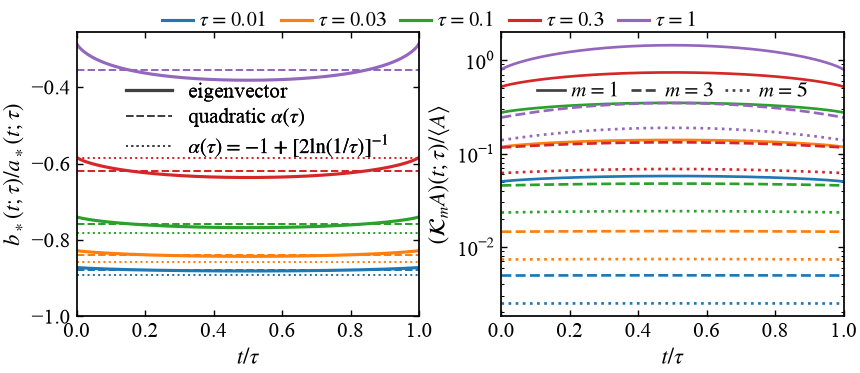

In [18]:
EIGEN_TAUS = (0.01, 0.03, 0.1, 0.3, 1.0)
EIGEN_N_CELLS = 1024
EIGEN_TOL = 1.0e-11
EIGEN_MAX_ITER = 4000
EIGEN_KERNEL_ORDERS = (1, 3, 5)
EIGEN_KERNEL_LINESTYLES = {1: "-", 3: "--", 5: ":"}


def dominant_polarized_eigenmode(
    tau: float, n_cells: int = EIGEN_N_CELLS,
    tol: float = EIGEN_TOL, max_iter: int = EIGEN_MAX_ITER,
):
    """Return the dominant right eigenmode of the polarized FFT operator."""
    grid = SlabGrid(tau=tau, n_cells=n_cells)
    operator = FFTTwoComponentOperator.build(grid, "polarized")
    a = np.ones(n_cells)
    b = -0.5 * np.ones(n_cells)
    norm = np.sqrt(grid.h * np.sum(a * a + b * b))
    a, b = a / norm, b / norm

    for iteration in range(1, max_iter + 1):
        next_a, next_b = operator.step(a, b)
        eigenvalue = grid.h * np.sum(a * next_a + b * next_b)
        next_norm = np.sqrt(grid.h * np.sum(next_a * next_a + next_b * next_b))
        residual = np.sqrt(
            grid.h * np.sum(
                (next_a - eigenvalue * a) ** 2
                + (next_b - eigenvalue * b) ** 2
            )
        ) / next_norm
        a, b = next_a / next_norm, next_b / next_norm
        if np.mean(a) < 0.0:
            a, b = -a, -b
        if residual < tol:
            break
    else:
        raise RuntimeError(f"power iteration did not converge for tau={tau:g}")

    amplitude = a / np.mean(a)
    return {
        "tau": tau, "grid": grid, "operator": operator,
        "eigenvalue": float(eigenvalue), "a": a, "b": b,
        "ratio": b / a, "A_normalized": amplitude,
        "iterations": iteration, "residual": float(residual),
    }


def apply_depth_operator(grid: SlabGrid, m: int, values: np.ndarray) -> np.ndarray:
    """Apply the finite-slab depth operator K_m to cell-centred values."""
    values = np.asarray(values, dtype=float)
    if values.shape != (grid.n_cells,):
        raise ValueError(f"expected an array of length {grid.n_cells}")
    kernel_fft = symmetric_toeplitz_fft(cell_integrated_kernel(grid, m))
    padded = np.zeros(2 * grid.n_cells)
    padded[:grid.n_cells] = values
    transformed = np.fft.rfft(padded)
    result = np.fft.irfft(kernel_fft * transformed, n=2 * grid.n_cells)
    return result[:grid.n_cells]


def projected_Lm(tau: float, m: int) -> float:
    return (2.0 / tau) * (
        tau / m - 1.0 / (m + 1.0) + generalized_expn(m + 2, tau)
    )


def alpha_quadratic_approximation(tau: float) -> float:
    l1, l3, l5 = (projected_Lm(tau, m) for m in (1, 3, 5))
    discriminant = (
        l1**2 - 8.0 * l1 * l3 + 2.0 * l1 * l5
        + 24.0 * l3**2 - 24.0 * l3 * l5 + 9.0 * l5**2
    )
    return (
        3.0 * (l3 - l5) - np.sqrt(max(discriminant, 0.0))
    ) / (l1 - 5.0 * l3 + 2.0 * l5)


def alpha_log_approximation(tau: float) -> float:
    logarithm = np.log(1.0 / tau)
    return np.nan if np.isclose(logarithm, 0.0) else -1.0 + 0.5 / logarithm


eigenmode_results = {
    tau: dominant_polarized_eigenmode(tau) for tau in EIGEN_TAUS
}
eigenmode_kernel_actions = {
    tau: {
        m: apply_depth_operator(
            result["grid"], m, result["a"]
        ) / np.mean(result["a"])
        for m in EIGEN_KERNEL_ORDERS
    }
    for tau, result in eigenmode_results.items()
}

print(" tau    lambda_0       iterations    residual       alpha_log    alpha_quadratic")
for tau in EIGEN_TAUS:
    result = eigenmode_results[tau]
    alpha_log = alpha_log_approximation(tau)
    alpha_log_text = f"{alpha_log: .6f}" if np.isfinite(alpha_log) else "    undefined"
    print(
        f"{tau:5.2f}  {result['eigenvalue']: .8f}  {result['iterations']:8d}  "
        f"{result['residual']: .2e}  {alpha_log_text:>12s}  "
        f"{alpha_quadratic_approximation(tau): .6f}"
    )

if plt is None:
    print("Matplotlib is not installed; eigenvectors were computed without plotting.")
else:
    from matplotlib.lines import Line2D

    fig, axes = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.12)
    )
    ratio_ax, amplitude_ax = axes
    for color_index, tau in enumerate(EIGEN_TAUS):
        result = eigenmode_results[tau]
        depth_fraction = result["grid"].centers / tau
        color = f"C{color_index}"
        ratio_ax.plot(
            depth_fraction, result["ratio"], color=color, linewidth=1.8
        )
        alpha_log = alpha_log_approximation(tau)
        if np.isfinite(alpha_log):
            ratio_ax.axhline(alpha_log, color=color, linestyle=":", linewidth=1.15)
        ratio_ax.axhline(
            alpha_quadratic_approximation(tau), color=color,
            linestyle="--", linewidth=1.15,
        )
        for m in EIGEN_KERNEL_ORDERS:
            amplitude_ax.plot(
                depth_fraction, eigenmode_kernel_actions[tau][m],
                color=color, linestyle=EIGEN_KERNEL_LINESTYLES[m],
                linewidth=1.55,
            )

    ratio_ax.set_xlabel(r"$t/\tau$")
    ratio_ax.set_ylabel(r"$b_\ast(t;\tau)/a_\ast(t;\tau)$")
    ratio_ax.set_xlim(0.0, 1.0)
    ratio_ax.set_ylim(bottom=-1.0)
    amplitude_ax.set_xlabel(r"$t/\tau$")
    amplitude_ax.set_ylabel(r"$(\mathcal{K}_m A)(t;\tau)/\langle A\rangle$")
    amplitude_ax.set_yscale("log")
    amplitude_ax.set_xlim(0.0, 1.0)

    tau_handles = [
        Line2D([0], [0], color=f"C{i}", linewidth=1.8, label=rf"$\tau={tau:g}$")
        for i, tau in enumerate(EIGEN_TAUS)
    ]
    style_handles = [
        Line2D([0], [0], color="0.25", linewidth=1.8, label="eigenvector"),
        Line2D([0], [0], color="0.25", linestyle="--", linewidth=1.15, label=r"quadratic $\alpha(\tau)$"),
        Line2D([0], [0], color="0.25", linestyle=":", linewidth=1.15, label=r"$\alpha(\tau)=-1+[2\ln(1/\tau)]^{-1}$"),
    ]
    style_legend = ratio_ax.legend(
        handles=style_handles, loc="center", bbox_to_anchor=(0.53, 0.69),
        ncol=1, frameon=False, handlelength=2.2, labelspacing=0.3,
        borderaxespad=0.1,
    )
    ratio_ax.add_artist(style_legend)
    kernel_handles = [
        Line2D(
            [0], [0], color="0.25", linestyle=EIGEN_KERNEL_LINESTYLES[m],
            linewidth=1.55, label=rf"$m={m}$",
        )
        for m in EIGEN_KERNEL_ORDERS
    ]
    fig.legend(
        handles=tau_handles, loc="upper center",
        bbox_to_anchor=(0.5, 0.93), ncol=5, frameon=False,
        handlelength=1.5, handletextpad=0.30, columnspacing=0.65,
        labelspacing=0.2, borderaxespad=0.1,
    )
    amplitude_ax.legend(
        handles=kernel_handles, loc="center",
        bbox_to_anchor=(0.5, 0.79), ncol=3, frameon=False,
        handlelength=1.35, handletextpad=0.30, columnspacing=0.50,
        labelspacing=0.25, borderaxespad=0.25,
    )
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.91))
    fig.subplots_adjust(wspace=0.24)
    fig.savefig(FIGURE_DIR / "thin_eigenmode_comparison.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 9.2. Surface polarization and normalized angular distribution

The broad translucent tracks below are obtained by projecting the full numerical principal eigenvector onto the upper surface. The two separable approximations insert either the Galerkin quadratic value or the logarithmic value of $\alpha(\tau)$ into

$$
\Pi_\infty(\mu)=\frac{\alpha(1-\mu^2)}{1+\alpha\mu^2},\qquad
\Phi_\infty(\mu)=\frac{(1+\alpha\mu^2)\mu(1-e^{-\tau/\mu})}{[1/2-E_3(\tau)]+\alpha[1/4-E_5(\tau)]}.
$$

Colours identify optical depth and line styles identify the numerical or approximate construction. The plotted polarization is the signed coefficient $100Q/I$. The first logarithmic approximation is shown only for $\tau<1$: it is undefined at $\tau=1$, while at $\tau=2$ it gives $\alpha<-1$ and hence a non-physical sign change of the approximate intensity.

Polarization and angular distribution are displayed in separate two-column figures. Each left panel contains the numerical tracks and both approximations; each right panel shows the more accurate Galerkin quadratic approximation minus the full numerical eigenmode projection. Polarization residuals are dimensionless differences and are not multiplied by 100.


 tau    integral(Phi_num)    alpha_log       alpha_quadratic
 0.01       1.0000000000       -0.891426       -0.878316
 0.03       1.0000000000       -0.857410       -0.838150
 0.10       1.0000000000       -0.782853       -0.758815
 0.30       1.0000000000       -0.584708       -0.619534
 1.00       1.0000000000       undefined       -0.354891
 2.00       1.0000000000       -1.721348       -0.196854


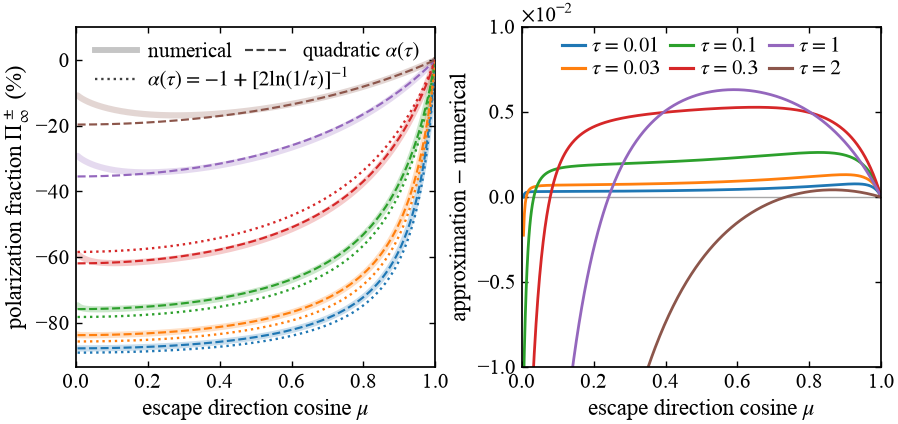

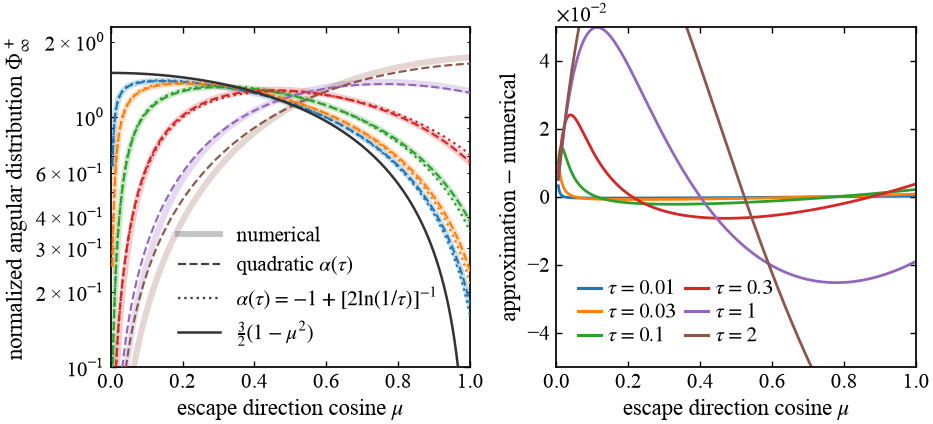

In [19]:
THIN_OBSERVABLE_TAUS = (0.01, 0.03, 0.1, 0.3, 1.0, 2.0)
THIN_OBSERVABLE_MU = np.linspace(0.005, 1.0, 400)


def alpha_surface_observables(tau, alpha, mu):
    """Surface Pi and normalized Phi for a depth-independent b/a=alpha."""
    mu = np.asarray(mu, dtype=float)
    if not np.isfinite(alpha) or alpha <= -1.0:
        return {"Pi": np.full_like(mu, np.nan), "Phi": np.full_like(mu, np.nan)}
    angular_factor = 1.0 + alpha * mu**2
    pi_signed = alpha * (1.0 - mu**2) / angular_factor
    attenuation = -np.expm1(-tau / mu)
    normalization = (
        0.5 - generalized_expn(3, tau)
        + alpha * (0.25 - generalized_expn(5, tau))
    )
    phi = angular_factor * mu * attenuation / normalization
    return {"Pi": pi_signed, "Phi": phi}


thin_observable_modes = {}
for tau in THIN_OBSERVABLE_TAUS:
    thin_observable_modes[tau] = (
        eigenmode_results[tau]
        if tau in eigenmode_results
        else dominant_polarized_eigenmode(tau)
    )

thin_observable_curves = {}
thin_quad_mu, thin_quad_w = legendre_rule(320)
print(" tau    integral(Phi_num)    alpha_log       alpha_quadratic")
for tau in THIN_OBSERVABLE_TAUS:
    mode = thin_observable_modes[tau]
    exact = angular_diagnostics(
        mode["a"], mode["b"], mode["grid"],
        THIN_OBSERVABLE_MU, boundary="+", polarized=True,
    )
    exact_quad = angular_diagnostics(
        mode["a"], mode["b"], mode["grid"],
        thin_quad_mu, boundary="+", polarized=True,
    )
    alpha_log = alpha_log_approximation(tau)
    alpha_quadratic = alpha_quadratic_approximation(tau)
    thin_observable_curves[tau] = {
        "numerical": {"Pi": exact["Pi_signed"], "Phi": exact["Phi"]},
        "quadratic": alpha_surface_observables(
            tau, alpha_quadratic, THIN_OBSERVABLE_MU
        ),
        "logarithmic": alpha_surface_observables(
            tau, alpha_log, THIN_OBSERVABLE_MU
        ),
    }
    log_text = f"{alpha_log: .6f}" if np.isfinite(alpha_log) else " undefined"
    print(
        f"{tau:5.2f}       {thin_quad_w @ exact_quad['Phi']:.10f}"
        f"      {log_text:>10s}       {alpha_quadratic: .6f}"
    )

if plt is None:
    print("matplotlib is not available; skipping the thin-surface figures.")
else:
    from matplotlib.lines import Line2D

    def plot_numerical_track(axis, x, values, color):
        axis.plot(
            x, values, color=color, linestyle="-", linewidth=3.6,
            alpha=0.24, solid_capstyle="round", zorder=1,
        )

    tau_handles = [
        Line2D([0], [0], color=f"C{i}", lw=1.8, label=rf"$\tau={tau:g}$")
        for i, tau in enumerate(THIN_OBSERVABLE_TAUS)
    ]
    style_handles = [
        Line2D([0], [0], color="0.25", ls="-", lw=3.4, alpha=0.3, label="numerical"),
        Line2D([0], [0], color="0.25", ls="--", lw=1.25, label=r"quadratic $\alpha(\tau)$"),
        Line2D([0], [0], color="0.25", ls=":", lw=1.35, label=r"$\alpha(\tau)=-1+[2\ln(1/\tau)]^{-1}$"),
    ]

    # Polarization coefficient and quadratic-alpha residual.
    fig, (ax_function, ax_residual) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.12), sharex=True
    )
    for color_index, tau in enumerate(THIN_OBSERVABLE_TAUS):
        color = f"C{color_index}"
        curves = thin_observable_curves[tau]
        plot_numerical_track(
            ax_function, THIN_OBSERVABLE_MU,
            100.0 * curves["numerical"]["Pi"], color,
        )
        ax_function.plot(
            THIN_OBSERVABLE_MU, 100.0 * curves["quadratic"]["Pi"],
            color=color, linestyle="--", linewidth=1.25, zorder=3,
        )
        ax_function.plot(
            THIN_OBSERVABLE_MU, 100.0 * curves["logarithmic"]["Pi"],
            color=color, linestyle=":", linewidth=1.35, zorder=4,
        )
        ax_residual.plot(
            THIN_OBSERVABLE_MU,
            curves["quadratic"]["Pi"] - curves["numerical"]["Pi"],
            color=color, linewidth=1.6,
        )
    ax_residual.axhline(0.0, color="0.65", linewidth=0.8, zorder=0)
    ax_function.set(
        xlabel=r"escape direction cosine $\mu$", ylabel=r"polarization fraction $\Pi_\infty^\pm$ (%)",
        xlim=(0.0, 1.0), ylim=(None, 10.0),
    )
    ax_residual.set(
        xlabel=r"escape direction cosine $\mu$", ylabel="approximation $-$ numerical",
        xlim=(0.0, 1.0), ylim=(-0.01, 0.01),
    )
    ax_residual.ticklabel_format(
        axis="y", style="sci", scilimits=(-2, -2), useMathText=True
    )
    ax_residual.set_yticks(np.array([-1.0, -0.5, 0.0, 0.5, 1.0]) * 1.0e-2)
    style_legend = ax_function.legend(
        handles=[style_handles[0], style_handles[2]],
        loc="upper left", bbox_to_anchor=(0.03, 0.98),
        ncol=1, handletextpad=0.55, labelspacing=0.25,
        frameon=False, borderaxespad=0.0,
    )
    ax_function.add_artist(style_legend)
    ax_function.legend(
        handles=[style_handles[1]], loc="upper right",
        bbox_to_anchor=(0.98, 0.98), frameon=False, borderaxespad=0.0,
    )
    ax_residual.legend(
        handles=tau_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
        ncol=3, handlelength=1.1, handletextpad=0.35,
        labelspacing=0.15, columnspacing=0.5, frameon=False, borderaxespad=0.1,
    )
    fig.subplots_adjust(left=0.09, right=0.985, bottom=0.16, top=0.97, wspace=0.24)
    fig.savefig(FIGURE_DIR / "thin_polarization_fit.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

    # Normalized angular distribution and quadratic-alpha residual.
    fig, (ax_function, ax_residual) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.12), sharex=True
    )
    for color_index, tau in enumerate(THIN_OBSERVABLE_TAUS):
        color = f"C{color_index}"
        curves = thin_observable_curves[tau]
        plot_numerical_track(
            ax_function, THIN_OBSERVABLE_MU, curves["numerical"]["Phi"], color,
        )
        ax_function.plot(
            THIN_OBSERVABLE_MU, curves["quadratic"]["Phi"],
            color=color, linestyle="--", linewidth=1.25, zorder=3,
        )
        ax_function.plot(
            THIN_OBSERVABLE_MU, curves["logarithmic"]["Phi"],
            color=color, linestyle=":", linewidth=1.35, zorder=4,
        )
        ax_residual.plot(
            THIN_OBSERVABLE_MU,
            curves["quadratic"]["Phi"] - curves["numerical"]["Phi"],
            color=color, linewidth=1.6,
        )
    thin_limit_phi = 1.5 * (1.0 - THIN_OBSERVABLE_MU**2)
    ax_function.plot(
        THIN_OBSERVABLE_MU, thin_limit_phi,
        color="0.20", linestyle="-", linewidth=1.45, zorder=5,
    )
    ax_residual.axhline(0.0, color="0.65", linewidth=0.8, zorder=0)
    ax_function.set(
        xlabel=r"escape direction cosine $\mu$", ylabel=r"normalized angular distribution $\Phi_\infty^+$",
        xlim=(0.0, 1.0), yscale="log", ylim=(0.1, None),
    )
    ax_residual.set(
        xlabel=r"escape direction cosine $\mu$", ylabel="approximation $-$ numerical",
        xlim=(0.0, 1.0), ylim=(-0.05, 0.05),
    )
    ax_residual.ticklabel_format(
        axis="y", style="sci", scilimits=(-2, -2), useMathText=True
    )
    thin_phi_reference_handle = Line2D(
        [0], [0], color="0.20", linestyle="-", linewidth=1.45,
        label=r"$\frac{3}{2}(1-\mu^2)$",
    )
    ax_function.legend(
        handles=style_handles + [thin_phi_reference_handle],
        loc="lower center", bbox_to_anchor=(0.55, 0.03),
        frameon=False, borderaxespad=0.1,
    )
    ax_residual.legend(
        handles=tau_handles, loc="lower left", bbox_to_anchor=(0.03, 0.03),
        ncol=2, handlelength=1.1, handletextpad=0.35,
        columnspacing=0.45, labelspacing=0.2, frameon=False, borderaxespad=0.1,
    )
    fig.subplots_adjust(left=0.09, right=0.985, bottom=0.16, top=0.97, wspace=0.24)
    fig.savefig(FIGURE_DIR / "thin_angular_distribution_fit.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


## 10. Converged thick-limit coefficients


### 10.1. Grid-converged half-space extrapolation

The fixed-\(h\) calculation above is retained as a diagnostic baseline. It does not commute with the limb limit because \(\mu\to0\) samples \(t=h/2\), not \(t=0\). Here the requested \(\tau=50,100,150,200\) modes are recomputed on three successively refined grids. Auxiliary depths \(\tau=40,60,75,125\) overdetermine the \(k^2\) expansion and stabilize \(\bm U_4\). Continuous cubic surface reconstruction and high-order quadrature in the scaled coordinate \(t=\mu x\) resolve the escape kernel.

The production result uses terms through \(k^8\) and a quadratic \(h\to0\) extrapolation. A \(k^{10}\) fit and a finest-two-grid linear extrapolation are carried in parallel as independent sensitivity estimates.


In [20]:
THICK_Z0 = 0.7121
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from scipy.sparse.linalg import LinearOperator, eigs

THICK_TAUS_REQUESTED = (50.0, 100.0, 150.0, 200.0)
THICK_TAUS_AUXILIARY = (40.0, 60.0, 75.0, 125.0)
THICK_TAUS = tuple(sorted(THICK_TAUS_REQUESTED + THICK_TAUS_AUXILIARY))
THICK_GRID_SPACINGS = np.array([0.003125, 0.0015625, 0.00078125])
THICK_SURFACE_MAX = 19.5
THICK_EIGEN_TOL = 1.0e-14
THICK_ESCAPE_QUADRATURE_ORDER = 160
THICK_ESCAPE_X_MAX = 40.0
THICK_MU = np.concatenate([
    [0.0],
    np.geomspace(1.0e-4, 2.0e-2, 120),
    np.linspace(2.2e-2, 1.0, 360),
])
EULER_GAMMA = 0.5772156649015329


def bulk_diffusion_eigenvalue(k):
    """Exact infinite-medium Fourier eigenvalue of the diffusion branch."""
    k = float(k)
    if abs(k) < 1.0e-10:
        l1, l3, l5 = 2.0, 2.0 / 3.0, 2.0 / 5.0
    else:
        l1 = 2.0 * np.arctan(k) / k
        l3 = 2.0 * (k - np.arctan(k)) / k**3
        l5 = 2.0 * (np.arctan(k) - k + k**3 / 3.0) / k**5
    symbol = (3.0 / 16.0) * np.array([
        [3.0 * l1 - l3, -l1 + 5.0 * l3 - 2.0 * l5],
        [-l1 + 3.0 * l3, 3.0 * l1 - 7.0 * l3 + 6.0 * l5],
    ])
    return float(np.max(np.linalg.eigvals(symbol).real))


def thick_principal_eigenmode_converged(tau, h):
    """Solve one principal eigenproblem and retain its near-surface profile."""
    n_cells = int(round(tau / h))
    grid = SlabGrid(tau=tau, n_cells=n_cells)
    fft_operator = FFTTwoComponentOperator.build(grid, "polarized")

    def matvec(state):
        a_next, b_next = fft_operator.step(
            state[:n_cells], state[n_cells:]
        )
        return np.concatenate([a_next, b_next])

    operator = LinearOperator(
        (2 * n_cells, 2 * n_cells), matvec=matvec, dtype=float
    )
    trial = np.zeros(2 * n_cells)
    trial[:n_cells] = np.sin(np.pi * grid.centers / tau)
    eigenvalues, eigenvectors = eigs(
        operator, k=1, which="LR", v0=trial,
        tol=THICK_EIGEN_TOL, maxiter=1600,
    )
    eigenvalue = float(eigenvalues[0].real)
    state = eigenvectors[:, 0].real
    applied = matvec(state)
    residual = (
        np.linalg.norm(applied - eigenvalue * state)
        / np.linalg.norm(applied)
    )
    k_value = brentq(
        lambda k: bulk_diffusion_eigenvalue(k) - eigenvalue,
        0.0, 2.0, xtol=1.0e-14, rtol=1.0e-14,
    )

    a = state[:n_cells].copy()
    b = state[n_cells:].copy()
    if np.mean(a) < 0.0:
        a, b = -a, -b
    center_a = np.interp(0.5 * tau, grid.centers, a)
    a *= (1.0 / k_value) / center_a
    b *= (1.0 / k_value) / center_a
    n_surface = int(round(THICK_SURFACE_MAX / grid.h))
    return {
        "tau": tau, "n_cells": n_cells, "h": grid.h,
        "eigenvalue": eigenvalue, "k": k_value,
        "z_effective": np.pi / (2.0 * k_value) - 0.5 * tau,
        "residual": float(residual),
        "surface_t": grid.centers[:n_surface].copy(),
        "surface_a": a[:n_surface].copy(),
        "surface_b": b[:n_surface].copy(),
    }

thick_principal_eigenmode_converged = cached_transport(thick_principal_eigenmode_converged)


def fit_k2_surface_expansion(results, degree):
    """Overdetermined least-squares extraction of U_0,U_2,..."""
    surface_t = results[THICK_TAUS[0]]["surface_t"]
    k2 = np.array([results[tau]["k"] ** 2 for tau in THICK_TAUS])
    k2_scale = float(np.max(k2))
    design = np.vander(k2 / k2_scale, degree + 1, increasing=True)
    surface_a = np.stack([results[tau]["surface_a"] for tau in THICK_TAUS])
    surface_b = np.stack([results[tau]["surface_b"] for tau in THICK_TAUS])
    scaled_a = np.linalg.lstsq(design, surface_a, rcond=None)[0]
    scaled_b = np.linalg.lstsq(design, surface_b, rcond=None)[0]
    scale = k2_scale ** np.arange(degree + 1)[:, None]
    modes = {
        2 * j: {"a": scaled_a[j] / scale[j], "b": scaled_b[j] / scale[j]}
        for j in range(degree + 1)
    }
    residual = max(
        np.linalg.norm(design @ scaled_a - surface_a) / np.linalg.norm(surface_a),
        np.linalg.norm(design @ scaled_b - surface_b) / np.linalg.norm(surface_b),
    )
    return {
        "surface_t": surface_t, "modes": modes,
        "condition_number": float(np.linalg.cond(design)),
        "relative_fit_residual": float(residual),
    }


# Independent tau and k^2 extrapolations on every h-grid.
thick_grid_solutions = {}
for h in THICK_GRID_SPACINGS:
    eigenmodes = {
        tau: thick_principal_eigenmode_converged(tau, h)
        for tau in THICK_TAUS
    }
    thick_grid_solutions[h] = {
        "eigenmodes": eigenmodes,
        "k8_fit": fit_k2_surface_expansion(eigenmodes, 4),
        "k10_fit": fit_k2_surface_expansion(eigenmodes, 5),
    }


escape_unit_x, escape_unit_w = legendre_rule(THICK_ESCAPE_QUADRATURE_ORDER)
quad_mu, quad_w = legendre_rule(512)
positive_plot_mu = THICK_MU[1:]
projection_mu = np.concatenate([positive_plot_mu, quad_mu])


def continuous_escape_projection(surface_t, mode, mu):
    """Evaluate I and Q after t=mu*x with continuous surface reconstruction."""
    a_spline = CubicSpline(surface_t, mode["a"], extrapolate=True)
    b_spline = CubicSpline(surface_t, mode["b"], extrapolate=True)
    x_upper = np.minimum(THICK_ESCAPE_X_MAX, surface_t[-1] / mu)
    scaled_x = x_upper[:, None] * escape_unit_x[None, :]
    depths = mu[:, None] * scaled_x
    exponential_weights = (
        x_upper[:, None] * escape_unit_w[None, :] * np.exp(-scaled_x)
    )
    a_average = np.sum(exponential_weights * a_spline(depths), axis=1)
    b_average = np.sum(exponential_weights * b_spline(depths), axis=1)
    return {
        "I": mu * (a_average + mu**2 * b_average),
        "Q": mu * (1.0 - mu**2) * b_average,
        "a_boundary": float(a_spline(0.0)),
        "b_boundary": float(b_spline(0.0)),
    }


thick_projected_by_grid = {"k8_fit": {}, "k10_fit": {}}
for fit_name in thick_projected_by_grid:
    for h in THICK_GRID_SPACINGS:
        fitted = thick_grid_solutions[h][fit_name]
        thick_projected_by_grid[fit_name][h] = {
            order: continuous_escape_projection(
                fitted["surface_t"], fitted["modes"][order], projection_mu
            )
            for order in (0, 2, 4)
        }


def extrapolate_h_zero(values, degree):
    """Constant term of a polynomial through the finest degree+1 h-grids."""
    count = degree + 1
    selected_h = THICK_GRID_SPACINGS[-count:]
    design = np.vander(
        selected_h / selected_h[0], count, increasing=True
    )
    return np.linalg.solve(design, np.stack(values[-count:]))[0]


def assemble_half_space_observables(fit_name="k8_fit", h_degree=2):
    """Construct I,Q,A and all six universal functions after h->0."""
    extrapolated = {}
    for order in (0, 2, 4):
        samples = [
            thick_projected_by_grid[fit_name][h][order]
            for h in THICK_GRID_SPACINGS
        ]
        extrapolated[order] = {
            key: extrapolate_h_zero(
                [sample[key] for sample in samples], h_degree
            )
            for key in ("I", "Q", "a_boundary", "b_boundary")
        }

    n_plot = positive_plot_mu.size
    Ip = {j: extrapolated[j]["I"][:n_plot] for j in (0, 2, 4)}
    Qp = {j: extrapolated[j]["Q"][:n_plot] for j in (0, 2, 4)}
    Iq = {j: extrapolated[j]["I"][n_plot:] for j in (0, 2, 4)}
    A = {j: float(quad_w @ Iq[j]) for j in (0, 2, 4)}
    I0p, I2p, I4p = (Ip[j] for j in (0, 2, 4))
    Q0p, Q2p, Q4p = (Qp[j] for j in (0, 2, 4))
    A0p, A2p, A4p = (A[j] for j in (0, 2, 4))

    pi0p = Q0p / I0p
    pi2p = Q2p / I0p - pi0p * I2p / I0p
    pi4p = Q4p / I0p - pi0p * I4p / I0p - pi2p * I2p / I0p
    phi0p = I0p / A0p
    phi2p = I2p / A0p - phi0p * A2p / A0p
    phi4p = I4p / A0p - phi0p * A4p / A0p - phi2p * A2p / A0p

    a0, b0 = extrapolated[0]["a_boundary"], extrapolated[0]["b_boundary"]
    a2, b2 = extrapolated[2]["a_boundary"], extrapolated[2]["b_boundary"]
    a4, b4 = extrapolated[4]["a_boundary"], extrapolated[4]["b_boundary"]
    pi0_limb = b0 / a0
    pi2_limb = b2 / a0 - pi0_limb * a2 / a0
    pi4_limb = b4 / a0 - pi0_limb * a4 / a0 - pi2_limb * a2 / a0

    phi0q = Iq[0] / A0p
    phi2q = Iq[2] / A0p - phi0q * A2p / A0p
    phi4q = Iq[4] / A0p - phi0q * A4p / A0p - phi2q * A2p / A0p
    normalization = np.array([
        quad_w @ phi0q, quad_w @ phi2q, quad_w @ phi4q
    ])
    return {
        "I": {j: np.r_[0.0, Ip[j]] for j in (0, 2, 4)},
        "Q": {j: np.r_[0.0, Qp[j]] for j in (0, 2, 4)},
        "A": A,
        "Pi_Ch": np.r_[pi0_limb, pi0p],
        "Delta_Pi_2": np.r_[pi2_limb, pi2p],
        "Delta_Pi_4": np.r_[pi4_limb, pi4p],
        "Phi_thick": np.r_[0.0, phi0p],
        "Delta_Phi_2": np.r_[0.0, phi2p],
        "Delta_Phi_4": np.r_[0.0, phi4p],
        "normalization": normalization,
    }


thick_converged = assemble_half_space_observables("k8_fit", 2)
thick_h_linear = assemble_half_space_observables("k8_fit", 1)
thick_k10_check = assemble_half_space_observables("k10_fit", 2)

I0, I2, I4 = (thick_converged["I"][j] for j in (0, 2, 4))
Q0, Q2, Q4 = (thick_converged["Q"][j] for j in (0, 2, 4))
A0, A2, A4 = (thick_converged["A"][j] for j in (0, 2, 4))
Pi_Ch_numerical = thick_converged["Pi_Ch"]
Delta_Pi_2_numerical = thick_converged["Delta_Pi_2"]
Delta_Pi_4_numerical = thick_converged["Delta_Pi_4"]
Phi_thick_numerical = thick_converged["Phi_thick"]
Delta_Phi_2_numerical = thick_converged["Delta_Phi_2"]
Delta_Phi_4_numerical = thick_converged["Delta_Phi_4"]


def xi_function(mu):
    """Stable Xi(mu), including its exact value Xi(0)=0."""
    mu = np.asarray(mu, dtype=float)
    xi = np.zeros_like(mu)
    positive = mu > 0.0
    xi[positive] = mu[positive] * np.log1p(1.0 / mu[positive])
    return xi


xi_mu = xi_function(THICK_MU)
Pi_Ch_fit = 0.1171 * (1.0 - THICK_MU) * np.exp(
    -(6.0 / 5.0) * (xi_mu + 0.5 * THICK_MU)
)
Delta_Pi_2_fit = -0.2933 * (1.0 - THICK_MU) * (
    1.0 + 0.9 * (THICK_MU + (4.0 / 15.0) * xi_mu)
)
Delta_Pi_4_fit = 0.2933 * 0.3 * (1.0 - THICK_MU) * (
    1.0 + (8.0 / 7.0) * (
        THICK_MU * (1.0 - THICK_MU)
        - 0.8 * THICK_MU**3 + (5.0 / 16.0) * xi_mu
    )
)
Phi_thick_fit = 0.8227 * THICK_MU * (
    1.0 + 1.5 * THICK_Z0 * THICK_MU
) * np.exp(EULER_GAMMA * xi_mu)
Delta_Phi_2_fit = Phi_thick_fit * (
    0.5960 - THICK_MU / 20.0
    - (9.0 / 7.0) * THICK_MU**2 + xi_mu / 4.0
)
Delta_Phi_4_fit = Phi_thick_fit * (
    -0.0723 + THICK_MU / 20.0
    - (8.0 / 9.0) * THICK_MU**2
    + 1.3 * THICK_MU**4 + xi_mu / 21.0
)

observable_names = (
    "Pi_Ch", "Delta_Pi_2", "Delta_Pi_4",
    "Phi_thick", "Delta_Phi_2", "Delta_Phi_4",
)
fit_arrays = (
    Pi_Ch_fit, Delta_Pi_2_fit, Delta_Pi_4_fit,
    Phi_thick_fit, Delta_Phi_2_fit, Delta_Phi_4_fit,
)

print("Requested-depth eigenproblem diagnostics")
print(" h          tau      lambda_0        k          z_eff      residual")
for h in THICK_GRID_SPACINGS:
    for tau in THICK_TAUS_REQUESTED:
        r = thick_grid_solutions[h]["eigenmodes"][tau]
        print(
            f"{h:9.7f}  {tau:5.0f}  {r['eigenvalue']:.10f}  "
            f"{r['k']:.8f}  {r['z_effective']:.6f}  {r['residual']:.2e}"
        )

print("\nLimb convergence before h extrapolation")
for h in THICK_GRID_SPACINGS:
    boundary = thick_projected_by_grid["k8_fit"][h]
    a0h, b0h = boundary[0]["a_boundary"], boundary[0]["b_boundary"]
    a2h, b2h = boundary[2]["a_boundary"], boundary[2]["b_boundary"]
    a4h, b4h = boundary[4]["a_boundary"], boundary[4]["b_boundary"]
    p0h = b0h / a0h
    p2h = b2h / a0h - p0h * a2h / a0h
    p4h = b4h / a0h - p0h * a4h / a0h - p2h * a2h / a0h
    print(
        f"h={h:.7f}: Pi0={p0h:.9f}, "
        f"DeltaPi2={p2h:.9f}, DeltaPi4={p4h:.9f}"
    )
print(
    f"h->0: Pi0={Pi_Ch_numerical[0]:.9f}, "
    f"DeltaPi2={Delta_Pi_2_numerical[0]:.9f}, "
    f"DeltaPi4={Delta_Pi_4_numerical[0]:.9f}"
)
print("Angular integrals:", {0: A0, 2: A2, 4: A4})
print("Normalization [Phi0, DeltaPhi2, DeltaPhi4]:",
      thick_converged["normalization"])

h_sensitivities = {}
k_fit_sensitivities = {}
for name, fitted in zip(observable_names, fit_arrays):
    numerical = thick_converged[name]
    h_error = np.max(np.abs(numerical - thick_h_linear[name]))
    k_error = np.max(np.abs(numerical - thick_k10_check[name]))
    fit_error = np.max(np.abs(fitted - numerical))
    h_sensitivities[name] = float(h_error)
    k_fit_sensitivities[name] = float(k_error)
    print(
        f"{name:12s}: h sensitivity={h_error:.3e}, "
        f"k-fit sensitivity={k_error:.3e}, "
        f"max |fit-numerical|={fit_error:.3e}"
    )

print(
    f"Pi_Ch limb: numerical={Pi_Ch_numerical[0]:.9f}, "
    f"fit={Pi_Ch_fit[0]:.9f}, "
    f"fit-numerical={Pi_Ch_fit[0] - Pi_Ch_numerical[0]:+.3e}"
)

# Fail loudly if a future change no longer meets the demonstrated tolerances.
convergence_limits = {
    "Pi_Ch": (2.0e-5, 1.0e-8),
    "Delta_Pi_2": (1.0e-5, 1.0e-6),
    "Delta_Pi_4": (2.0e-5, 1.0e-4),
    "Phi_thick": (1.0e-6, 1.0e-8),
    "Delta_Phi_2": (1.0e-6, 1.0e-6),
    "Delta_Phi_4": (2.0e-6, 1.0e-5),
}
for name, (h_limit, k_limit) in convergence_limits.items():
    if h_sensitivities[name] > h_limit:
        raise RuntimeError(f"h convergence target failed for {name}")
    if k_fit_sensitivities[name] > k_limit:
        raise RuntimeError(f"k^2-fit convergence target failed for {name}")

max_eigen_residual = max(
    r["residual"]
    for solution in thick_grid_solutions.values()
    for r in solution["eigenmodes"].values()
)
if max_eigen_residual > 1.0e-11:
    raise RuntimeError("eigensolver convergence target was not met")
normalization_target = np.array([1.0, 0.0, 0.0])
if np.max(np.abs(thick_converged["normalization"] - normalization_target)) > 1.0e-10:
    raise RuntimeError("angular normalization identities were not met")


Requested-depth eigenproblem diagnostics
 h          tau      lambda_0        k          z_eff      residual
0.0031250     50  0.9987590253  0.06109414  0.711079  3.89e-15
0.0031250    100  0.9996803953  0.03097496  0.711819  1.89e-15
0.0031250    150  0.9998565631  0.02074701  0.711948  4.22e-15
0.0031250    200  0.9999189257  0.01559692  0.711984  3.31e-15
0.0015625     50  0.9987590263  0.06109412  0.711089  1.33e-15
0.0015625    100  0.9996803956  0.03097494  0.711841  7.88e-16
0.0015625    150  0.9998565632  0.02074700  0.711981  3.41e-15
0.0015625    200  0.9999189257  0.01559691  0.712029  1.83e-15
0.0007813     50  0.9987590265  0.06109411  0.711092  7.82e-16
0.0007813    100  0.9996803956  0.03097494  0.711846  6.89e-16
0.0007813    150  0.9998565633  0.02074700  0.711989  3.73e-15
0.0007813    200  0.9999189257  0.01559691  0.712040  5.00e-15

Limb convergence before h extrapolation
h=0.0031250: Pi0=0.116869335, DeltaPi2=-0.293442896, DeltaPi4=0.088184466
h=0.0015625: Pi0=0.1

### 10.2. Effective extrapolation length

We obtain the bulk wavenumber $k$ from each finite-slab principal eigenvalue
at total optical depth $\tau$, and calculate

$$
\lambda_D(k)=\lambda_0(\tau),\qquad
z_{\rm eff}(\tau)=\frac{\pi}{2k}-\frac{\tau}{2}.
$$

We tabulate this effective length on three depth grids before extrapolating
to zero grid spacing. We use the cached eigenmodes already loaded above;
we do not launch new eigenproblem calculations or export a figure here.


In [21]:
# We calculate the effective extrapolation length from the cached eigenmodes.
z_effective_diagnostics = []
print(" h           tau       k              z_eff")
for h in THICK_GRID_SPACINGS:
    for tau in THICK_TAUS:
        mode = thick_grid_solutions[h]["eigenmodes"][tau]
        z_eff = np.pi / (2.0 * mode["k"]) - tau / 2.0
        assert np.isclose(z_eff, mode["z_effective"], rtol=0, atol=1e-12)
        z_effective_diagnostics.append((float(h), tau, mode["k"], z_eff))
        print(f"{h:10.8f}  {tau:6.1f}  {mode['k']:.10f}  "
              f"{z_eff:.9f}")


 h           tau       k              z_eff
0.00312500    40.0  0.0758452868  0.710533152
0.00312500    50.0  0.0610941427  0.711078960
0.00312500    60.0  0.0511470451  0.711379807
0.00312500    75.0  0.0411078100  0.711627624
0.00312500   100.0  0.0309749552  0.711819237
0.00312500   125.0  0.0248496913  0.711904948
0.00312500   150.0  0.0207470070  0.711948406
0.00312500   200.0  0.0155969157  0.711984289
0.00156250    40.0  0.0758452583  0.710540939
0.00156250    50.0  0.0610941188  0.711089022
0.00156250    60.0  0.0511470245  0.711392147
0.00156250    75.0  0.0411077930  0.711643383
0.00156250   100.0  0.0309749420  0.711840699
0.00156250   125.0  0.0248496807  0.711932117
0.00156250   150.0  0.0207469980  0.711981282
0.00156250   200.0  0.0155969088  0.712028582
0.00078125    40.0  0.0758452512  0.710542864
0.00078125    50.0  0.0610941129  0.711091516
0.00078125    60.0  0.0511470194  0.711395211
0.00078125    75.0  0.0411077888  0.711647303
0.00078125   100.0  0.0309749388  0.

### 10.3. Reconstruction of $z_0$ and $z_2$

We reconstruct the first two coefficients of the phase-length expansion,

$$z(k)=z_0+z_2k^2+O(k^4).$$

At each of the eight depths $\tau=40,50,60,75,100,125,150,200$, we first
extrapolate the cached principal eigenvalues to $h=0$, invert the bulk
dispersion relation, and form $z_{\rm eff}=\pi/(2k)-\tau/2$.
We evaluate the bulk moments with a small-$k$ series to avoid cancellation.
We then fit in a scaled $k^2$ coordinate, without fixing either coefficient.
We retain higher powers as nuisance terms to reduce finite-$k$ truncation
bias, but extract and report only the intercept $z_0$ and slope $z_2$.

For our reference extraction, we use a quadratic polynomial in $h$ on three
grids and a quadratic polynomial in $k^2$ on all eight depths. We obtain

$$z_0\simeq0.71210975,\qquad z_2\simeq-0.2731668.$$

We assess numerical sensitivity by varying the depth interval, using either
degree two or three in $k^2$, and replacing the mesh extrapolation with a
finest-pair $h^2$ model or a three-grid $h^2+h^3$ model. We report the resulting
ranges as numerical sensitivity estimates, not statistical confidence
intervals. We also show finite-grid fits to illustrate the need for grid
extrapolation; we do not treat a small fit residual alone as proof of convergence.

We use only existing caches and leave the subsequent observable calculations
unchanged. We neither launch new simulations nor save additional figures.


In [22]:
# We extract z0 and z2 without changing the subsequent plotting inputs.
z_h = np.array(THICK_GRID_SPACINGS, dtype=float)
z_tau = np.array(THICK_TAUS, dtype=float)
z_lambda = np.array([
    [thick_grid_solutions[h]["eigenmodes"][tau]["eigenvalue"] for tau in z_tau]
    for h in z_h
])

def z_bulk_lambda(k):
    """Stable bulk diffusion branch for the small-k inversion bracket."""
    l1, l3, l5 = [
        2 * sum((-k*k)**j / (m + 2*j) for j in range(16))
        for m in (1, 3, 5)
    ]
    a, b, c, d = (3/16) * np.array([
        3*l1-l3, -l1+5*l3-2*l5, -l1+3*l3, 3*l1-7*l3+6*l5
    ])
    return (a+d + np.sqrt((a-d)**2 + 4*b*c)) / 2

def z_phase_coordinates(eigenvalues):
    k = np.array([
        brentq(lambda k: z_bulk_lambda(k)-value, 0, 0.2, xtol=5e-16)
        for value in eigenvalues
    ])
    return k**2, np.pi/(2*k) - z_tau/2

def z_fit(eigenvalues, low=40, high=200, degree=2):
    x, values = z_phase_coordinates(eigenvalues)
    use = (z_tau >= low) & (z_tau <= high)
    scale = x[use].max()
    design = np.vander(x[use]/scale, degree+1, increasing=True)
    scaled_coefficients = np.linalg.lstsq(design, values[use], rcond=None)[0]
    residual = np.max(np.abs(design @ scaled_coefficients - values[use]))
    # We discard nuisance coefficients after evaluating the fit residual.
    return (scaled_coefficients / scale**np.arange(degree+1))[:2], residual

print("Finite-grid estimates over tau=40--200")
print("h             z0             z2")
for h, eigenvalues in zip(z_h, z_lambda):
    coefficients, _ = z_fit(eigenvalues)
    print(f"{h:.8f}  {coefficients[0]:.10f}  {coefficients[1]:+.8f}")

z_reconstruction_tests = []
z_reference = None
print("\nh->0 tests: mesh model, tau interval, degree in k^2, z0, z2, residual")
for label, powers, subset in (
    ("quadratic h", (0, 1, 2), slice(None)),
    ("h2 finest pair", (0, 2), slice(1, None)),
    ("h2+h3", (0, 2, 3), slice(None)),
):
    selected_h = z_h[subset] / z_h[subset][0]
    design = np.array([selected_h**power for power in powers]).T
    eigenvalues = np.linalg.solve(design, z_lambda[subset])[0]
    for low, high in ((40, 200), (40, 125), (50, 200), (60, 200)):
        for degree in (2, 3):
            coefficients, residual = z_fit(eigenvalues, low, high, degree)
            z_reconstruction_tests.append(dict(
                mesh_model=label, tau_range=(low, high), degree=degree,
                coefficients=coefficients, max_residual=residual,
            ))
            if label == "quadratic h" and (low, high, degree) == (40, 200, 2):
                z_reference = coefficients.copy()
            print(f"{label:15s} {low:3}-{high:<3} {degree}  "
                  f"{coefficients[0]:.10f} {coefficients[1]:+.8f} "
                  f"{residual:.2e}")

z_test_values = np.array([test["coefficients"] for test in z_reconstruction_tests])
print("\nReference [z0, z2]:", z_reference)
print("Sensitivity minima:", z_test_values.min(axis=0))
print("Sensitivity maxima:", z_test_values.max(axis=0))
assert np.all(np.isfinite(z_test_values))


Finite-grid estimates over tau=40--200
h             z0             z2
0.00312500  0.7120562566  -0.25166365
0.00156250  0.7120964047  -0.26778097
0.00078125  0.7121064293  -0.27181529

h->0 tests: mesh model, tau interval, degree in k^2, z0, z2, residual
quadratic h      40-200 2  0.7121097543 -0.27316678 6.31e-09
quadratic h      40-200 3  0.7121097599 -0.27318022 3.62e-09
quadratic h      40-125 2  0.7121097484 -0.27316264 1.61e-09
quadratic h      40-125 3  0.7121097532 -0.27317048 9.63e-10
quadratic h      50-200 2  0.7121097573 -0.27317285 4.69e-09
quadratic h      50-200 3  0.7121097636 -0.27319176 2.72e-09
quadratic h      60-200 2  0.7121097603 -0.27318039 3.34e-09
quadratic h      60-200 3  0.7121097679 -0.27320855 2.37e-09
h2 finest pair   40-200 2  0.7121097709 -0.27316009 2.08e-09
h2 finest pair   40-200 3  0.7121097727 -0.27316445 1.21e-09
h2 finest pair   40-125 2  0.7121097692 -0.27315889 5.53e-10
h2 finest pair   40-125 3  0.7121097711 -0.27316202 2.57e-10
h2 finest pa

### 10.4. Polarization coefficients and fitting residuals

The left panel draws each numerical function as a broad translucent solid track with a thin solid centreline. The corresponding fit is placed on top as a dotted curve with a narrow white halo, so near-perfect overlap remains directly visible without displacing either curve. The right panel shows **fit minus numerical result** on the same $\mu$ grid.


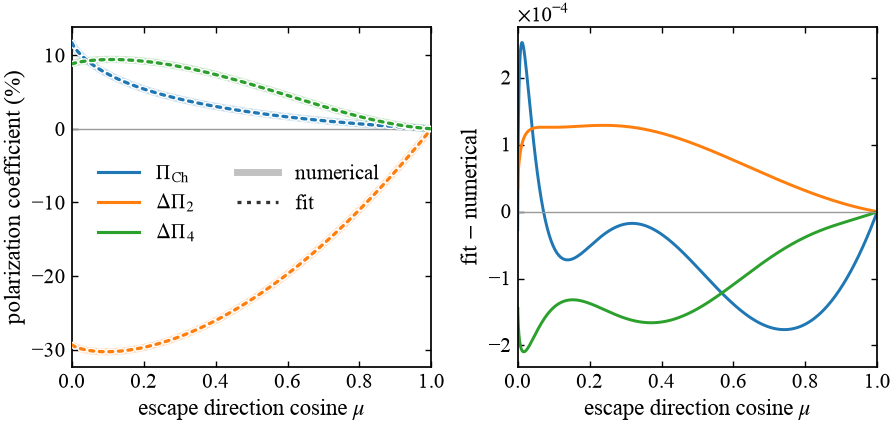

In [23]:
# Compare the numerical polarization coefficients with the manuscript fits.
if plt is None:
    print("matplotlib is not available; skipping the polarization-fit figure.")
else:
    from matplotlib.lines import Line2D
    import matplotlib.patheffects as path_effects

    polarization_series = (
        (r"$\Pi_{\rm Ch}$", Pi_Ch_numerical, Pi_Ch_fit, "C0"),
        (r"$\Delta\Pi_2$", Delta_Pi_2_numerical, Delta_Pi_2_fit, "C1"),
        (r"$\Delta\Pi_4$", Delta_Pi_4_numerical, Delta_Pi_4_fit, "C2"),
    )
    fig, (ax_function, ax_residual) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.12), sharex=True
    )
    for label, numerical, fitted, color in polarization_series:
        ax_function.plot(
            THICK_MU, 100.0 * numerical, color=color, ls="-", lw=4.2,
            alpha=0.24, solid_capstyle="round", zorder=1,
        )
        ax_function.plot(
            THICK_MU, 100.0 * numerical, color=color, ls="-", lw=0.9,
            alpha=0.95, zorder=2,
        )
        fit_line, = ax_function.plot(
            THICK_MU, 100.0 * fitted, color=color, ls=(0, (1.2, 1.7)), lw=1.9,
            dash_capstyle="round", zorder=3,
        )
        fit_line.set_path_effects([
            path_effects.Stroke(linewidth=3.5, foreground="white"),
            path_effects.Normal(),
        ])
        ax_residual.plot(
            THICK_MU, fitted - numerical, color=color, lw=1.7, label=label
        )

    ax_function.axhline(0.0, color="0.6", lw=0.8)
    ax_residual.axhline(0.0, color="0.6", lw=0.8)
    ax_function.set(
        xlabel=r"escape direction cosine $\mu$", ylabel="polarization coefficient (%)",
        xlim=(0.0, 1.0),
    )
    ax_residual.set(xlabel=r"escape direction cosine $\mu$", ylabel="fit $-$ numerical", xlim=(0.0, 1.0))
    ax_residual.ticklabel_format(
        axis="y", style="sci", scilimits=(-4, -4), useMathText=True
    )

    color_handles = [
        Line2D([0], [0], color=color, lw=1.8, label=label)
        for label, _, _, color in polarization_series
    ]
    style_handles = [
        Line2D([0], [0], color="0.2", ls="-", lw=4.0, alpha=0.3, label="numerical"),
        Line2D([0], [0], color="0.2", ls=(0, (1.2, 1.7)), lw=1.9, label="fit"),
    ]
    ax_function.legend(
        handles=color_handles + style_handles, loc="center left",
        bbox_to_anchor=(0.02, 0.48),
        ncol=2, frameon=False
    )
    fig.subplots_adjust(left=0.09, right=0.985, bottom=0.16, top=0.97, wspace=0.24)
    fig.savefig(FIGURE_DIR / "thick_polarization_fit.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 10.5. Angular-distribution coefficients and fitting residuals

The same numerical-track representation is used for $\Phi_{\rm thick}$, $\Delta\Phi_2$, and $\Delta\Phi_4$: the broad translucent solid curve is numerical, while the haloed dotted curve is the fit. The right panel again displays **fit minus numerical result**.


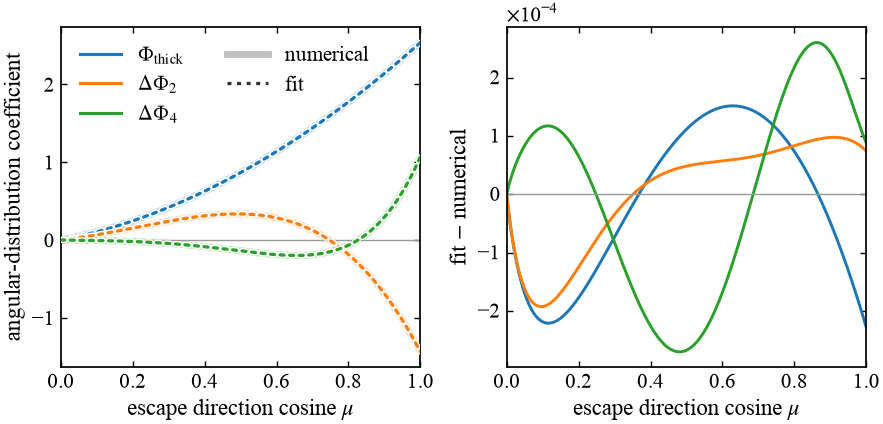

In [24]:
# Compare the numerical angular-distribution coefficients with the fits.
if plt is None:
    print("matplotlib is not available; skipping the angular-fit figure.")
else:
    import matplotlib.patheffects as path_effects
    angular_series = (
        (r"$\Phi_{\rm thick}$", Phi_thick_numerical, Phi_thick_fit, "C0"),
        (r"$\Delta\Phi_2$", Delta_Phi_2_numerical, Delta_Phi_2_fit, "C1"),
        (r"$\Delta\Phi_4$", Delta_Phi_4_numerical, Delta_Phi_4_fit, "C2"),
    )
    fig, (ax_function, ax_residual) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.12), sharex=True
    )
    for label, numerical, fitted, color in angular_series:
        ax_function.plot(
            THICK_MU, numerical, color=color, ls="-", lw=4.2,
            alpha=0.24, solid_capstyle="round", zorder=1,
        )
        ax_function.plot(
            THICK_MU, numerical, color=color, ls="-", lw=0.9,
            alpha=0.95, zorder=2,
        )
        fit_line, = ax_function.plot(
            THICK_MU, fitted, color=color, ls=(0, (1.2, 1.7)), lw=1.9,
            dash_capstyle="round", zorder=3,
        )
        fit_line.set_path_effects([
            path_effects.Stroke(linewidth=3.5, foreground="white"),
            path_effects.Normal(),
        ])
        ax_residual.plot(
            THICK_MU, fitted - numerical, color=color, lw=1.7, label=label
        )

    ax_function.axhline(0.0, color="0.6", lw=0.8)
    ax_residual.axhline(0.0, color="0.6", lw=0.8)
    ax_function.set(xlabel=r"escape direction cosine $\mu$", ylabel="angular-distribution coefficient", xlim=(0.0, 1.0))
    ax_residual.set(xlabel=r"escape direction cosine $\mu$", ylabel="fit $-$ numerical", xlim=(0.0, 1.0))
    ax_residual.ticklabel_format(
        axis="y", style="sci", scilimits=(-4, -4), useMathText=True
    )

    color_handles = [
        Line2D([0], [0], color=color, lw=1.8, label=label)
        for label, _, _, color in angular_series
    ]
    style_handles = [
        Line2D([0], [0], color="0.2", ls="-", lw=4.0, alpha=0.3, label="numerical"),
        Line2D([0], [0], color="0.2", ls=(0, (1.2, 1.7)), lw=1.9, label="fit"),
    ]
    ax_function.legend(
        handles=color_handles + style_handles, loc="upper left",
        ncol=2, frameon=False
    )
    fig.subplots_adjust(left=0.09, right=0.985, bottom=0.16, top=0.97, wspace=0.24)
    fig.savefig(FIGURE_DIR / "thick_angular_distribution_fit.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


## 11. Finite-thickness surface distributions


### 11.1. Finite-thickness polarization and angular distributions

The analytic curves use only the wavenumber approximation given in the manuscript,

$$
k_1=\frac{\pi}{\tau+2z_0},\qquad z_0=0.7121,
$$

and the six compact analytic fits for $\Pi_{\rm Ch}$, $\Delta\Pi_2$,
$\Delta\Pi_4$, $\Phi_{\rm thick}$, $\Delta\Phi_2$, and $\Delta\Phi_4$.
The dashed and dotted curves retain the $k_1^2$ and $k_1^4$ corrections, respectively.
No numerically inferred wavenumber or numerical expansion coefficient enters
these approximations. Independently solved finite-slab eigenmodes provide the
strict numerical benchmarks, displayed as translucent tracks.

The two figures show polarization and normalized angular distribution at
$\tau=2,3,5,10$; $\tau=20$ is evaluated for diagnostics only. The polarization
left panel also includes the numerical half-space limit and its compact fit.
The right panels show the full $k_1^4$ manuscript approximation minus the
finite-slab numerical result, including wavenumber, coefficient-fit, and
truncation errors. No half-space residual is plotted. Polarization on the left
is in percent, whereas residuals are dimensionless fractions.

The angular-distribution axis is linear, and the y-axis limits are automatic.
The printed angular fits are used without post-hoc renormalization; their
integrals are reported so that rounding errors remain visible. The $\tau=2$
curves are a boundary-of-validity test rather than a controlled thick-limit
prediction. Only these two manuscript-formula figures are displayed and saved
as **finite_thickness_polarization_fit.pdf** and
**finite_thickness_angular_distribution_fit.pdf**.


 tau       residual       integral(Phi_num)
  2.0   5.20e-16       1.0000000000
  3.0   1.11e-15       1.0000000000
  5.0   1.74e-15       1.0000000000
 10.0   1.76e-15       1.0000000000
 20.0   2.77e-15       1.0000000000

Manuscript formulas: k1 = pi/(tau + 2*0.7121), compact coefficient fits
 tau     k_paper      max|dPi|     max|dPhi|    integral(Phi_paper)
  2.0  0.91746763  3.648e-02  3.565e-01      0.99998720
  3.0  0.71009282  1.204e-02  1.012e-01      0.99998610
  5.0  0.48902473  2.605e-03  1.661e-02      0.99998536
 10.0  0.27499454  4.216e-04  8.121e-04      0.99998495
 20.0  0.14663757  2.627e-04  2.268e-04      0.99998482


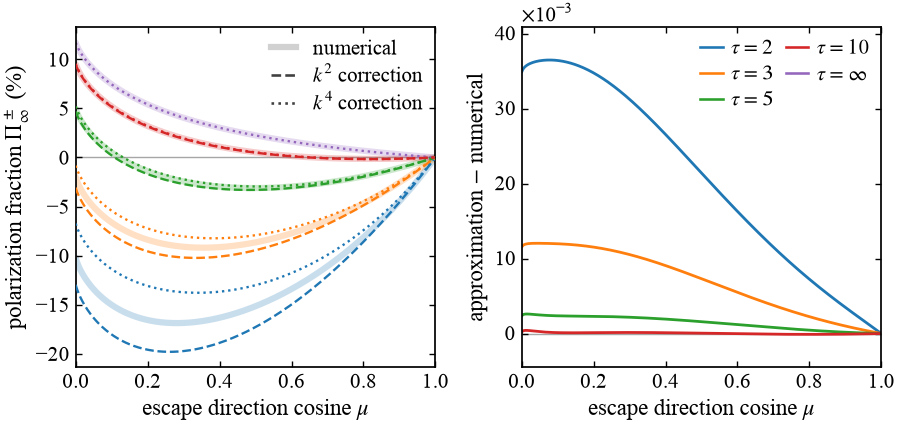

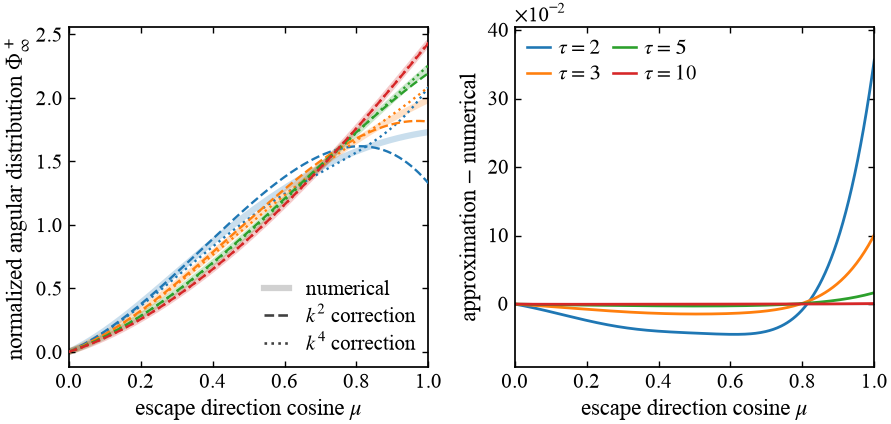

In [25]:
FINITE_THICK_TAUS = (2.0, 3.0, 5.0, 10.0, 20.0)
FINITE_THICK_GRID_SPACING = float(THICK_GRID_SPACINGS[-1])
finite_thick_check_mu, finite_thick_check_w = legendre_rule(384)

finite_thick_modes = {
    tau: thick_principal_eigenmode_converged(tau, FINITE_THICK_GRID_SPACING)
    for tau in FINITE_THICK_TAUS
}


def finite_mode_surface_observables(mode):
    """Continuous finite-slab escape projection on THICK_MU, including the limb."""
    surface_mode = {"a": mode["surface_a"], "b": mode["surface_b"]}
    positive_mu = THICK_MU[1:]
    evaluation_mu = np.concatenate([positive_mu, quad_mu, finite_thick_check_mu])
    projected = continuous_escape_projection(
        mode["surface_t"], surface_mode, evaluation_mu
    )
    n_plot = positive_mu.size
    intensity_plot = projected["I"][:n_plot]
    q_plot = projected["Q"][:n_plot]
    n_normalization = quad_mu.size
    intensity_quad = projected["I"][n_plot:n_plot + n_normalization]
    intensity_check = projected["I"][n_plot + n_normalization:]
    angular_integral = float(quad_w @ intensity_quad)
    pi_limb = projected["b_boundary"] / projected["a_boundary"]
    return {
        "Pi": np.r_[pi_limb, q_plot / intensity_plot],
        "Phi": np.r_[0.0, intensity_plot / angular_integral],
        "normalization": angular_integral,
        "normalization_check": float(
            finite_thick_check_w @ intensity_check / angular_integral
        ),
    }


# Strict finite-slab solutions are benchmarks, not inputs to the analytic approximation.
finite_thick_curves = {}
print(" tau       residual       integral(Phi_num)")
for tau in FINITE_THICK_TAUS:
    mode = finite_thick_modes[tau]
    exact = finite_mode_surface_observables(mode)
    finite_thick_curves[tau] = {"numerical": exact}
    print(f"{tau:5.1f}   {mode['residual']:.2e}       {exact['normalization_check']:.10f}")


# Manuscript-only comparison: no numerical eigenvalue or coefficient in the approximation.
def manuscript_thick_observables(tau, mu):
    """Printed compact fits and k1 = pi/(tau + 2 z0); no renormalization."""
    if tau <= 0 or np.isnan(tau):
        raise ValueError("tau must be positive")
    mu = np.asarray(mu, dtype=float)
    xi = np.zeros_like(mu)
    positive = mu > 0
    xi[positive] = mu[positive] * np.log1p(1.0 / mu[positive])
    k = np.pi / (float(tau) + 2 * 0.7121)
    pi0 = 0.1171 * (1 - mu) * np.exp(-1.2 * (xi + mu / 2))
    pi2 = -0.2933 * (1 - mu) * (1 + 0.9 * (mu + 4 * xi / 15))
    pi4 = 0.2933 * 0.3 * (1 - mu) * (
        1 + 8 / 7 * (mu * (1 - mu) - 0.8 * mu**3 + 5 * xi / 16)
    )
    phi0 = 0.8227 * mu * (1 + 1.5 * 0.7121 * mu) * np.exp(
        0.5772156649015329 * xi
    )
    phi2 = phi0 * (0.5960 - mu / 20 - 9 * mu**2 / 7 + xi / 4)
    phi4 = phi0 * (-0.0723 + mu / 20 - 8 * mu**2 / 9 + 1.3 * mu**4 + xi / 21)
    coefficients = {"Pi": (pi0, pi2, pi4), "Phi": (phi0, phi2, phi4)}
    return {
        "k": k,
        "k2": {name: c0 + k**2 * c2 for name, (c0, c2, c4) in coefficients.items()},
        "k4": {
            name: c0 + k**2 * c2 + k**4 * c4
            for name, (c0, c2, c4) in coefficients.items()
        },
    }


manuscript_thick_curves = {
    tau: manuscript_thick_observables(tau, THICK_MU) for tau in FINITE_THICK_TAUS
}
print("\nManuscript formulas: k1 = pi/(tau + 2*0.7121), compact coefficient fits")
print(" tau     k_paper      max|dPi|     max|dPhi|    integral(Phi_paper)")
for tau, approximation in manuscript_thick_curves.items():
    reference = finite_thick_curves[tau]["numerical"]
    phi_quad = manuscript_thick_observables(tau, quad_mu)["k4"]["Phi"]
    print(
        f"{tau:5.1f}  {approximation['k']:.8f}"
        f"  {np.max(np.abs(approximation['k4']['Pi'] - reference['Pi'])):.3e}"
        f"  {np.max(np.abs(approximation['k4']['Phi'] - reference['Phi'])):.3e}"
        f"      {float(quad_w @ phi_quad):.8f}"
    )

if plt is not None:
    from matplotlib.lines import Line2D
    manuscript_taus = FINITE_THICK_TAUS[:4]
    manuscript_styles = [
        Line2D([0], [0], color="0.25", lw=3.6, alpha=0.24, label="numerical"),
        Line2D([0], [0], color="0.25", ls="--", label=r"$k^2$ correction"),
        Line2D([0], [0], color="0.25", ls=":", label=r"$k^4$ correction"),
    ]
    for name, scale, ylabel, filename in (
        ("Pi", 100, r"polarization fraction $\Pi_\infty^\pm$ (%)",
         "finite_thickness_polarization_fit.pdf"),
        ("Phi", 1, r"normalized angular distribution $\Phi_\infty^+$",
         "finite_thickness_angular_distribution_fit.pdf"),
    ):
        fig, (ax_function, ax_residual) = plt.subplots(
            1, 2, figsize=get_double_column_size(row_height_scale=1.12), sharex=True
        )
        tau_handles = []
        for index, tau in enumerate(manuscript_taus):
            color = f"C{index}"
            reference = finite_thick_curves[tau]["numerical"][name]
            approximation = manuscript_thick_curves[tau]
            plot_numerical_track(ax_function, THICK_MU, scale * reference, color)
            for order, linestyle in (("k2", "--"), ("k4", ":")):
                ax_function.plot(
                    THICK_MU, scale * approximation[order][name],
                    color=color, ls=linestyle, lw=1.35, zorder=3,
                )
            # Polarization errors are fractions, NOT percentage points.
            ax_residual.plot(
                THICK_MU, approximation["k4"][name] - reference, color=color, lw=1.6
            )
            tau_handles.append(
                Line2D([0], [0], color=color, label=rf"$\tau={tau:g}$")
            )
        if name == "Pi":
            color = f"C{len(manuscript_taus)}"
            plot_numerical_track(ax_function, THICK_MU, 100 * Pi_Ch_numerical, color)
            ax_function.plot(
                THICK_MU, 100 * manuscript_thick_observables(np.inf, THICK_MU)["k4"]["Pi"],
                color=color, ls=":", lw=1.35,
            )
            tau_handles.append(Line2D([0], [0], color=color, label=r"$\tau=\infty$"))
            ax_function.axhline(0, color="0.65", lw=0.8, zorder=0)
        else:
            ax_function.set_yscale("linear")
        ax_function.set(xlabel=r"escape direction cosine $\mu$", ylabel=ylabel, xlim=(0, 1))
        ax_residual.set(
            xlabel=r"escape direction cosine $\mu$",
            ylabel="approximation $-$ numerical", xlim=(0, 1),
        )
        ax_residual.axhline(0, color="0.65", lw=0.8, zorder=0)
        # Autoscale the total manuscript-approximation residuals.
        ax_residual.margins(y=0.12)
        exponent = -3 if name == "Pi" else -2
        ax_residual.ticklabel_format(
            axis="y", style="sci", scilimits=(exponent, exponent), useMathText=True
        )
        ax_function.legend(
            handles=manuscript_styles, loc="upper right" if name == "Pi" else "lower right",
            handlelength=1.2, labelspacing=0.2, frameon=False, borderaxespad=0.2,
        )
        ax_residual.legend(
            handles=tau_handles, loc="best", ncol=2, handlelength=1.1,
            handletextpad=0.4, labelspacing=0.3, columnspacing=0.6,
            frameon=False, borderaxespad=0.2,
        )
        fig.subplots_adjust(left=0.09, right=0.985, bottom=0.16, top=0.97, wspace=0.24)
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight", pad_inches=0.02)
        plt.show()


### 11.2. Sixth-order surface expansion: derivation and diagnostic comparison

We extend the even-wavenumber expansion to sixth order. This is a supporting
numerical experiment, separate from the compact formulas used in the preceding
figures. We use numerical coefficient functions for **both** truncations, so
that their difference isolates the added sixth-order term rather than a change
in the compact fitting formulas.

#### 11.2.1. Bulk dispersion and the half-space hierarchy

For the Fourier symbol of the transport kernels we have

$$L_m(k)=2\int_0^1\frac{u^{m-1}}{1+k^2u^2}\,du
=2\sum_{r=0}^{\infty}\frac{(-1)^r k^{2r}}{m+2r},\qquad m=1,3,5.$$

Inserting these series into the polarized two-component matrix in Section 3
and expanding its diffusion eigenvalue gives

$$\lambda_D(k)=1-\frac{k^2}{3}+\frac{31k^4}{135}
-\frac{1483k^6}{8505}+O(k^8).$$

For the bulk eigenvector normalized to unit first component, we similarly obtain

$$\frac{b}{a}=-\frac{k^2}{3}+\frac{20k^4}{189}
-\frac{440k^6}{11907}+O(k^8).$$

Writing the near-surface mode as
$\boldsymbol U=\boldsymbol U_0+k^2\boldsymbol U_2+k^4\boldsymbol U_4+k^6\boldsymbol U_6+O(k^8)$,
and equating powers in $\mathbb K_H\boldsymbol U=\lambda_D(k)\boldsymbol U$,
where $\mathbb K_H$ is the half-space transport operator, yields

$$
\begin{aligned}
(\mathbb I-\mathbb K_H)\boldsymbol U_0&=0,\\
(\mathbb I-\mathbb K_H)\boldsymbol U_2&=\tfrac13\boldsymbol U_0,\\
(\mathbb I-\mathbb K_H)\boldsymbol U_4&=\tfrac13\boldsymbol U_2-\tfrac{31}{135}\boldsymbol U_0,\\
(\mathbb I-\mathbb K_H)\boldsymbol U_6&=\tfrac13\boldsymbol U_4-\tfrac{31}{135}\boldsymbol U_2
+\tfrac{1483}{8505}\boldsymbol U_0.
\end{aligned}
$$

These equations also require vacuum-boundary and bulk-matching conditions;
they do not determine the homogeneous contributions by themselves. We retain
the common eigenvector normalization and finite-slab extrapolation of Section 10.

#### 11.2.2. Escape projection and normalized observables

The escape projection is linear. We write
$I=I_0+k^2I_2+k^4I_4+k^6I_6+O(k^8)$ and likewise for $Q$, and define
$A_{2r}=\int_0^1 I_{2r}(\mu)\,d\mu$.
Expanding the ratios $\Pi=Q/I$ and $\Phi=I/A$ then gives

$$\Delta\Pi_6=\frac{Q_6-\Pi_{\rm Ch}I_6-\Delta\Pi_2 I_4-\Delta\Pi_4 I_2}{I_0},$$
$$\Delta\Phi_6=\frac{I_6-\Phi_{\rm thick}A_6-\Delta\Phi_2 A_4-\Delta\Phi_4 A_2}{A_0}.$$

Thus $X^{[6]}=X^{[4]}+k^6\Delta X_6$, for $X=\Pi,\Phi$.
We check $\int\Phi_0\,d\mu=1$ and $\int\Delta\Phi_{2r}\,d\mu=0$.
At the limb we evaluate polarization using the boundary limits of $a$ and $b$,
not the undefined ratio of two zero escaping intensities.

#### 11.2.3. Numerical scope and absolute residuals

We extract coefficients from the eight cached thick slabs on three depth grids,
using a polynomial through $k^8$, and repeat with a $k^{10}$ polynomial and a
linear rather than quadratic grid extrapolation. The shaded envelope shows
this sensitivity, **not a statistical confidence interval**. In particular,
the extracted sixth-order polarization coefficient is not yet fully converged;
we do not claim uniform sixth-order accuracy from this diagnostic.

For every reconstruction below we use only $k=\pi/(\tau+2z_0)$, $z_0=0.7121$.
The error therefore includes the error in this leading wavenumber approximation.
We compare with the full finite-slab numerical mode and plot the signed
absolute residual $X^{[p]}-X_{\rm num}$, without division by the numerical
reference. Both residual axes are linear; zero crossings and endpoints are
retained. Polarization residuals are dimensionless fractions, not percentages,
although the polarization curves in the left panel are displayed in percent.
These figures are displayed only, not saved.


Angular normalization through k^6: [1.0, -5.892638807458717e-17, -7.779997620530749e-17, 1.0586217774784246e-17]
Pi k10 max coefficient differences (0,2,4,6): [0.       0.       0.000031 0.016603]
Pi h_linear max coefficient differences (0,2,4,6): [0.000009 0.000004 0.000005 0.001205]
Phi k10 max coefficient differences (0,2,4,6): [0.       0.       0.000001 0.000919]
Phi h_linear max coefficient differences (0,2,4,6): [0.       0.       0.       0.000042]


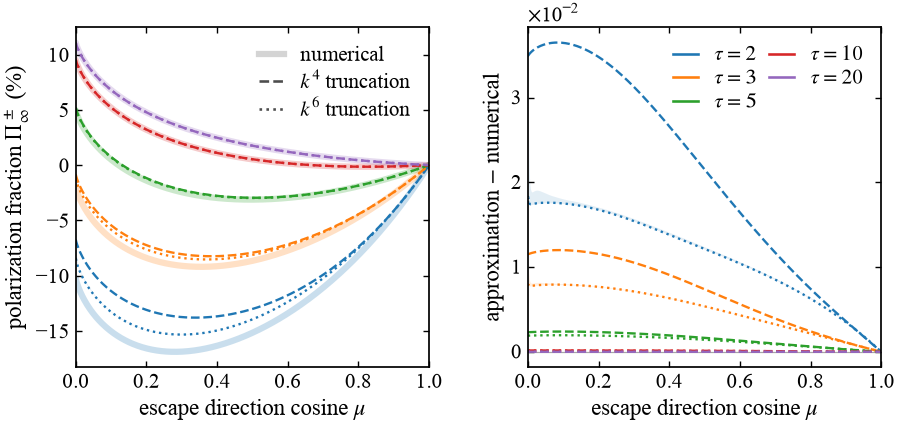

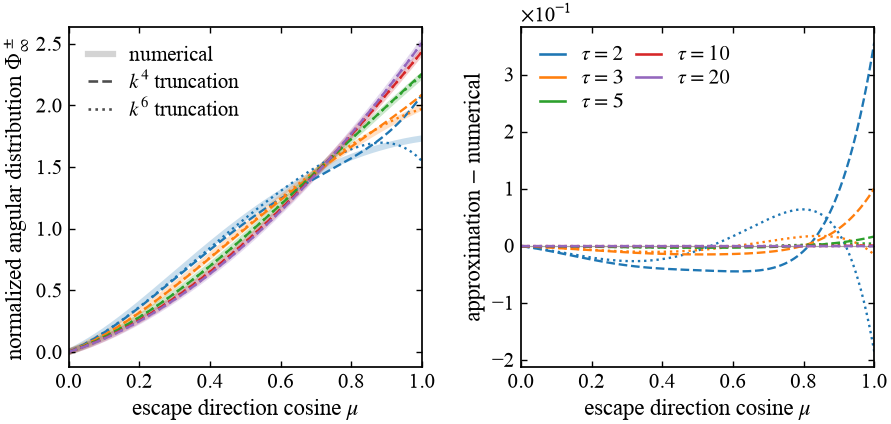

In [26]:
# Reuse the cached eigenmodes; no eigensolver or MCRT rerun is needed.
def sixth_order_surface_coefficients():
    hs = THICK_GRID_SPACINGS
    mu = THICK_MU
    nplot = len(mu)-1
    projected = {}
    for fit_name in ('k8_fit','k10_fit'):
        projected[fit_name] = {}
        for h in hs:
            fitted = thick_grid_solutions[h][fit_name]
            projected[fit_name][h] = {
                order:continuous_escape_projection(fitted['surface_t'],fitted['modes'][order],projection_mu)
                for order in (0,2,4,6)
            }
    
    def coefficients(fit_name='k8_fit',h_degree=2):
        p = {}
        for order in (0,2,4,6):
            p[order] = {key:extrapolate_h_zero(
                [projected[fit_name][h][order][key] for h in hs],h_degree)
                for key in ('I','Q','a_boundary','b_boundary')}
        # At mu=0 both I and Q vanish. Use their boundary limits to divide safely.
        ii = [np.r_[p[o]['a_boundary'],p[o]['I'][:nplot]] for o in (0,2,4,6)]
        qq = [np.r_[p[o]['b_boundary'],p[o]['Q'][:nplot]] for o in (0,2,4,6)]
        aq = [float(quad_w @ p[o]['I'][nplot:]) for o in (0,2,4,6)]
        pi,phi = [],[]
        for j in range(4):
            pi.append((qq[j]-sum(ii[l]*pi[j-l] for l in range(1,j+1)))/ii[0])
            field = np.r_[0.,p[2*j]['I'][:nplot]]
            phi.append((field-sum(aq[l]*phi[j-l] for l in range(1,j+1)))/aq[0])
        # Audit the angular integral coefficient identities also at sixth order.
        phi_quad=[]
        for j in range(4):
            field=p[2*j]['I'][nplot:]
            phi_quad.append((field-sum(aq[l]*phi_quad[j-l] for l in range(1,j+1)))/aq[0])
        normalization = [float(quad_w @ x) for x in phi_quad]
        return dict(Pi=np.array(pi),Phi=np.array(phi),A=aq,normalization=normalization)
    
    base = coefficients()
    checks = {'k10':coefficients('k10_fit',2),'h_linear':coefficients('k8_fit',1)}
    return base, checks

sixth_base, sixth_checks = sixth_order_surface_coefficients()
assert np.max(np.abs(np.array(sixth_base['normalization'])-[1,0,0,0])) < 1e-8
print("Angular normalization through k^6:", sixth_base['normalization'])
for name in ('Pi', 'Phi'):
    for check_name, candidate in sixth_checks.items():
        print(name, check_name, "max coefficient differences (0,2,4,6):",
              np.max(np.abs(candidate[name]-sixth_base[name]), axis=1))

def sixth_order_prediction(coefficients, name, k, order):
    return sum(k**(2*j)*coefficients[name][j] for j in range(order//2+1))

if plt is not None:
    from matplotlib.lines import Line2D
    for name, scale, label in (
        ('Pi',100,r'polarization fraction $\Pi_\infty^\pm$ (%)'),
        ('Phi',1,r'normalized angular distribution $\Phi_\infty^\pm$'),
    ):
        fig, (left, right) = plt.subplots(1,2,
            figsize=get_double_column_size(row_height_scale=1.12),sharex=True)
        tau_handles=[]
        for index,tau in enumerate((2.,3.,5.,10.,20.)):
            color=f'C{index}'
            k=np.pi/(tau+2*THICK_Z0)
            reference=finite_thick_curves[tau]['numerical'][name]
            plot_numerical_track(left,THICK_MU,scale*reference,color)
            for order,style in ((4,'--'),(6,':')):
                prediction=sixth_order_prediction(sixth_base,name,k,order)
                left.plot(THICK_MU,scale*prediction,color=color,ls=style,lw=1.35)
                right.plot(THICK_MU,prediction-reference,
                           color=color,ls=style,lw=1.35)
            variants=np.stack([sixth_order_prediction(c,name,k,6)
                               for c in (sixth_base,*sixth_checks.values())])
            low,high=variants.min(axis=0),variants.max(axis=0)
            left.fill_between(THICK_MU,scale*low,scale*high,color=color,alpha=.12,lw=0)
            e1,e2=low-reference,high-reference
            right.fill_between(THICK_MU,np.minimum(e1,e2),np.maximum(e1,e2),
                               color=color,alpha=.12,lw=0)
            tau_handles.append(Line2D([],[],color=color,label=rf'$\tau={tau:g}$'))
        for ax in (left,right):
            ax.set(xlim=(0,1),xlabel=r'escape direction cosine $\mu$')
        left.set_ylabel(label)
        right.set_ylabel('approximation $-$ numerical')
        right.set_yscale('linear')
        right.ticklabel_format(axis='y',style='sci',scilimits=(0,0),useMathText=True)
        right.axhline(0,color='.65',lw=.7,zorder=0)
        left.legend(handles=[
            Line2D([],[],color='.3',lw=3.6,alpha=.24,label='numerical'),
            Line2D([],[],color='.3',ls='--',label=r'$k^4$ truncation'),
            Line2D([],[],color='.3',ls=':',label=r'$k^6$ truncation')],
            loc='best',frameon=False,handlelength=1.2,labelspacing=.2)
        right.legend(handles=tau_handles,loc='best',ncol=2,frameon=False,
                     handlelength=1.2,columnspacing=.6,labelspacing=.2)
        fig.subplots_adjust(left=.09,right=.985,bottom=.16,top=.97,wspace=.28)
        plt.show()


## 12. Principal eigenvalue and projected channel diagnostics


### 12.1. Principal eigenvalue and approximation errors

We compare the scalar and Stokes principal eigenvalues and evaluate approximation errors relative to the Stokes result.


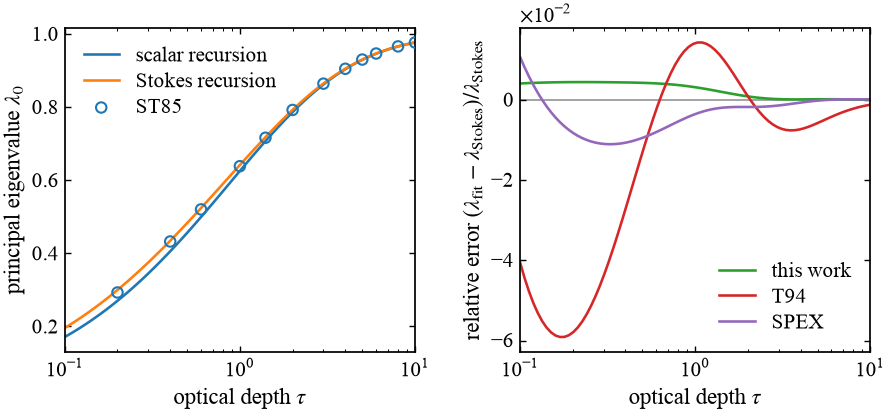

In [27]:
# Principal eigenvalue of the scalar and Stokes recursion operators.
# ST85 Table 1 uses the slab semithickness tau_0 and an escape tail
# exp(-beta n); in the present convention tau=2*tau_0 and lambda_0=exp(-beta).
from plot_style import get_double_column_size

SPECTRAL_TAUS = np.geomspace(0.1, 10.0, 80)
SPECTRAL_N_CELLS = 1024
SPECTRAL_TOL = 3.0e-11
SPECTRAL_MAX_ITER = 4000


def principal_eigenvalue_curve(taus, kind, n_cells=SPECTRAL_N_CELLS):
    """Normalized FFT power iteration, continued from one tau to the next."""
    taus = np.asarray(taus, dtype=float)
    eigenvalues = np.empty_like(taus)
    iterations = np.empty(taus.size, dtype=int)
    a = np.ones(n_cells)
    b = np.full(n_cells, -1.0 / 3.0 if kind == "scalar" else -1.0)

    for tau_index, tau in enumerate(taus):
        grid = SlabGrid(tau=float(tau), n_cells=n_cells)
        operator = FFTTwoComponentOperator.build(grid, kind)
        norm = np.sqrt(grid.h * np.sum(a * a + b * b))
        a, b = a / norm, b / norm

        for iteration in range(1, SPECTRAL_MAX_ITER + 1):
            next_a, next_b = operator.step(a, b)
            eigenvalue = grid.h * np.sum(a * next_a + b * next_b)
            next_norm = np.sqrt(grid.h * np.sum(next_a * next_a + next_b * next_b))
            residual = np.sqrt(
                grid.h * np.sum(
                    (next_a - eigenvalue * a) ** 2
                    + (next_b - eigenvalue * b) ** 2
                )
            ) / next_norm
            a, b = next_a / next_norm, next_b / next_norm
            if np.mean(a) < 0.0:
                a, b = -a, -b
            if residual < SPECTRAL_TOL:
                break
        else:
            raise RuntimeError(
                f"principal eigenvalue did not converge for tau={tau:g}, kind={kind}"
            )

        eigenvalues[tau_index] = eigenvalue
        iterations[tau_index] = iteration

    return eigenvalues, iterations


def titarchuk_1994_lambda(tau):
    """Equation (109) of the published MNRAS paper."""
    tau = np.asarray(tau, dtype=float)
    return np.exp(
        -np.pi**2 / (3.0 * (tau + 4.0 / 3.0) ** 2)
        * (1.0 - np.exp(-0.675 * tau))
        - 0.45 * np.exp(-1.85 * tau) * np.log(20.0 / (3.0 * tau))
    )


def spex_lambda(total_tau):
    """SPEX disk fit converted from half-depth to the present total depth."""
    tau = 0.5 * np.asarray(total_tau, dtype=float)
    beta = (
        0.8351 / (tau + 0.867) ** 2 * (1.0 - np.exp(-3.876 * tau))
        + 0.572 * np.exp(-3.75 * tau) * np.log(1.06 / tau)
    )
    return np.exp(-beta)


def bulk_kernel_moment(k, order):
    """Return 2 integral_0^1 mu^(order-1)/(1+k^2 mu^2) dmu."""
    k_array = np.asarray(k, dtype=float)
    flat_k = np.atleast_1d(k_array).ravel()
    values = np.empty_like(flat_k)
    small = np.abs(flat_k) < 0.2
    if np.any(small):
        k2 = flat_k[small] ** 2
        series = np.zeros_like(k2)
        power = np.ones_like(k2)
        for term_index in range(14):
            series += 2.0 * (-1.0) ** term_index * power / (order + 2 * term_index)
            power *= k2
        values[small] = series
    if np.any(~small):
        k_large = flat_k[~small]
        atan_k = np.arctan(k_large)
        if order == 1:
            values[~small] = 2.0 * atan_k / k_large
        elif order == 3:
            values[~small] = 2.0 * (k_large - atan_k) / k_large**3
        elif order == 5:
            values[~small] = 2.0 * (atan_k - k_large + k_large**3 / 3.0) / k_large**5
        else:
            raise ValueError("bulk moments are implemented for orders 1, 3, and 5")
    values = values.reshape(k_array.shape)
    return float(values) if values.ndim == 0 else values


def bulk_channel_eigenvalues(k):
    """Return the exact polarized bulk branches lambda_D(k), lambda_P(k)."""
    l1 = bulk_kernel_moment(k, 1)
    l3 = bulk_kernel_moment(k, 3)
    l5 = bulk_kernel_moment(k, 5)
    matrix_aa = (3.0 / 16.0) * (3.0 * l1 - l3)
    matrix_ab = (3.0 / 16.0) * (-l1 + 5.0 * l3 - 2.0 * l5)
    matrix_ba = (3.0 / 16.0) * (-l1 + 3.0 * l3)
    matrix_bb = (3.0 / 16.0) * (3.0 * l1 - 7.0 * l3 + 6.0 * l5)
    trace = matrix_aa + matrix_bb
    discriminant = np.maximum(
        (matrix_aa - matrix_bb) ** 2 + 4.0 * matrix_ab * matrix_ba, 0.0
    )
    root = np.sqrt(discriminant)
    return 0.5 * (trace + root), 0.5 * (trace - root)


def lambda_D0_approximation(tau):
    """T94-like two-sided interpolation for lambda_D,0."""
    tau = np.asarray(tau, dtype=float)
    z0 = 0.7121
    thin_action = (3.0 * tau / 4.0) * (
        np.log1p(1.0 / tau) + 3.0 / 4.0 - np.euler_gamma
    )
    thin_lambda = -np.expm1(-thin_action)
    thin_beta = -np.log(thin_lambda)
    k1 = np.pi / (tau + 2.0 * z0)
    bulk_lambda_D, _ = bulk_channel_eigenvalues(k1)
    bulk_beta_D = -np.log(bulk_lambda_D)
    bulk_switch = -np.expm1(-(3.0 * tau / 8.0) ** (4.0 / 3.0))
    beta_fit = (
        bulk_beta_D * bulk_switch + thin_beta * np.exp(-7.0 * tau / 10.0)
    )
    return np.exp(-beta_fit)


scalar_lambda0, scalar_eigen_iterations = principal_eigenvalue_curve(
    SPECTRAL_TAUS, "scalar"
)
stokes_lambda0, stokes_eigen_iterations = principal_eigenvalue_curve(
    SPECTRAL_TAUS, "polarized"
)
titarchuk_lambda0 = titarchuk_1994_lambda(SPECTRAL_TAUS)
spex_lambda0 = spex_lambda(SPECTRAL_TAUS)
lambda_D0 = lambda_D0_approximation(SPECTRAL_TAUS)

# Flat-layer entries from ST85 Table 1.  The final column is the exact
# transfer value of beta; the table's first column is the semithickness tau_0.
ST85_TAU0 = np.array([
    0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 10.0
])
ST85_BETA = np.array([
    1.23, 0.840, 0.655, 0.450, 0.335, 0.234, 0.147,
    0.101, 0.0735, 0.0559, 0.0355, 0.0245, 0.00706
])
st85_tau = 2.0 * ST85_TAU0
st85_lambda0 = np.exp(-ST85_BETA)
st85_visible = st85_tau <= SPECTRAL_TAUS[-1]
this_work_lambda0_relative_error = lambda_D0 / stokes_lambda0 - 1.0
t94_lambda0_relative_error = titarchuk_lambda0 / stokes_lambda0 - 1.0
spex_lambda0_relative_error = spex_lambda0 / stokes_lambda0 - 1.0

if plt is None:
    print("Matplotlib is not installed; eigenvalue data were computed without plotting.")
else:
    fig, (ax_curve, ax_error) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.08), sharex=True
    )
    ax_curve.plot(
        SPECTRAL_TAUS, scalar_lambda0, color="C0", label="scalar recursion"
    )
    ax_curve.plot(
        SPECTRAL_TAUS, stokes_lambda0, color="C1", label="Stokes recursion"
    )
    ax_curve.scatter(
        st85_tau[st85_visible], st85_lambda0[st85_visible],
        s=36, facecolors="none", edgecolors="C0", linewidths=1.2,
        label="ST85", zorder=4,
    )
    ax_curve.set_xscale("log")
    ax_curve.set_xlim(SPECTRAL_TAUS[0], SPECTRAL_TAUS[-1])
    ax_curve.set_xlabel(r"optical depth $\tau$")
    ax_curve.set_ylabel(r"principal eigenvalue $\lambda_0$")
    ax_curve.legend(
        loc="upper left", frameon=False, handlelength=1.7, labelspacing=0.3
    )

    ax_error.axhline(0.0, color="0.55", linewidth=0.9, zorder=0)
    ax_error.plot(
        SPECTRAL_TAUS, this_work_lambda0_relative_error, color="C2",
        linestyle="-", label="this work",
    )
    ax_error.plot(
        SPECTRAL_TAUS, t94_lambda0_relative_error, color="C3",
        linestyle="-", label="T94",
    )
    ax_error.plot(
        SPECTRAL_TAUS, spex_lambda0_relative_error, color="C4",
        linestyle="-", label="SPEX",
    )
    ax_error.set_xscale("log")
    ax_error.set_xlim(SPECTRAL_TAUS[0], SPECTRAL_TAUS[-1])
    ax_error.set_xlabel(r"optical depth $\tau$")
    ax_error.set_ylabel(
        r"relative error $(\lambda_{\rm fit}-\lambda_{\rm Stokes})/\lambda_{\rm Stokes}$"
    )
    ax_error.ticklabel_format(
        axis="y", style="sci", scilimits=(-2, -2), useMathText=True
    )
    ax_error.legend(
        loc="lower right", frameon=False, handlelength=1.7, labelspacing=0.3
    )
    fig.subplots_adjust(
        left=0.09, right=0.985, bottom=0.17, top=0.97, wspace=0.30
    )
    fig.savefig(FIGURE_DIR / "principal_eigenvalue_comparison.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 12.2. Full-operator eigenvalues and projected D/P channels

Colored D/P curves are **projected channels**, not full-operator eigenbranch tracking. Gray curves are direct full-matrix eigenvalues. The grid audit and fitted-channel residuals must be interpreted accordingly.


Computed the leading 19 eigenvalues of the full Stokes recursion matrix at 161 optical depths.
Computed numerical D/P curves with N=4096; max K1 residual=3.26e-15, max W-symmetry defect=1.53e-16, N=2048->4096 grid change=1.63e-06.
$\lambda_{D,0}$: max |relative error| on 0.01 <= tau <= 100 = 0.483%; RMS = 0.276%
$\lambda_{D,1}$: max |relative error| on 0.01 <= tau <= 100 = 0.626%; RMS = 0.275%
$\lambda_{P,0}$: max |relative error| on 0.01 <= tau <= 100 = 0.186%; RMS = 0.076%


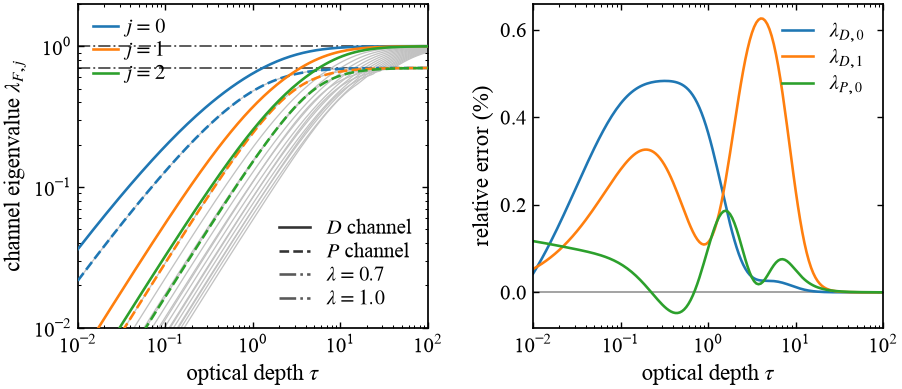

In [28]:
# Direct leading spectrum of the complete Stokes recursion matrix, together
# with mode-resolved D/P channels and an audit of three simple channel fits.
from matplotlib.lines import Line2D
from scipy.sparse.linalg import LinearOperator, eigsh

DP_TAUS = np.geomspace(0.01, 100.0, 161)
DP_MODE_ORDERS = np.arange(5)
DP_HIGHLIGHTED_MODE_ORDERS = np.arange(3)
DIRECT_STOKES_EIGENVALUE_COUNT = 19
DP_N_CELLS = 4096
DP_EIG_TOL = 1.0e-12
DP_EIG_MAXITER = 5000

DP_W = np.array([[1.0, 1.0 / 3.0], [1.0 / 3.0, 1.0]])
_dp_w_eigenvalues, _dp_w_eigenvectors = np.linalg.eigh(DP_W)
DP_W_SQRT = (_dp_w_eigenvectors * np.sqrt(_dp_w_eigenvalues)) @ _dp_w_eigenvectors.T
DP_W_INV_SQRT = (
    _dp_w_eigenvectors * (1.0 / np.sqrt(_dp_w_eigenvalues))
) @ _dp_w_eigenvectors.T


def apply_symmetric_kernel_fft(kernel_fft, vector):
    """Apply one cell-integrated symmetric Toeplitz depth kernel."""
    vector = np.asarray(vector, dtype=float)
    n_cells = vector.size
    padded = np.zeros(2 * n_cells)
    padded[:n_cells] = vector
    return np.fft.irfft(
        kernel_fft * np.fft.rfft(padded), n=2 * n_cells
    )[:n_cells]


def mode_resolved_dp_eigenvalues(tau, n_cells=DP_N_CELLS):
    """Return numerical lambda_D,j and lambda_P,j for the requested modes.

    The depth profiles are the leading K_1 modes.  Each profile is
    projected through K_1, K_3, and K_5; the resulting 2x2 Stokes matrix
    is diagonalized in the exact W-weighted inner product.
    """
    grid = SlabGrid(tau=float(tau), n_cells=int(n_cells))
    kernel_ffts = {
        m: symmetric_toeplitz_fft(cell_integrated_kernel(grid, m))
        for m in (1, 3, 5)
    }

    k1_operator = LinearOperator(
        (grid.n_cells, grid.n_cells),
        matvec=lambda vector: apply_symmetric_kernel_fft(kernel_ffts[1], vector),
        dtype=float,
    )
    x = (np.arange(grid.n_cells) + 0.5) / grid.n_cells
    initial_vector = np.cos(0.37 * np.pi * x) + 0.2 * np.sin(1.73 * np.pi * x)
    depth_eigenvalues, depth_eigenvectors = eigsh(
        k1_operator, k=2 * DP_MODE_ORDERS.size, which="LA", ncv=40,
        v0=initial_vector, tol=DP_EIG_TOL, maxiter=DP_EIG_MAXITER,
    )
    descending = np.argsort(depth_eigenvalues)[::-1]
    depth_eigenvalues = depth_eigenvalues[descending]
    depth_eigenvectors = depth_eigenvectors[:, descending]
    parity_overlaps = np.array([
        depth_eigenvectors[:, index] @ depth_eigenvectors[::-1, index]
        for index in range(depth_eigenvectors.shape[1])
    ])

    lambda_d = np.empty(DP_MODE_ORDERS.size)
    lambda_p = np.empty(DP_MODE_ORDERS.size)
    maximum_depth_residual = 0.0
    maximum_w_symmetry_defect = 0.0

    for j in DP_MODE_ORDERS:
        parity = 1.0 if j % 2 == 0 else -1.0
        candidates = np.flatnonzero(parity * parity_overlaps > 0.0)
        mode_rank_within_parity = j // 2
        if candidates.size <= mode_rank_within_parity:
            raise RuntimeError(f"could not identify depth mode j={j} at tau={tau:g}")

        mode = depth_eigenvectors[:, candidates[mode_rank_within_parity]]
        mode = mode + parity * mode[::-1]
        mode /= np.linalg.norm(mode)

        k1_mode = apply_symmetric_kernel_fft(kernel_ffts[1], mode)
        rho = mode @ k1_mode
        depth_residual = np.linalg.norm(k1_mode - rho * mode) / abs(rho)
        maximum_depth_residual = max(maximum_depth_residual, depth_residual)

        kappa_1 = rho
        kappa_3 = mode @ apply_symmetric_kernel_fft(kernel_ffts[3], mode)
        kappa_5 = mode @ apply_symmetric_kernel_fft(kernel_ffts[5], mode)
        projected_matrix = (3.0 / 16.0) * np.array([
            [
                3.0 * kappa_1 - kappa_3,
                -kappa_1 + 5.0 * kappa_3 - 2.0 * kappa_5,
            ],
            [
                -kappa_1 + 3.0 * kappa_3,
                3.0 * kappa_1 - 7.0 * kappa_3 + 6.0 * kappa_5,
            ],
        ])
        symmetric_matrix = DP_W_SQRT @ projected_matrix @ DP_W_INV_SQRT
        maximum_w_symmetry_defect = max(
            maximum_w_symmetry_defect,
            np.max(np.abs(symmetric_matrix - symmetric_matrix.T)),
        )
        symmetric_matrix = 0.5 * (symmetric_matrix + symmetric_matrix.T)
        channel_eigenvalues = np.linalg.eigvalsh(symmetric_matrix)[::-1]
        lambda_d[j], lambda_p[j] = channel_eigenvalues

    return lambda_d, lambda_p, maximum_depth_residual, maximum_w_symmetry_defect


def mode_resolved_dp_curves(taus, n_cells=DP_N_CELLS):
    taus = np.asarray(taus, dtype=float)
    lambda_d = np.empty((DP_MODE_ORDERS.size, taus.size))
    lambda_p = np.empty((DP_MODE_ORDERS.size, taus.size))
    depth_residuals = np.empty(taus.size)
    w_symmetry_defects = np.empty(taus.size)
    for tau_index, tau in enumerate(taus):
        (
            lambda_d[:, tau_index], lambda_p[:, tau_index],
            depth_residuals[tau_index], w_symmetry_defects[tau_index],
        ) = mode_resolved_dp_eigenvalues(tau, n_cells=n_cells)
    return lambda_d, lambda_p, depth_residuals, w_symmetry_defects

mode_resolved_dp_curves = cached_transport(mode_resolved_dp_curves)


(
    lambda_D_numeric, lambda_P_numeric,
    dp_depth_residuals, dp_w_symmetry_defects,
) = mode_resolved_dp_curves(DP_TAUS)

def direct_stokes_eigenvalues(
    tau, n_eigenvalues=DIRECT_STOKES_EIGENVALUE_COUNT, n_cells=DP_N_CELLS,
):
    """Leading eigenvalues of the complete discretized Stokes recursion matrix.

    The full 2N-dimensional recursion operator is transformed with the exact
    component-space W metric, so the similar operator supplied to eigsh is
    symmetric. No D/P projection or channel classification is imposed.
    """
    grid = SlabGrid(tau=float(tau), n_cells=int(n_cells))
    recursion_operator = FFTTwoComponentOperator.build(grid, "polarized")

    def matvec(transformed_state):
        transformed_state = np.asarray(transformed_state, dtype=float).reshape(2, n_cells)
        physical_state = DP_W_INV_SQRT @ transformed_state
        next_a, next_b = recursion_operator.step(
            physical_state[0], physical_state[1]
        )
        next_state = np.vstack([next_a, next_b])
        return (DP_W_SQRT @ next_state).ravel()

    symmetric_operator = LinearOperator(
        (2 * n_cells, 2 * n_cells), matvec=matvec, dtype=float
    )
    x = (np.arange(n_cells) + 0.5) / n_cells
    initial_a = 1.0 + 0.17 * np.cos(1.31 * np.pi * x)
    initial_b = 0.23 * np.sin(1.77 * np.pi * x)
    eigenvalues = eigsh(
        symmetric_operator, k=n_eigenvalues, which="LA",
        ncv=max(2 * n_eigenvalues + 1, 50),
        v0=np.concatenate([initial_a, initial_b]),
        tol=DP_EIG_TOL, maxiter=DP_EIG_MAXITER,
        return_eigenvectors=False,
    )
    return np.sort(eigenvalues)[::-1]

direct_stokes_eigenvalues = cached_transport(direct_stokes_eigenvalues)


direct_stokes_spectrum = np.column_stack([
    direct_stokes_eigenvalues(tau) for tau in DP_TAUS
])
print(
    f"Computed the leading {DIRECT_STOKES_EIGENVALUE_COUNT} eigenvalues of the "
    f"full Stokes recursion matrix at {DP_TAUS.size} optical depths."
)

# Independent grid-refinement audit at representative optical depths.
DP_AUDIT_TAUS = np.array([0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0])
audit_fine_d, audit_fine_p, _, _ = mode_resolved_dp_curves(
    DP_AUDIT_TAUS, n_cells=DP_N_CELLS
)
audit_coarse_d, audit_coarse_p, _, _ = mode_resolved_dp_curves(
    DP_AUDIT_TAUS, n_cells=DP_N_CELLS // 2
)
audit_fine = np.concatenate([audit_fine_d.ravel(), audit_fine_p.ravel()])
audit_coarse = np.concatenate([audit_coarse_d.ravel(), audit_coarse_p.ravel()])
dp_grid_relative_change = np.max(np.abs(audit_fine - audit_coarse) / np.abs(audit_fine))
print(
    f"Computed numerical D/P curves with N={DP_N_CELLS}; "
    f"max K1 residual={np.max(dp_depth_residuals):.2e}, "
    f"max W-symmetry defect={np.max(dp_w_symmetry_defects):.2e}, "
    f"N={DP_N_CELLS // 2}->{DP_N_CELLS} grid change={dp_grid_relative_change:.2e}."
)


def lambda_D1_approximation(tau):
    """T94-like two-sided interpolation for lambda_D,1."""
    tau = np.asarray(tau, dtype=float)
    z0 = 0.7121
    s1 = (3.0 / 4.0) * 0.7830025
    thin_lambda = -np.expm1(-s1 * tau)
    thin_beta = -np.log(thin_lambda)
    k2 = 2.0 * np.pi / (tau + 2.0 * z0)
    bulk_lambda_D, _ = bulk_channel_eigenvalues(k2)
    bulk_beta_D = -np.log(bulk_lambda_D)
    beta_fit = thin_beta + bulk_beta_D * (-np.expm1(-tau / 3.0))
    return np.exp(-beta_fit)


def lambda_P0_approximation(tau):
    """T94-like two-sided interpolation for lambda_P,0."""
    tau = np.asarray(tau, dtype=float)
    z0 = 0.7121
    thin_action = (3.0 * tau / 8.0) * (
        np.log1p(1.0 / tau) + 7.0 / 4.0 - np.euler_gamma
    )
    thin_lambda = 0.7 * (-np.expm1(-(10.0 / 7.0) * thin_action))
    thin_beta = -np.log(thin_lambda)
    k1 = np.pi / (tau + 2.0 * z0)
    _, bulk_lambda_P = bulk_channel_eigenvalues(k1)
    bulk_beta_P = -np.log(bulk_lambda_P)
    bulk_switch = -np.expm1(-(5.0 * tau / 7.0) ** (7.0 / 6.0))
    thin_switch = np.exp(-(2.0 * tau / 3.0) ** (9.0 / 8.0))
    beta_fit = bulk_beta_P * bulk_switch + thin_beta * thin_switch
    return np.exp(-beta_fit)


simple_channel_tests = {
    r"$\lambda_{D,0}$": (lambda_D0_approximation(DP_TAUS), lambda_D_numeric[0]),
    r"$\lambda_{D,1}$": (lambda_D1_approximation(DP_TAUS), lambda_D_numeric[1]),
    r"$\lambda_{P,0}$": (lambda_P0_approximation(DP_TAUS), lambda_P_numeric[0]),
}
simple_channel_relative_errors = {
    label: fitted / numerical - 1.0
    for label, (fitted, numerical) in simple_channel_tests.items()
}
CHANNEL_FIT_RANGE = (0.01, 100.0)
channel_fit_mask = (
    (DP_TAUS >= CHANNEL_FIT_RANGE[0]) & (DP_TAUS <= CHANNEL_FIT_RANGE[1])
)
for label, relative_error in simple_channel_relative_errors.items():
    restricted_error = relative_error[channel_fit_mask]
    print(
        f"{label}: max |relative error| on "
        f"{CHANNEL_FIT_RANGE[0]:g} <= tau <= {CHANNEL_FIT_RANGE[1]:g} = "
        f"{np.max(np.abs(restricted_error)):.3%}; "
        f"RMS = {np.sqrt(np.mean(restricted_error**2)):.3%}"
    )

if plt is None:
    print("Matplotlib is not installed; D/P eigenvalue data were computed without plotting.")
else:
    fig, (ax, ax_error) = plt.subplots(
        1, 2, figsize=get_double_column_size(row_height_scale=1.08), sharex=True
    )
    ax.axhline(
        0.7, color="0.35", linestyle="-.", linewidth=1.1, zorder=0,
    )
    ax.axhline(
        1.0, color="0.35", linestyle="-.", linewidth=1.1, zorder=0,
    )
    for eigenvalue_index in range(DIRECT_STOKES_EIGENVALUE_COUNT):
        ax.plot(
            DP_TAUS, direct_stokes_spectrum[eigenvalue_index],
            color="0.76", linewidth=0.75, zorder=1,
        )

    for j in DP_HIGHLIGHTED_MODE_ORDERS:
        ax.plot(
            DP_TAUS, lambda_D_numeric[j], color=f"C{j}", linestyle="-", zorder=3
        )
        ax.plot(
            DP_TAUS, lambda_P_numeric[j], color=f"C{j}", linestyle="--", zorder=3
        )

    order_legend = ax.legend(
        handles=[
            Line2D([], [], color=f"C{j}", label=rf"$j={j}$")
            for j in DP_HIGHLIGHTED_MODE_ORDERS
        ],
        loc="upper left", bbox_to_anchor=(0.02, 0.98), ncol=1, frameon=False,
        handlelength=1.2, handletextpad=0.4, labelspacing=0.15, borderaxespad=0.0,
    )
    ax.add_artist(order_legend)
    ax.legend(
        handles=[
            Line2D([], [], color="0.2", linestyle="-", label=r"$D$ channel"),
            Line2D([], [], color="0.2", linestyle="--", label=r"$P$ channel"),
            Line2D([], [], color="0.35", linestyle="-.", label=r"$\lambda=0.7$"),
            Line2D([], [], color="0.35", linestyle="-.", label=r"$\lambda=1.0$"),
        ],
        loc="lower right", bbox_to_anchor=(0.98, 0.03), frameon=False,
        handlelength=1.5, labelspacing=0.2, borderaxespad=0.0,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(DP_TAUS[0], DP_TAUS[-1])
    ax.set_ylim(1e-2, 2.0)
    ax.set_xlabel(r"optical depth $\tau$")
    ax.set_ylabel(r"channel eigenvalue $\lambda_{F,j}$")
    ax_error.axhline(0.0, color="0.55", linewidth=0.9, zorder=0)
    for color_index, (label, relative_error) in enumerate(
        simple_channel_relative_errors.items()
    ):
        ax_error.plot(
            DP_TAUS[channel_fit_mask],
            100.0 * relative_error[channel_fit_mask],
            color=f"C{color_index}", label=label,
        )
    ax_error.set_xscale("log")
    ax_error.set_xlim(*CHANNEL_FIT_RANGE)
    ax_error.set_xlabel(r"optical depth $\tau$")
    ax_error.set_ylabel("relative error (%)")
    ax_error.legend(
        loc="best", frameon=False, handlelength=1.5, labelspacing=0.25
    )
    fig.subplots_adjust(
        left=0.09, right=0.985, bottom=0.17, top=0.97, wspace=0.30
    )
    fig.savefig(FIGURE_DIR / "mode_resolved_channel_eigenvalues.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()


### 12.3. Direct full-matrix spectrum and three projected channels

We compute the leading 39 eigenvalues of the complete discretized Stokes
recursion operator at 161 optical depths, $0.01\leq\tau\leq100$, with 4096
depth cells. We use the symmetric similarity transform and eigensolver
defined in Section 12.2, without imposing a D/P classification on these
full-matrix eigenvalues. We show them as gray scatter points.

We overlay our numerical projected-channel values $\lambda_{D,0}$, $\lambda_{D,1}$ and
$\lambda_{P,0}$ as colored dashed curves. We use `lambda_D_numeric[0]`, `lambda_D_numeric[1]` and
`lambda_P_numeric[0]`, not their analytic fits. We retain the distinction
between these projected channels and the sorted full-operator eigenvalues;
we do not infer exact mode tracking from their visual proximity.

We read the bundled direct-spectrum caches by default. We only recompute
missing eigenvalues when `ALLOW_EXPENSIVE_RECOMPUTE` is explicitly enabled.
We display this supporting figure without exporting an additional file.


Maximum absolute difference from the cached leading-19 solve: 5.773e-15


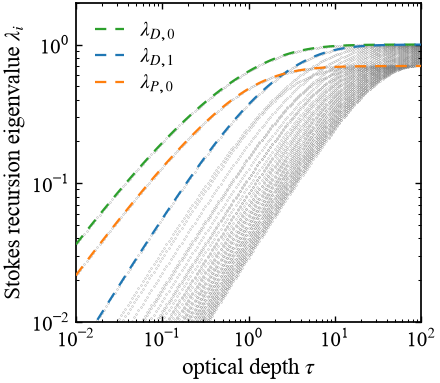

In [29]:
from plot_style import get_single_column_size

DIRECT_STOKES_SCATTER_EIGENVALUE_COUNT = 39
direct_stokes_scatter_columns = []
for tau_index, tau in enumerate(DP_TAUS):
    direct_stokes_scatter_columns.append(direct_stokes_eigenvalues(
        tau, n_eigenvalues=DIRECT_STOKES_SCATTER_EIGENVALUE_COUNT
    ))
    if ALLOW_EXPENSIVE_RECOMPUTE and (tau_index + 1) % 20 == 0:
        print(f"Direct 39-eigenvalue spectrum: {tau_index + 1}/{len(DP_TAUS)} depths ready.", flush=True)
direct_stokes_scatter_spectrum = np.column_stack(direct_stokes_scatter_columns)
assert direct_stokes_scatter_spectrum.shape == (39, len(DP_TAUS))
assert np.isfinite(direct_stokes_scatter_spectrum).all()
assert (direct_stokes_scatter_spectrum > 0).all()
assert (np.diff(direct_stokes_scatter_spectrum, axis=0) <= 0).all()
# Independent eigensolver requests must reproduce the shared leading spectrum.
direct39_leading_difference = np.max(np.abs(
    direct_stokes_scatter_spectrum[:DIRECT_STOKES_EIGENVALUE_COUNT]
    - direct_stokes_spectrum
))
print(f"Maximum absolute difference from the cached leading-19 solve: {direct39_leading_difference:.3e}")
assert direct39_leading_difference < 1e-9

fig, ax = plt.subplots(figsize=get_single_column_size(row_height_scale=1.05))
for eigenvalue_index in range(DIRECT_STOKES_SCATTER_EIGENVALUE_COUNT):
    ax.scatter(DP_TAUS, direct_stokes_scatter_spectrum[eigenvalue_index],
               color="0.5", s=0.03, zorder=1)
ax.plot(DP_TAUS, lambda_D_numeric[0], color="C2", ls=(0, (5, 4)), lw=1.3,
        label=r"$\lambda_{D,0}$", zorder=3)
ax.plot(DP_TAUS, lambda_D_numeric[1], color="C0", ls=(0, (5, 4)), lw=1.3,
        label=r"$\lambda_{D,1}$", zorder=3)
ax.plot(DP_TAUS, lambda_P_numeric[0], color="C1", ls=(0, (5, 4)), lw=1.3,
        label=r"$\lambda_{P,0}$", zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(DP_TAUS[0], DP_TAUS[-1])
ax.set_ylim(1.0e-2, 2.0)
ax.set_xlabel(r"optical depth $\tau$")
ax.set_ylabel(r"Stokes recursion eigenvalue $\lambda_i$")
ax.legend(loc="upper left", frameon=False, handlelength=1.4, labelspacing=0.25)
fig.subplots_adjust(left=0.19, right=0.98, bottom=0.17, top=0.98)
plt.show()


### 12.4. Avoided crossings involving the lowest polarization channel

We resolve the first four avoided crossings involving $P_0$ by solving the
**full Stokes recursion operator**, rather than diagonalizing independent
projected $2\times2$ channel matrices. We use projected channels only to
identify the character of the eigenvectors near each encounter.

#### 12.4.1. Reflection symmetry and mode identification

The depth-reflection operation $t\mapsto\tau-t$ commutes with the transport
operator. The $j$-th scalar depth mode has parity $(-1)^j$. Thus $P_0$ can
mix with $D_2,D_4,\ldots$, whereas its encounters with odd $D$ modes are
symmetry-allowed exact crossings, not avoided crossings.

We use the metric

$$W=\begin{pmatrix}1&1/3\\1/3&1\end{pmatrix},\qquad
S=W^{1/2}\mathbb K_{\rm pol}W^{-1/2}.$$

The even-sector restriction of this symmetric operator is an exact symmetry
reduction: it retains coupling between all even depth modes. For an $N$-cell
slab, the full operator has dimension $2N$, and its even block has dimension $N$.
We identify the relevant neighboring eigenpair using its squared overlaps with
the $W$-normalized projected $P_0$ and $D_j$ states. We also check that their
character is exchanged across the encounter. Close to resonance, individual
full-matrix eigenvectors are mixtures, so we label the pair by its asymptotic
channel character rather than assigning an exact D/P identity at every depth.

#### 12.4.2. Gap definition and convergence

For each encounter we minimize the **absolute** separation of the same adjacent
even-sector eigenvalues over a local optical-depth interval:

$$\tau_\ast=\mathop{\rm arg\,min}_{\tau}\,[\lambda_+(\tau)-\lambda_-(\tau)],
\qquad \Delta\lambda_\ast=\lambda_+(\tau_\ast)-\lambda_-(\tau_\ast).$$

We then quote the relative full splitting, not the half splitting,

$$g_\ast=\frac{2\Delta\lambda_\ast}{\lambda_+(\tau_\ast)+\lambda_-(\tau_\ast)}.$$

We repeat the minimization at $N=1024,2048,4096,8192$. The first four gaps are
approximately $1.1757\%$, $0.4027\%$, $0.2031\%$ and $0.1224\%$, respectively.
Thus the largest of these is about **1.2%**, at the $P_0$–$D_2$ encounter.
This finite set of checks is not a proof of an upper bound over infinitely many
encounters. The table reports the minimization result, the change between the
two finest grids, and the eigensolver residual.

We load bundled numerical results by default. The following cell includes the
full calculation; setting `RECOMPUTE_AVOIDED_CROSSINGS = True` and enabling
`ALLOW_EXPENSIVE_RECOMPUTE` reruns it. No MCRT or spectral fit is involved.
The supporting figure is displayed only. Solid curves are full-matrix
eigenvalues; dashed/dotted curves are the projected-channel diagnostics, and
the black segment marks the minimum gap.


Full-matrix even-sector gaps: relative gap = full splitting / pair mean
pair       tau_min      absolute gap    relative gap    grid change       residual
P0-D2      5.053556    0.007849517    1.175700%      1.44e-06      7.71e-16
P0-D4      9.660975    0.002773826    0.402700%      4.64e-06      5.66e-16
P0-D6     14.141087    0.001409900    0.203064%      9.39e-06      8.90e-16
P0-D8     18.576596    0.000852294    0.122358%      1.56e-05      9.40e-16
Grid change is the relative change of the gap, not a rigorous error bound.


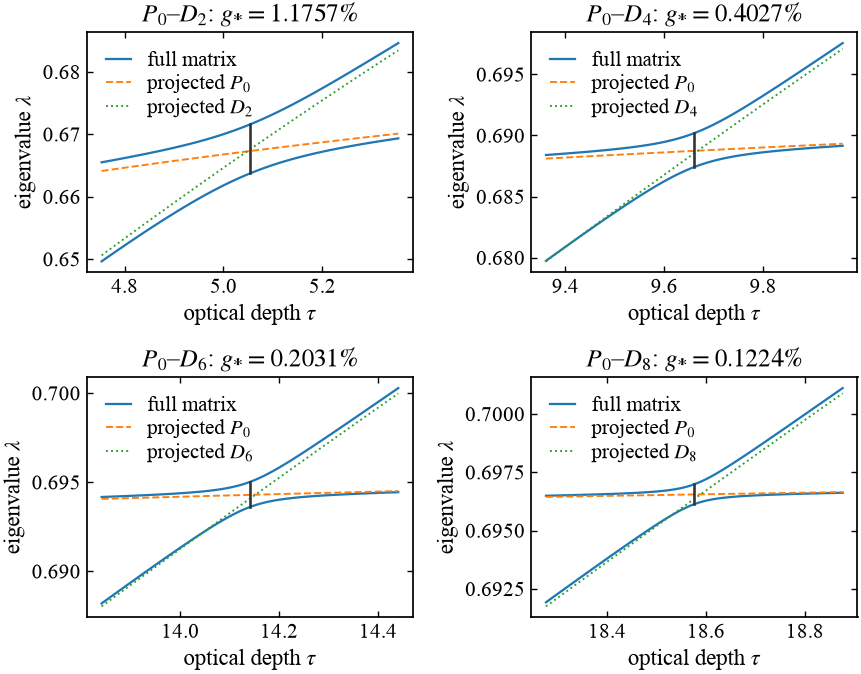

In [30]:
def compute_avoided_crossings():
    from functools import lru_cache
    from scipy.sparse.linalg import LinearOperator, eigsh
    from scipy.optimize import brentq, minimize_scalar
    W=np.array([[1.,1/3],[1/3,1.]])
    wv,wu=np.linalg.eigh(W)
    WS=(wu*np.sqrt(wv))@wu.T
    WI=(wu/np.sqrt(wv))@wu.T
    
    def expand(v,n,parity):
        v=np.asarray(v).reshape(-1,n//2)
        return np.concatenate((v,parity*v[:,::-1]),axis=1)/np.sqrt(2)
    
    def restrict(v,n):
        return (np.asarray(v).reshape(-1,n)[:,:n//2]*np.sqrt(2)).ravel()
    
    def full_operator(tau,n,parity=1):
        grid=SlabGrid(tau=float(tau),n_cells=n)
        op=FFTTwoComponentOperator.build(grid,'polarized')
        def mv(v):
            state=WI@expand(v,n,parity)
            a,b=op.step(*state)
            return restrict(WS@np.stack((a,b)),n)
        return LinearOperator((n,n),matvec=mv,dtype=float)
    
    def scalar_action(kernel,v):
        n=len(v)
        pad=np.zeros(2*n);pad[:n]=v
        return np.fft.irfft(kernel*np.fft.rfft(pad),n=2*n)[:n]
    
    @lru_cache(maxsize=512)
    def projected(tau,n,jmax):
        grid=SlabGrid(tau=float(tau),n_cells=n)
        kernels={m:symmetric_toeplitz_fft(cell_integrated_kernel(grid,m)) for m in (1,3,5)}
        half=n//2
        def mv(v):
            return restrict(scalar_action(kernels[1],expand(v,n,1)[0]),n)
        op=LinearOperator((half,half),matvec=mv,dtype=float)
        x=(np.arange(half)+.5)/half
        val,vec=eigsh(op,k=jmax//2+1,which='LA',tol=3e-12,ncv=max(30,2*(jmax//2+1)+1),
                     v0=1+.17*np.cos(1.31*np.pi*x))
        vec=vec[:,np.argsort(val)[::-1]]
        result={}
        for rank in range(jmax//2+1):
            depth=expand(vec[:,rank],n,1)[0]
            l1,l3,l5=[depth@scalar_action(kernels[m],depth) for m in (1,3,5)]
            M=3/16*np.array([[3*l1-l3,-l1+5*l3-2*l5],[-l1+3*l3,3*l1-7*l3+6*l5]])
            S=WS@M@WI
            values,vectors=np.linalg.eigh((S+S.T)/2)
            for channel,col in (('D',1),('P',0)):
                target=(vectors[:,col,None]*vec[:,rank][None,:]).ravel()
                result[channel,2*rank]=(float(values[col]),target)
        return result
    
    @lru_cache(maxsize=512)
    def solve(tau,n,count,parity=1):
        op=full_operator(tau,n,parity)
        x=(np.arange(n//2)+.5)/(n//2)
        start=np.r_[1+.17*np.cos(1.31*np.pi*x),.23*np.sin(1.77*np.pi*x)]
        values,vectors=eigsh(op,k=count,which='LA',ncv=max(40,2*count+1),tol=2e-12,v0=start,maxiter=5000)
        idx=np.argsort(values)[::-1]
        values,vectors=values[idx],vectors[:,idx]
        return values,vectors
    
    def pair_info(tau,n,j,rank=None):
        p=projected(float(tau),n,j)
        values,vectors=solve(float(tau),n,j//2+6)
        overlaps=np.array([(vectors.T@p[key][1])**2 for key in (('P',0),('D',j))])
        if rank is None:
            pair=np.sort(np.argsort(overlaps.sum(axis=0))[-2:])
            assert pair[1]==pair[0]+1,(tau,j,pair)
            rank=int(pair[0])
        pair=np.array([rank,rank+1])
        upper,lower=values[pair]
        op=full_operator(tau,n)
        residuals=[float(np.linalg.norm(op@vectors[:,i]-values[i]*vectors[:,i])) for i in pair]
        return dict(tau=float(tau),n=n,j=j,pair_ranks=pair.tolist(),upper=float(upper),lower=float(lower),
                    gap=float(upper-lower),relative_gap=float(2*(upper-lower)/(upper+lower)),
                    overlap=overlaps[:,pair].tolist(),captured_weight=overlaps[:,pair].sum(axis=1).tolist(),
                    projected_P0=p['P',0][0],projected_Dj=p['D',j][0],residuals=residuals)

    result = {'convergence': [], 'curves': []}
    for j in (2,4,6,8):
        root = brentq(lambda t: projected(float(t),1024,j)['D',j][0]
                      -projected(float(t),1024,j)['P',0][0], .2,100,xtol=1e-8)
        rank = pair_info(root,1024,j)['pair_ranks'][0]
        for n in (1024,2048,4096,8192):
            def objective(t):
                values = solve(float(t),n,j//2+6)[0]
                return float(values[rank]-values[rank+1])
            optimum = minimize_scalar(objective,bounds=(.8*root,1.2*root),
                                      method='bounded',options={'xatol':1e-8})
            if not optimum.success:
                raise RuntimeError('Gap minimization failed')
            entry = pair_info(float(optimum.x),n,j,rank)
            result['convergence'].append(entry)
        center = result['convergence'][-1]['tau']
        ts = np.linspace(center-.3,center+.3,91)
        full = np.array([solve(float(t),4096,j//2+6)[0][rank:rank+2] for t in ts])
        proj = np.array([[projected(float(t),4096,j)[key][0]
                          for key in [('P',0),('D',j)]] for t in ts])
        flanks = [pair_info(center+d,4096,j,rank) for d in (-.3,.3)]
        result['curves'].append(dict(j=j,tau=ts.tolist(),full=full.tolist(),
                                     projected=proj.tolist(),flanks=flanks))
    return result

RECOMPUTE_AVOIDED_CROSSINGS = False
avoided_cache_path = PUBLIC_ROOT / 'data/avoided_crossings/full_matrix_gaps.json'
if RECOMPUTE_AVOIDED_CROSSINGS:
    if not ALLOW_EXPENSIVE_RECOMPUTE:
        raise RuntimeError('Enable ALLOW_EXPENSIVE_RECOMPUTE before recomputing the gap scan')
    avoided_results = compute_avoided_crossings()
else:
    if not avoided_cache_path.is_file():
        raise FileNotFoundError('Missing bundled avoided-crossing calculation')
    avoided_results = json.loads(avoided_cache_path.read_text())

print('Full-matrix even-sector gaps: relative gap = full splitting / pair mean')
print('pair       tau_min      absolute gap    relative gap    grid change       residual')
avoided_finest = []
for j in (2,4,6,8):
    levels = {r['n']:r for r in avoided_results['convergence'] if r['j']==j}
    assert set(levels)=={1024,2048,4096,8192}
    fine,previous=levels[8192],levels[4096]
    change=abs(fine['relative_gap']/previous['relative_gap']-1)
    residual=max(fine['residuals'])
    np.testing.assert_allclose(fine['relative_gap'],2*fine['gap']/(fine['upper']+fine['lower']))
    assert fine['gap']>0 and change<2e-5 and residual<1e-10
    assert min(fine['captured_weight'])>.99
    avoided_finest.append(fine)
    print(f"P0-D{j:<2} {fine['tau']:12.6f}  {fine['gap']:13.9f}  "
          f"{100*fine['relative_gap']:10.6f}%  {change:12.2e}  {residual:12.2e}")
print('Grid change is the relative change of the gap, not a rigorous error bound.')

fig,axes=plt.subplots(2,2,figsize=get_double_column_size(row_height_scale=1.9))
for ax,curve,fine in zip(axes.flat,avoided_results['curves'],avoided_finest):
    j=curve['j'];ts=np.array(curve['tau'])
    full=np.array(curve['full']);proj=np.array(curve['projected'])
    assert j==fine['j'] and np.all(full[:,0]>full[:,1])
    # The upper full eigenvector changes from predominantly P0 to predominantly Dj.
    assert curve['flanks'][0]['overlap'][0][0]>.8
    assert curve['flanks'][1]['overlap'][0][1]>.8
    ax.plot(ts,full[:,0],color='C0',lw=1.3,label='full matrix')
    ax.plot(ts,full[:,1],color='C0',lw=1.3)
    ax.plot(ts,proj[:,0],color='C1',ls='--',lw=1.1,label=r'projected $P_0$')
    ax.plot(ts,proj[:,1],color='C2',ls=':',lw=1.1,label=rf'projected $D_{j}$')
    ax.plot([fine['tau']]*2,[fine['lower'],fine['upper']],color='.2',lw=1.5)
    ax.set_title(rf'$P_0$–$D_{j}$: $g_{{*}}={100*fine["relative_gap"]:.4f}\%$')
    ax.set_xlabel(r'optical depth $\tau$');ax.set_ylabel(r'eigenvalue $\lambda$')
    ax.ticklabel_format(useOffset=False,axis='both')
    ax.legend(loc='upper left',frameon=False,handlelength=1.2,labelspacing=.2)
fig.tight_layout()
plt.show()


## 13. Energy spectra: cached MCRT, recursion + Jones, and compPSc

Four cases use a 5 eV blackbody with Lambert-law injection. MCRT has 400 million
histories per case. Bin widths, errors and signed Q conventions are retained.
I_E = 2 pi E N_I and Q_E = 2 pi E N_Q: energy densities integrated over azimuth,
per injected photon and per unit direction cosine. Only the upper-surface figure
is exported, as in the manuscript. Iterative compPSc convergence is checked;
full frequency/depth/angular mesh certification remains a separate issue.

### 13.1. Upper-surface spectra


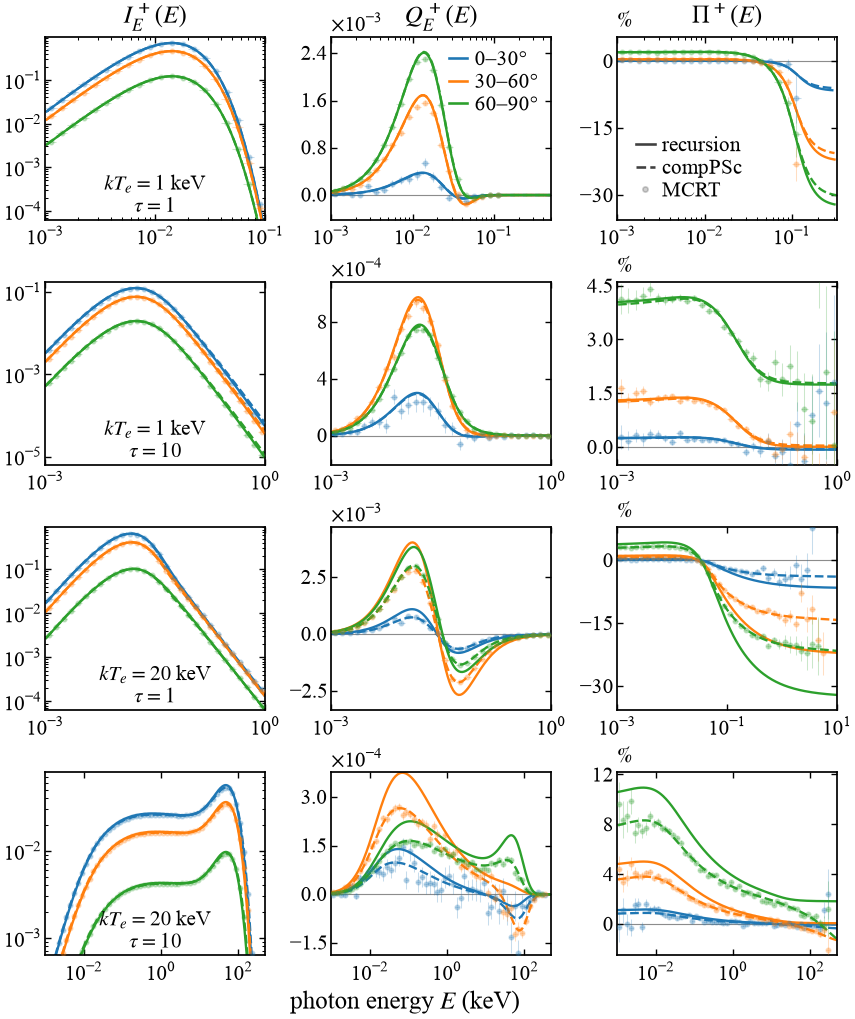

Verified four cached cases; 5 eV blackbody, Lambert-law injection.
compPSc iteration converged; full frequency/depth/angular mesh certification remains pending.


In [31]:
from helpers import spectra as niq_plot
NIQ_AZIMUTH = niq_plot.AZIMUTH_FACTOR  # 2*pi; scale fixed I/Q limits consistently.

# Rows, top to bottom: (kTe in keV, total vertical optical depth).
NIQ_CASES = ((1.0, 1.0), (1.0, 10.0), (20.0, 1.0), (20.0, 10.0))
# Include the seed-spectrum rise and each row-specific high-energy tail.
NIQ_ENERGY_LIMITS = ((0.001, 0.2), (0.001, 12.0),
                     (0.001, 80.0), (0.001, 500.0))
NIQ_FIGURES, NIQ_AUDITS = niq_plot.plot_four_case_niq(
    cases=NIQ_CASES, xlimits=NIQ_ENERGY_LIMITS,
    surfaces=("up",),       # Upper surface shown in the paper.
    intensity_decades=8,           # Fallback only if a row lower limit is None.
    intensity_ymin=tuple(NIQ_AZIMUTH*v for v in (1e-5, 1e-6, 1e-5, 1e-4)),
    q_ymax=(None, None, None, NIQ_AZIMUTH*6e-5),  # Last-row Q_E upper limit.
    q_ymin=(None, None, None, NIQ_AZIMUTH*(-3e-5)),  # Last-row Q_E lower limit.
    q_ylim_by_surface={"down": (None, None, None,
                               (NIQ_AZIMUTH*(-8e-4), NIQ_AZIMUTH*8e-4))},
    q_xmax=(0.5, 1.0, 1.0, None),  # First-row Q_E extended to leave room for the legend.
    intensity_xmax=(0.1, 1.0, 1.0, None),  # I_E energy upper limits (keV).
    pi_xmax=(0.33, 1.0, 10.0, None),  # Pi energy upper limits (keV), both surfaces.
    pi_min_count=100,              # Display only well-sampled MCRT Pi bins.
    pi_signal_floor=1e-12,         # Hide unstable deterministic Q/I in faint tails.
    show=True,                    # Display the cached-spectrum figures.
    save_directory=FIGURE_DIR,  # Save upper/lower PDFs with tight margins.
)
print("Verified four cached cases; 5 eV blackbody, Lambert-law injection.")
print("compPSc iteration converged; full frequency/depth/angular mesh certification remains pending.")


### 13.2. Lower-surface spectra

We show the lower-surface $I_E^-(E)$, $Q_E^-(E)$ and $\Pi^-(E)$ for the same
four parameter pairs and three angular windows as in Section 13.1. We use
the same cached MCRT, recursion + Jones and compPSc results, normalization,
Stokes convention, statistical display cuts and energy-density conversion.
We retain the surface-specific Q limits from the original plotting setup.
We display this supporting figure without exporting an additional PDF or
launching a new calculation.


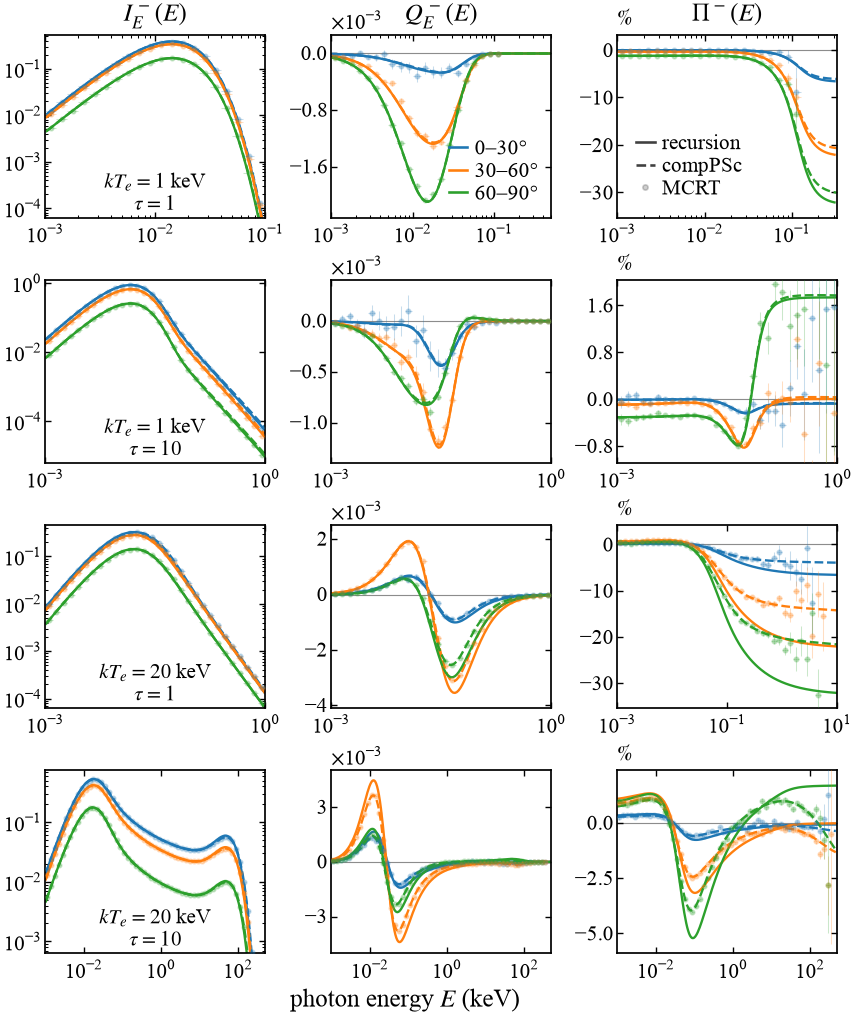

Verified four cached cases; 5 eV blackbody, Lambert-law injection.
compPSc iteration converged; full frequency/depth/angular mesh certification remains pending.


In [32]:
from helpers import spectra as niq_plot
NIQ_AZIMUTH = niq_plot.AZIMUTH_FACTOR  # 2*pi; scale fixed I/Q limits consistently.

# Rows, top to bottom: (kTe in keV, total vertical optical depth).
NIQ_CASES = ((1.0, 1.0), (1.0, 10.0), (20.0, 1.0), (20.0, 10.0))
# Include the seed-spectrum rise and each row-specific high-energy tail.
NIQ_ENERGY_LIMITS = ((0.001, 0.2), (0.001, 12.0),
                     (0.001, 80.0), (0.001, 500.0))
NIQ_LOWER_FIGURES, NIQ_LOWER_AUDITS = niq_plot.plot_four_case_niq(
    cases=NIQ_CASES, xlimits=NIQ_ENERGY_LIMITS,
    surfaces=("down",),     # We display the lower-surface counterpart.
    intensity_decades=8,           # Fallback only if a row lower limit is None.
    intensity_ymin=tuple(NIQ_AZIMUTH*v for v in (1e-5, 1e-6, 1e-5, 1e-4)),
    q_ymax=(None, None, None, NIQ_AZIMUTH*6e-5),  # Last-row Q_E upper limit.
    q_ymin=(None, None, None, NIQ_AZIMUTH*(-3e-5)),  # Last-row Q_E lower limit.
    q_ylim_by_surface={"down": (None, None, None,
                               (NIQ_AZIMUTH*(-8e-4), NIQ_AZIMUTH*8e-4))},
    q_xmax=(0.5, 1.0, 1.0, None),  # First-row Q_E extended to leave room for the legend.
    intensity_xmax=(0.1, 1.0, 1.0, None),  # I_E energy upper limits (keV).
    pi_xmax=(0.33, 1.0, 10.0, None),  # Pi energy upper limits (keV), both surfaces.
    pi_min_count=100,              # Display only well-sampled MCRT Pi bins.
    pi_signal_floor=1e-12,         # Hide unstable deterministic Q/I in faint tails.
    show=True,                    # Display the cached-spectrum figures.
    save_directory=None,  # We display this supporting figure without exporting it.
)
print("Verified four cached cases; 5 eV blackbody, Lambert-law injection.")
print("compPSc iteration converged; full frequency/depth/angular mesh certification remains pending.")


## 14. Validity-domain diagnostic: fixed-parameter chi-square maps

The 9 by 9 grid compares linear I and Q to MCRT, at fixed physical parameters
and absolute normalization. No amplitude is fitted, so degrees of freedom equal
the retained point count. Reference-only masks select numerically supported
energy bins. These are diagonal-covariance diagnostics of model discrepancies
relative to MCRT statistical errors, not a full model-systematics likelihood.
The packaged provenance records masks, energy range and simulation controls.

### 14.1. Upper-surface recursion + Jones versus MCRT


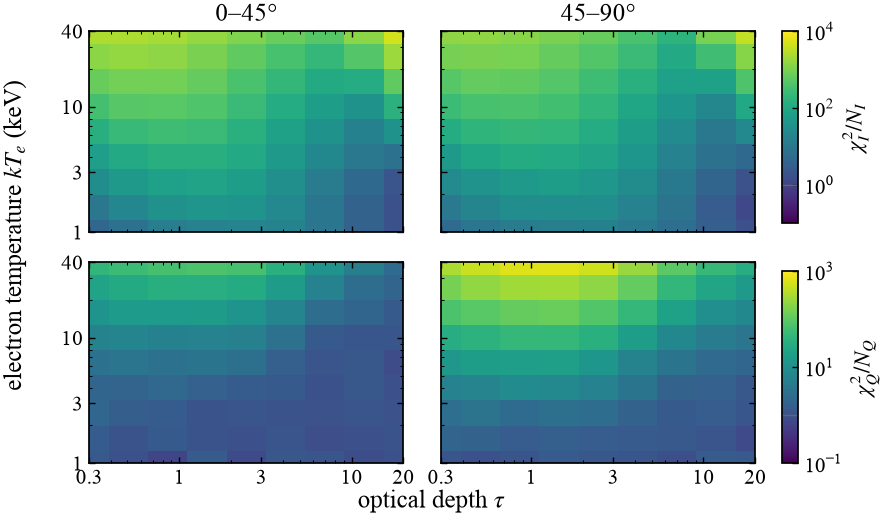

In [33]:
from helpers.statistics import plot_upper_recursion_chi_square
heatmap, statistics, provenance = plot_upper_recursion_chi_square(save_directory=FIGURE_DIR)


### 14.2. Upper-surface compPSc versus MCRT

We display the cached compPSc comparison on the same $9\times9$ parameter grid
and with the same MCRT-selected energy bins as in Section 14.1. We hold all
physical parameters and the absolute normalization fixed and calculate

$$
\frac{\chi_X^2}{N_X}=\frac{1}{N_X}\sum_b
\frac{(X_{{\rm compPSc},b}-X_{{\rm MCRT},b})^2}
{\mathrm{SE}(X_{{\rm MCRT},b})^2},\qquad X=I,Q.
$$

We use linear photon-density spectra and diagonal MCRT variances, with no
fitted amplitude. We show the upper surface only: the columns correspond to
$0^\circ$--$45^\circ$ and $45^\circ$--$90^\circ$, while the rows show I and Q.
We keep exactly the same logarithmic color ranges as in the preceding figure
and omit white cell outlines, allowing a direct visual comparison.

We use the archived base-mesh compPSc results. Iteration convergence does not
establish full frequency/depth/angular mesh convergence; we therefore retain
this numerical limitation when interpreting the map. We display this supporting
figure without saving it, rerunning any solver, or requiring compPSc installation.


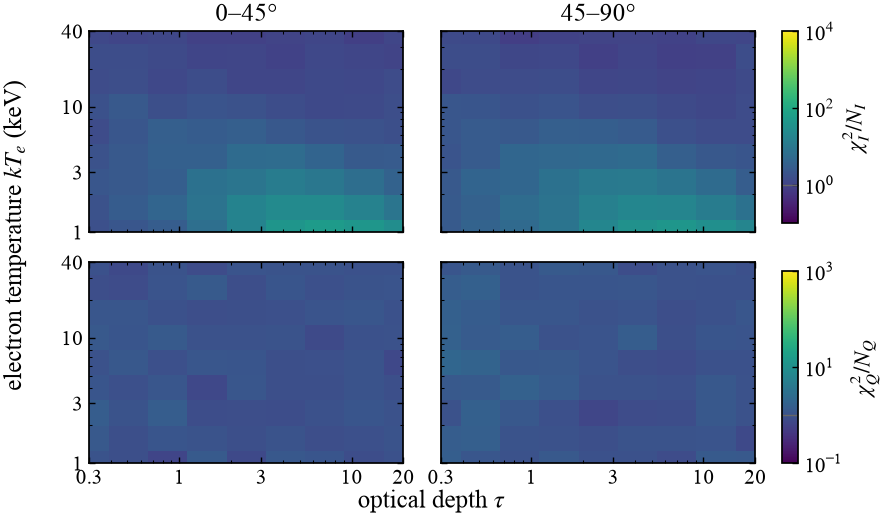

In [34]:
from helpers.statistics import plot_upper_comppsc_chi_square
comppsc_heatmap, comppsc_statistics, comppsc_provenance = plot_upper_comppsc_chi_square()


## 15. 4U 1624-49: low- and high-reflection Western-model fits

This section reproduces the adopted profile-reference fits from numerical exports.
It does not load XSPEC or rerun optimization. I is model-dependent unfolded flux;
Q/U are the combined-DU detector-space display, while fitting used the native
three-DU datasets separately. The data/model residual and chi-square checks are
performed on the exported native data. Profile intervals are not MCMC posteriors;
parameter-boundary limitations are retained in the accompanying interval table.
Local machine paths have been redacted, without changing numerical arrays.


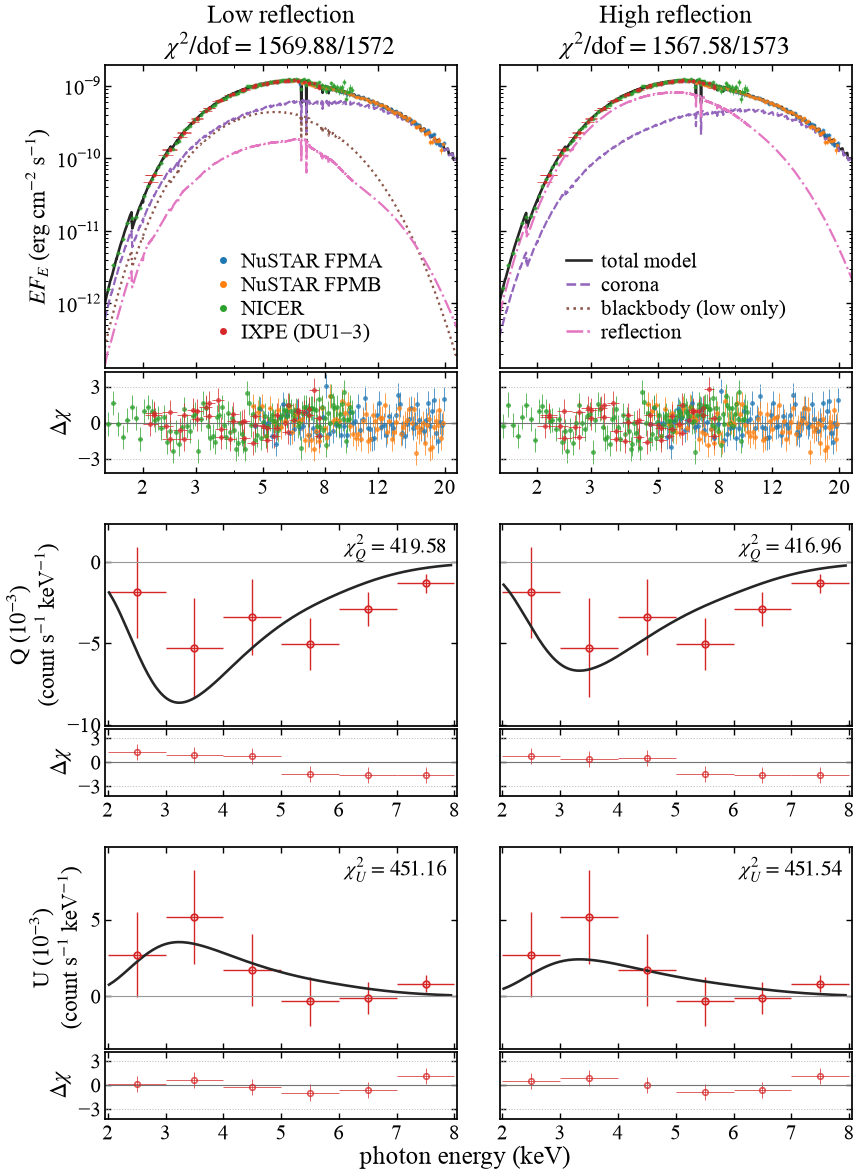

low: chi2/dof=1569.879853/1572; native I/Q/U points={'I': 704, 'Q': 446, 'U': 446}; IXPE I optmin/25 display bins=[15, 15, 15]; standard-v4-20261007.
high: chi2/dof=1567.583843/1573; native I/Q/U points={'I': 704, 'Q': 446, 'U': 446}; IXPE I optmin/25 display bins=[15, 15, 15]; standard-v4-20261007.


In [35]:
from helpers.western import plot_western_iqu_comparison
western_figure, western_results = plot_western_iqu_comparison(save_path=FIGURE_DIR / "western_iqu_low_high_reflection.pdf")


### 15.1. Low-reflection best-fit coronal spectra: MCRT comparison

We compare our recursion + Jones approximation with independent MCRT at
$kT_e=2.64470838\,\mathrm{keV}$ and $\tau=13.09683120$.
We use a multitemperature disk-blackbody seed spectrum with
$kT_{\rm in}=0.6\,\mathrm{keV}$, Lambert-law injection at the lower boundary,
and covering fraction one. We check these parameters against the fit exports
displayed above, without refitting or changing the absolute normalization.

We use 128 independent batches of one million injected photons each. The
cached photon-budget audit records no terminated histories. We display the
bundled statistically supported bins and their batch-based standard errors;
the polarization errors retain the I/Q covariance. Horizontal error bars
show energy-bin extents. We retain the cached signed-Q convention without
applying another sign reversal.

In the first figure, we show I and Q in the left and right columns, and the
upper and lower surfaces in the first and second rows. In the second figure,
we show $\Pi(E)=Q_E/I_E$ for the upper and lower surfaces. We use the three
angular windows $0^\circ$--$30^\circ$, $30^\circ$--$60^\circ$, and
$60^\circ$--$90^\circ$; these are bin-averaged spectra, not evaluations at
the central angle or at the fitted inclination.

Here $I_E$ and $Q_E$ denote **photon-number spectral densities** per injected
photon, per keV, per steradian. We plot $E^2 I_E$ and $E^2 Q_E$, in
keV per injected photon per steradian, and $100\Pi$ in percent. We retain
the original polarization display limits to resolve the model curves;
some noisy tail points may lie outside the displayed range.

We test the intrinsic coronal transport component, not the full absorbed,
reflected, sky-rotated observational model. We retain spatial and kernel
diagnostics in the accompanying cache audit; full energy-grid refinement
is not certified. We only read bundled exports and display these figures:
we do not start simulations or save additional figure files.


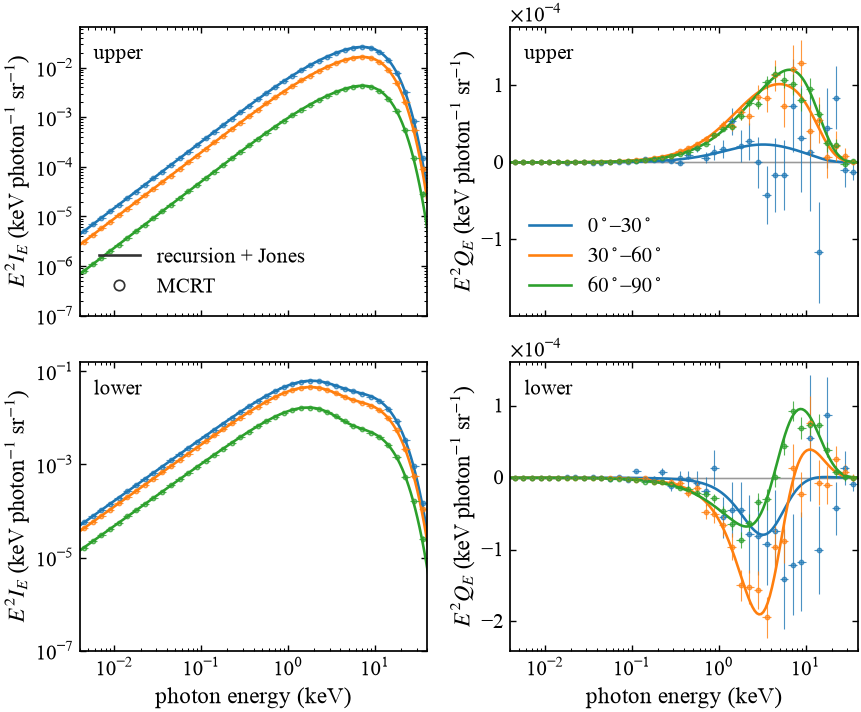

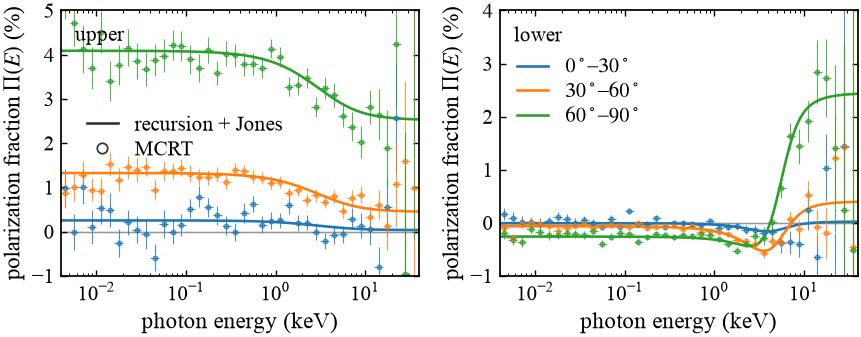

In [36]:
from helpers.bestfit_validation import plot_cached_branch, plot_cached_polarization
bestfit_low_iq = plot_cached_branch("low")
bestfit_low_pi = plot_cached_polarization("low", show=True, save_figures=False)


### 15.2. High-reflection best-fit coronal spectra: MCRT comparison

We compare our recursion + Jones approximation with independent MCRT at
$kT_e=2.65387567\,\mathrm{keV}$ and $\tau=17.38740976$.
We use a multitemperature disk-blackbody seed spectrum with
$kT_{\rm in}=0.6\,\mathrm{keV}$, Lambert-law injection at the lower boundary,
and covering fraction one. We check these parameters against the fit exports
displayed above, without refitting or changing the absolute normalization.

We use 128 independent batches of one million injected photons each. The
cached photon-budget audit records no terminated histories. We display the
bundled statistically supported bins and their batch-based standard errors;
the polarization errors retain the I/Q covariance. Horizontal error bars
show energy-bin extents. We retain the cached signed-Q convention without
applying another sign reversal.

In the first figure, we show I and Q in the left and right columns, and the
upper and lower surfaces in the first and second rows. In the second figure,
we show $\Pi(E)=Q_E/I_E$ for the upper and lower surfaces. We use the three
angular windows $0^\circ$--$30^\circ$, $30^\circ$--$60^\circ$, and
$60^\circ$--$90^\circ$; these are bin-averaged spectra, not evaluations at
the central angle or at the fitted inclination.

Here $I_E$ and $Q_E$ denote **photon-number spectral densities** per injected
photon, per keV, per steradian. We plot $E^2 I_E$ and $E^2 Q_E$, in
keV per injected photon per steradian, and $100\Pi$ in percent. We retain
the original polarization display limits to resolve the model curves;
some noisy tail points may lie outside the displayed range.

We test the intrinsic coronal transport component, not the full absorbed,
reflected, sky-rotated observational model. We retain spatial and kernel
diagnostics in the accompanying cache audit; full energy-grid refinement
is not certified. We only read bundled exports and display these figures:
we do not start simulations or save additional figure files.


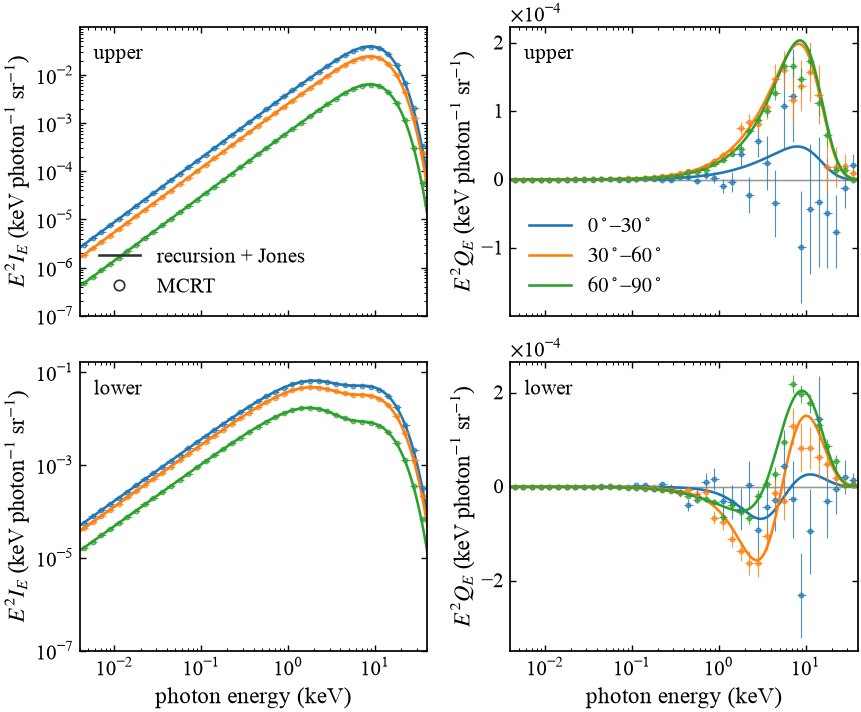

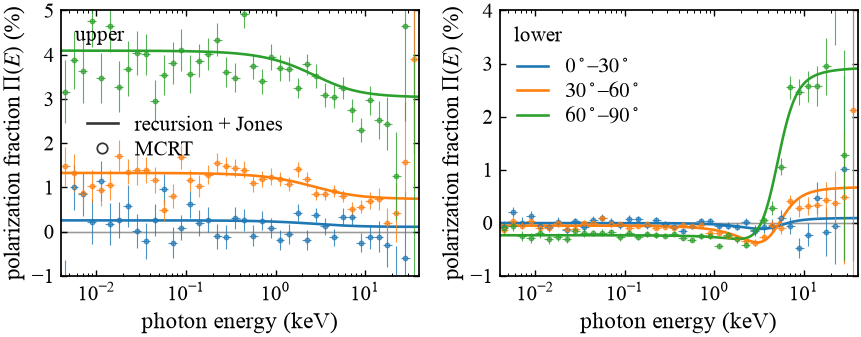

In [37]:
from helpers.bestfit_validation import plot_cached_branch, plot_cached_polarization
bestfit_high_iq = plot_cached_branch("high")
bestfit_high_pi = plot_cached_polarization("high", show=True, save_figures=False)


## 16. Reproducibility and scope

The preceding figures use the same physical parameters and formulas as the
research notebook. Only the manuscript k1 = pi/(tau + 2 z0) approximation is
used for the finite-thickness reconstruction curves. Strict finite-slab numerical
solutions remain their benchmarks. Numerical half-space coefficient extraction
is kept as a separate validation calculation.

The original exploratory baseline, trial redistribution kernels,
MCRT launch cells, and redundant plots are intentionally excluded. They remain
in the preserved research notebook. Raw observational events/responses and private
compPSc code are not bundled. This is a figure-reproduction companion, not a
complete replacement for simulation software or the observational reduction pipeline.


## 17. Supplementary thermal-angular redistribution test

We test whether electron thermal motion in the angular/polarization matrix
improves the spectra at $kT_e=20$ keV. We retain the same scalar Jones energy
redistribution, 5 eV blackbody photon-number seeds, unpolarized Lambert injection,
total Thomson depths $\tau=1,10$, and fixed per-injected-photon normalization.
We compare both surfaces and three finite angular windows with the existing
400-million-history MCRT calculations and compPSc outputs.

This is an additional diagnostic, **not a replacement for the stationary-electron
Thomson model used in the preceding sections**. We load cached results only;
these cells do not run transport, fit amplitudes, launch MCRT or save figures.

### 17.1. Thermal angular matrix and limitations

We average the recoil-free electron-rest-frame Thomson Mueller matrix over an
isotropic Maxwell–Jüttner distribution, using Lorentz-transformed rays and
gauge-corrected polarization vectors. The differential photon-number angular
rate includes the relative collision-flux and aberration factor

\[
\frac{1-\boldsymbol\beta\cdot\boldsymbol n_{\rm in}}
{\gamma^2(1-\boldsymbol\beta\cdot\boldsymbol n_{\rm out})^2}.
\]

We integrate the incident azimuth and retain the full axisymmetric $I,Q$
angular matrix. The original two-function $a,b$ closure no longer applies;
we use discrete ordinates with analytic cell-averaged attenuation instead.
We retain the same convention: positive Q is parallel to the slab surface.

**This is not the full thermal Klein–Nishina redistribution matrix.** The
angular kernel is energy-integrated and recoil-free; Thomson opacity and
energy–angle separability remain. In particular, the scalar Jones kernel does
not restore joint energy–angle–polarization correlations.

The displayed calculations use 2048/4096 depth cells for $\tau=1/10$, 120 signed
angular ordinates, and refined electron/azimuth quadrature. We verify the cold
limit against our original recursion, photon closure (below $10^{-12}$), and
depth/angular refinement. The bundled audits quantify these checks rather than
claiming global convergence over all temperatures.

In [1]:
from helpers.thermal_angular import load_thermal, plot_comparison, metric_rows, DATA as THERMAL_DATA
import json
from IPython.display import display, Markdown
for thermal_tau in [1, 10]:
    load_thermal(thermal_tau)  # Verify hashes; missing data raise an error.
    thermal_audit = json.loads((THERMAL_DATA/f'tau{thermal_tau}.json').read_text())
    print(f"tau={thermal_tau}: photon closure error={thermal_audit['photon_closure']:.3e}; "
          f"tail={thermal_audit['tail']:.3e}")
print('Independent grid checks:', json.loads((THERMAL_DATA/'independent_refinement.json').read_text()))

tau=1: photon closure error=-5.163e-14; tail=9.066e-16
tau=10: photon closure error=-4.770e-13; tail=9.900e-16
Independent grid checks: {'depth': {'I': 1.2083518948655253e-06, 'Q': 1.634219136538379e-05}, 'angles': {'I': 1.7588099911264394e-10, 'Q': 1.0293576461059404e-08}}


### 17.2. $\tau=1$: upper and lower surfaces

We plot $E^2I_N$ and $E^2Q_N$ for photon-number spectral densities $I_N,Q_N$.
Blue dashed curves show the original cold angular matrix, red solid curves
the thermal angular matrix, green dotted curves compPSc, and grey points MCRT.
Horizontal bars show the MCRT energy-bin widths. Displayed MCRT bins contain
at least 50 photons; no Q-significance cut is imposed. Some noisy Q error bars
can extend beyond the model-based y limits.

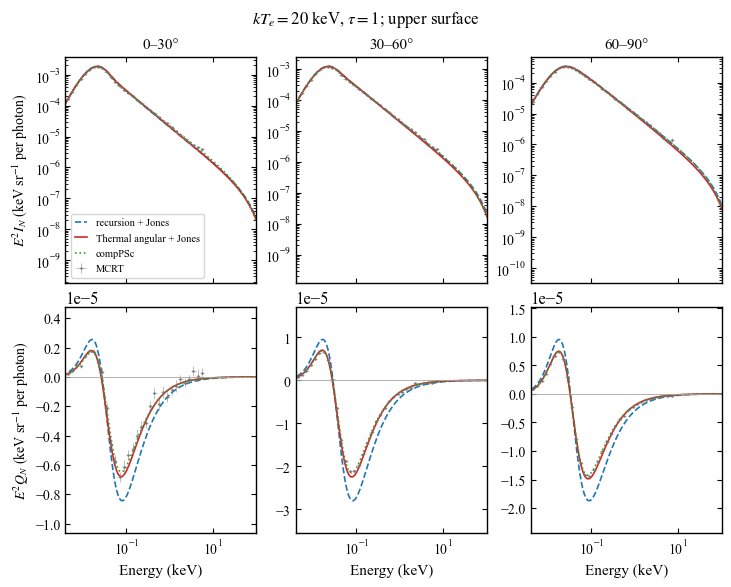

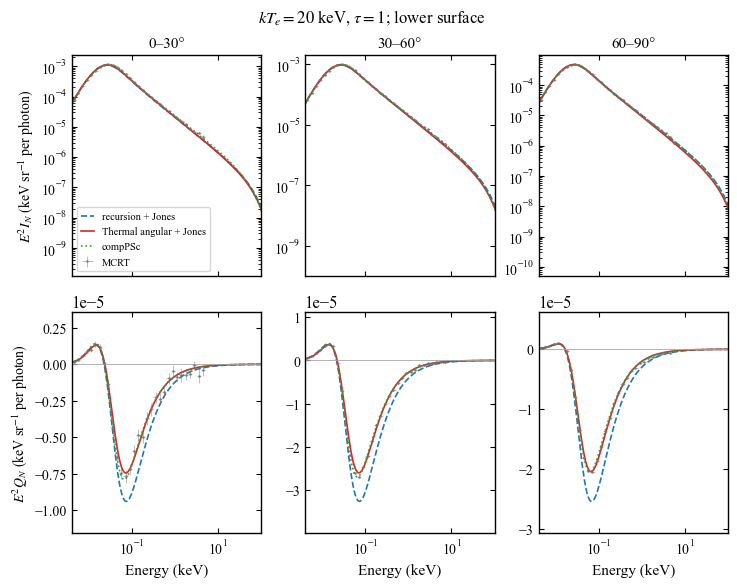

In [2]:
plot_comparison(1)

### 17.3. $\tau=10$: upper and lower surfaces

We use identical conventions. The high-energy Q discrepancy, including an
incorrect sign in some angular ranges, is not removed by the thermal-angular
correction. The compPSc outputs satisfy their iteration criterion but are not
claimed to be globally frequency/angular-mesh certified.

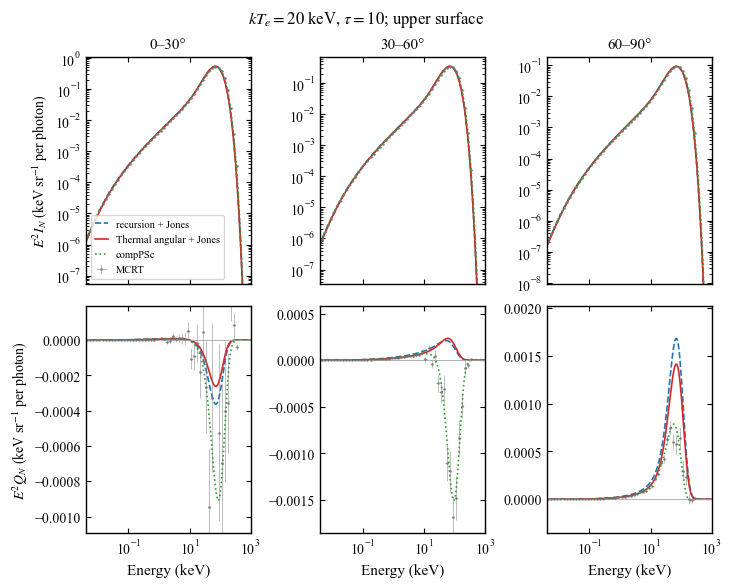

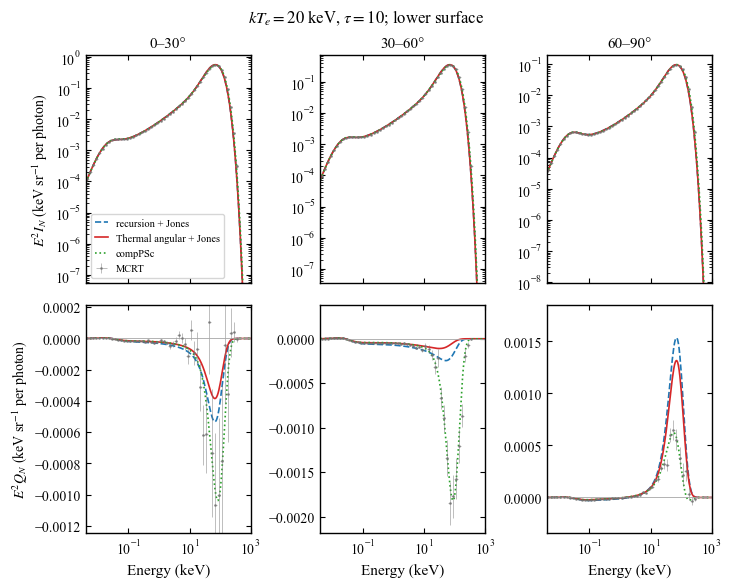

In [3]:
plot_comparison(10)

### 17.4. Fixed-normalization residuals and interpretation

We integrate each model into the exact MCRT energy bins before evaluating
$\chi^2/N=\sum_i[(M_i-D_i)/\sigma_i]^2/N$. We select bins with at least 50
photons, finite positive standard error, and $E^2I_N$ above $10^{-8}$ of its
MCRT peak. We retain signed Q without a Q-significance cut. We sum chi-square
and point counts across the three angular windows, separately for each surface.

The full 0.005–100 keV band and the separate 0.1–40 keV upscattered-band
diagnostic are both reported. These are fixed-model, diagonal-error diagnostics,
not refitted reduced chi-squares, fractional errors, or formal model-selection
probabilities. No physical parameter or normalization is optimized.

Q improves strongly in these tests, particularly at $\tau=1$. I is not uniformly
improved: a smaller aggregate residual in the upscattered band can coexist with
worse agreement in individual windows or over the full band. We infer that
thermal angular transport explains a substantial part of the cold-matrix Q
discrepancy, but not all of it. The remaining mismatch motivates a joint
energy–angle–polarization treatment; it does not identify one omitted effect
as its unique cause.

In [4]:
thermal_metric_rows = metric_rows()
thermal_headers = ['tau', 'Surface', 'Stokes', 'Band', 'N', 'Cold + Jones', 'Thermal angular + Jones', 'compPSc']
thermal_table = '| ' + ' | '.join(thermal_headers) + ' |\n'
thermal_table += '| ' + ' | '.join(['---']*len(thermal_headers)) + ' |\n'
thermal_table += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in thermal_metric_rows)
display(Markdown(thermal_table))

| tau | Surface | Stokes | Band | N | Cold + Jones | Thermal angular + Jones | compPSc |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | up | I | 0.005–100 keV | 95 | 2399.463 | 2312.740 | 3.319 |
| 1 | up | I | 0.1–40 keV | 56 | 69.145 | 50.368 | 2.436 |
| 1 | up | Q | 0.005–100 keV | 95 | 281.639 | 4.083 | 1.503 |
| 1 | up | Q | 0.1–40 keV | 56 | 181.153 | 3.134 | 0.966 |
| 1 | down | I | 0.005–100 keV | 93 | 2056.444 | 1959.333 | 3.763 |
| 1 | down | I | 0.1–40 keV | 54 | 32.609 | 17.669 | 2.663 |
| 1 | down | Q | 0.005–100 keV | 93 | 174.855 | 6.517 | 1.439 |
| 1 | down | Q | 0.1–40 keV | 54 | 184.350 | 2.542 | 1.115 |
| 10 | up | I | 0.005–100 keV | 129 | 291.726 | 362.058 | 1.608 |
| 10 | up | I | 0.1–40 keV | 78 | 291.081 | 206.174 | 1.159 |
| 10 | up | Q | 0.005–100 keV | 129 | 28.052 | 5.005 | 1.240 |
| 10 | up | Q | 0.1–40 keV | 78 | 20.859 | 2.363 | 1.293 |
| 10 | down | I | 0.005–100 keV | 129 | 977.778 | 1009.500 | 2.584 |
| 10 | down | I | 0.1–40 keV | 78 | 276.062 | 249.312 | 0.933 |
| 10 | down | Q | 0.005–100 keV | 129 | 71.014 | 6.171 | 1.314 |
| 10 | down | Q | 0.1–40 keV | 78 | 60.919 | 2.772 | 1.157 |

## 18. Higher-temperature I/Q spectra and polarization plateaus

We extend the displayed energy range of the existing $kT_e=20$ keV case and
add the archived $50$ keV three-way benchmark, both at total $\tau=1$.
We retain 5 eV blackbody seeds, Lambert lower-boundary injection, both surfaces
and the three finite angular windows. Each MCRT calculation contains 400 million
histories in 40 independent batches. These are cached calculations; we do not
rerun MCRT, compPSc, recursion, or fitting and do not save new figures.

Columns show $E^2I_N$, signed $E^2Q_N$ (keV per injected photon per sr), and
$\Pi=Q_N/I_N$ in percent. The angular convention is identical to earlier sections.
For the older 50 keV MCRT export we reverse Q and Pi once to obtain the manuscript
basis; uncertainties are unchanged. Pi errors retain the batch I/Q covariance.

We use **0.004–1000 keV** on the horizontal axes so that a plateau is not hidden
by a prematurely truncated energy range. We also retain departures from the
plateau near the cutoff: an energy-independent high-order Thomson polarization
does not require full Compton transport to remain flat at arbitrarily high energy.
For model Pi we omit bins with $E^2I_N$ below $10^{-12}$ of that window's peak;
for MCRT Pi we require at least 100 photons and the saved support mask
(at least 50 photons in at least eight occupied batches). Thus a deterministic
tail is not presented as a statistically resolved MCRT plateau. Error bars may
extend beyond the model-based y limits.

The recursion retains the **stationary-electron Thomson** matrix, not the
thermal-angular diagnostic in Section 17. compPSc is iteration-converged but
does not have a global frequency/angular mesh certificate. We do not bundle
100/150 keV as three-way validations because matching MCRT results have not
been identified for those cases.

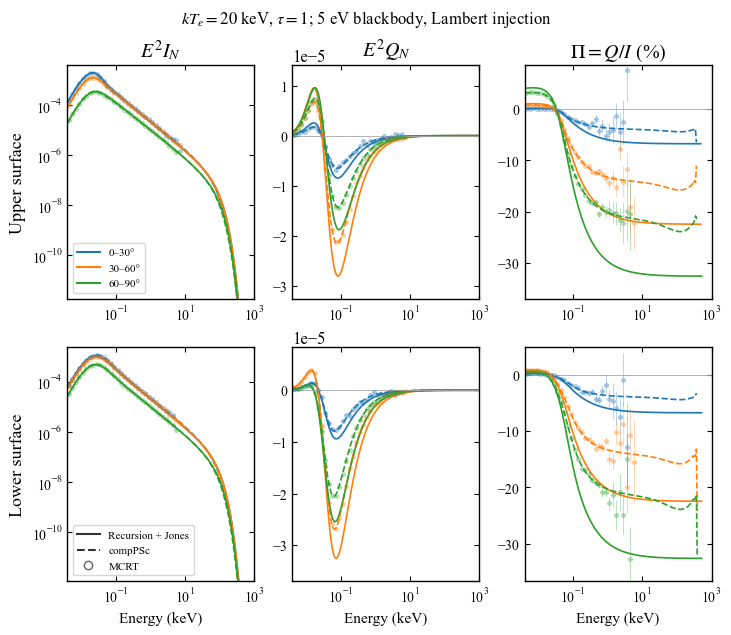

20 keV: 400,000,000 MCRT histories; fixed normalization; no new simulations or figure exports.


In [1]:
from helpers.hot_spectra import plot_hot_case
plot_hot_case(20)

### 18.1. Archived 50 keV benchmark

We show the same diagnostics and masks at 50 keV, without modifying the original simulation outputs.

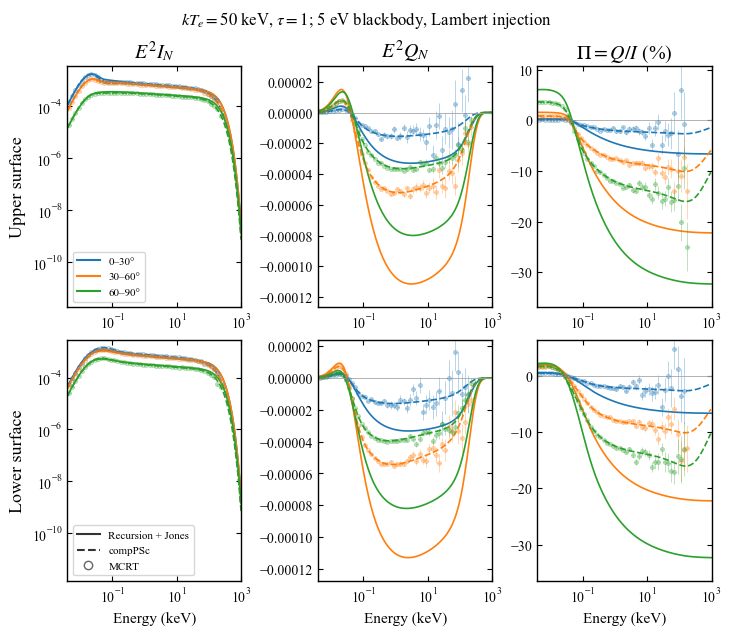

50 keV: 400,000,000 MCRT histories; fixed normalization; no new simulations or figure exports.


In [2]:
plot_hot_case(50)